<a href="https://colab.research.google.com/github/2001020057-tech/Yamet-NaiveBayes/blob/main/Yamet_CATEGORICAL_NB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [171]:

# ============================================================
# CELL 1: MOUNT GOOGLE DRIVE & IMPORT LIBRARY
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

# Library pengolahan data
import os
import zipfile
import warnings
import numpy as np
import pandas as pd

# Library preprocessing
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split

# Library Machine Learning
from sklearn.naive_bayes import CategoricalNB

# Library evaluasi
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Library visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

print("Google Drive berhasil terhubung.")
print("Library berhasil diimpor.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive berhasil terhubung.
Library berhasil diimpor.


In [172]:

# ============================================================
# CELL 2: MENENTUKAN FOLDER KERJA
# ============================================================

BASE_DIR = '/content/drive/MyDrive/Proyek_Naive_Bayes_Yamet'

DATASET_PATH = os.path.join(
    BASE_DIR,
    'dataset_final_harmonized_v2.csv'
)

# Memastikan folder tersedia
if not os.path.exists(BASE_DIR):
    raise FileNotFoundError(
        f"Folder tidak ditemukan: {BASE_DIR}"
    )

# Memastikan file dataset tersedia
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATASET_PATH}"
    )

print("Folder kerja:", BASE_DIR)
print("File dataset:", DATASET_PATH)


# ============================================================
# OPSIONAL: EKSTRAKSI FILE ZIP DATA MENTAH
# Jalankan hanya jika memang diperlukan.
# ============================================================

# ZIP_FILES = [
#     'RAHASIA.ZIP',
#     'RAHASIA_2.ZIP'
# ]
#
# for zip_name in ZIP_FILES:
#     zip_path = os.path.join(BASE_DIR, zip_name)
#
#     if os.path.exists(zip_path):
#         with zipfile.ZipFile(zip_path, 'r') as zip_ref:
#             zip_ref.extractall(
#                 os.path.join(BASE_DIR, 'data_mentah')
#             )
#         print(f"Berhasil mengekstrak: {zip_name}")
#     else:
#         print(f"File tidak ditemukan: {zip_name}")


Folder kerja: /content/drive/MyDrive/Proyek_Naive_Bayes_Yamet
File dataset: /content/drive/MyDrive/Proyek_Naive_Bayes_Yamet/dataset_final_harmonized_v2.csv


In [173]:
# ============================================================
# CELL 3: LOAD DATASET
# ============================================================

df = pd.read_csv(DATASET_PATH)

print("Dataset berhasil dibaca.")
print("=" * 60)

print("Ukuran dataset:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nTipe data setiap kolom:")
print(df.dtypes)

print("\nInformasi struktur dataset:")
df.info()

Dataset berhasil dibaca.
Ukuran dataset: (67, 40)

Nama kolom:
['record_id', 'batch_id', 'source_file', 'nama_inisial', 'usia_total_bulan', 'jenis_kelamin', 'kontak_mata', 'respon_panggil_nama', 'pemahaman_instruksi_reseptif', 'kemampuan_bicara_ekspresif', 'perilaku_repetitif_stimming', 'sensory_processing_disorder', 'hiperaktivitas_impulsivitas', 'gangguan_fokus_atensi', 'tantrum_regulasi_emosi', 'dispraksia_motorik', 'oromotor_bermasalah', 'denver_personal_sosial', 'denver_motorik_halus', 'denver_bahasa', 'denver_motorik_kasar', 'kemandirian_adl', 'skor_stp_ya', 'skor_afls', 'diagnosis_label', 'level_label', 'level_system', 'diag_tambahan_language_disorder', 'diag_tambahan_speech_sound_disorder', 'diag_tambahan_social_pragmatic_comm', 'diag_tambahan_sensory_processing_disorder', 'diag_tambahan_dispraksia_dcd', 'diag_tambahan_ketidakmatangan_oromotor', 'diag_tambahan_regulasi_emosi_perilaku', 'diag_tambahan_intellectual_disability_gdd', 'diag_tambahan_specific_learning_disorder', 'dia

Jumlah target kosong: 0

Distribusi Diagnosis:
diagnosis_label
Autism Spectrum Disorder                    37
Attention-Deficit/Hyperactivity Disorder    17
Language Disorder                           12
Kondisi Perkembangan Lain                    1
Name: count, dtype: int64

Persentase setiap kelas (%):
diagnosis_label
Autism Spectrum Disorder                    55.223881
Attention-Deficit/Hyperactivity Disorder    25.373134
Language Disorder                           17.910448
Kondisi Perkembangan Lain                    1.492537
Name: proportion, dtype: float64

Missing Values:


,Jumlah Missing,Persentase Missing (%)
skor_afls,67,100.000000
skor_stp_ya,66,98.507463
diagnosis_naratif_dokumen,1,1.492537
record_id,0,0.000000
usia_total_bulan,0,0.000000
batch_id,0,0.000000
source_file,0,0.000000
nama_inisial,0,0.000000
respon_panggil_nama,0,0.000000
kontak_mata,0,0.000000


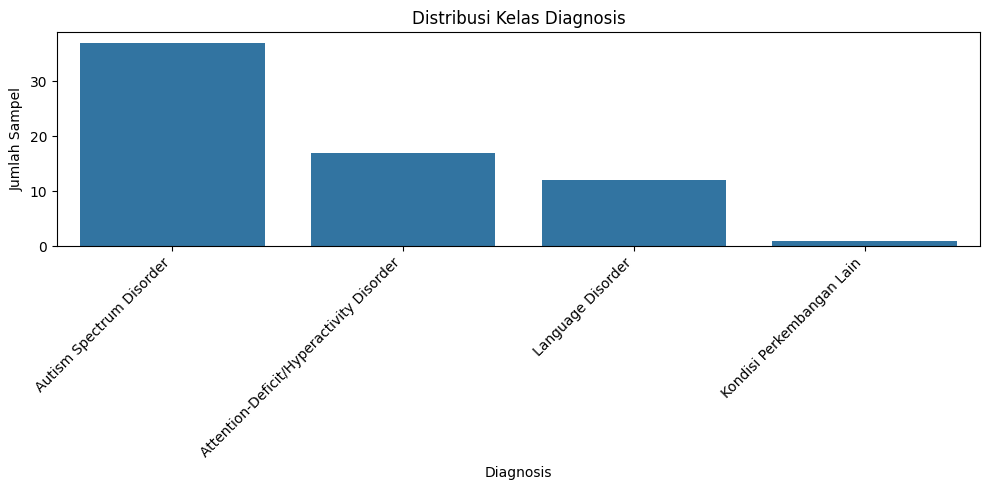

In [174]:
# ============================================================
# CELL 4: EXPLORATORY DATA CHECK
# ============================================================

# Memastikan target tersedia
TARGET = 'diagnosis_label'

if TARGET not in df.columns:
    raise ValueError(
        f"Kolom target '{TARGET}' tidak ditemukan."
    )

# Memisahkan target yang tersedia
target_valid = df[TARGET].dropna()

if target_valid.empty:
    raise ValueError(
        "Kolom target tidak memiliki data diagnosis yang valid."
    )

# Pemeriksaan target kosong
print("Jumlah target kosong:", df[TARGET].isnull().sum())

# Distribusi kelas diagnosis
diagnosis_counts = target_valid.value_counts()

print("\nDistribusi Diagnosis:")
print(diagnosis_counts)

# Persentase setiap kelas
print("\nPersentase setiap kelas (%):")
print(
    target_valid.value_counts(normalize=True) * 100
)

# Pemeriksaan missing values
missing = pd.DataFrame({
    'Jumlah Missing': df.isnull().sum(),
    'Persentase Missing (%)': df.isnull().mean() * 100
})

print("\nMissing Values:")
display(
    missing.sort_values(
        by='Persentase Missing (%)',
        ascending=False
    )
)

# Visualisasi distribusi diagnosis
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x=TARGET,
    order=diagnosis_counts.index
)

plt.title('Distribusi Kelas Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Jumlah Sampel')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [175]:
# ============================================================
# CELL 5: MENGHAPUS KOLOM IDENTITAS DAN METADATA
# ============================================================

drop_columns = [
    'record_id',
    'batch_id',
    'source_file',
    'nama_inisial',
    'diagnosis_naratif_dokumen',
    'level_system',
    'skor_stp_ya',
    'skor_afls'
]

# Hanya menghapus kolom yang tersedia
existing_drop_columns = [
    col for col in drop_columns if col in df.columns
]

# Memastikan target tidak ikut terhapus
if TARGET in existing_drop_columns:
    raise ValueError(
        "Kolom target tidak boleh dihapus."
    )

# Menghapus kolom identitas dan metadata
df = df.drop(columns=existing_drop_columns)

print("Kolom identitas dan metadata berhasil diperiksa.")
print("Jumlah kolom yang dihapus:", len(existing_drop_columns))
print("Ukuran dataset setelah penghapusan:", df.shape)

Kolom identitas dan metadata berhasil diperiksa.
Jumlah kolom yang dihapus: 8
Ukuran dataset setelah penghapusan: (67, 32)


In [176]:
# ============================================================
# CELL 6: MEMBERSIHKAN TARGET
# ============================================================

# Mencatat jumlah data sebelum pembersihan
jumlah_awal = len(df)

# Menghapus baris yang tidak mempunyai diagnosis
df = df.dropna(subset=[TARGET]).copy()

# Mengubah target menjadi string dan menghapus spasi
df[TARGET] = df[TARGET].astype(str).str.strip()

# Menghapus label kosong dan teks yang mewakili nilai kosong
invalid_labels = ['', 'nan', 'none', 'null']

df = df[
    ~df[TARGET].str.lower().isin(invalid_labels)
].copy()

# Memastikan dataset masih memiliki data valid
if df.empty:
    raise ValueError(
        "Tidak terdapat data dengan label diagnosis yang valid."
    )

# Ringkasan hasil pembersihan
jumlah_akhir = len(df)
jumlah_terhapus = jumlah_awal - jumlah_akhir

print("Pembersihan target berhasil.")
print("Jumlah data sebelum pembersihan:", jumlah_awal)
print("Jumlah data setelah pembersihan:", jumlah_akhir)
print("Jumlah data yang dihapus:", jumlah_terhapus)

print("\nDistribusi kelas diagnosis:")
print(df[TARGET].value_counts())

print("\nJumlah kelas diagnosis:", df[TARGET].nunique())

Pembersihan target berhasil.
Jumlah data sebelum pembersihan: 67
Jumlah data setelah pembersihan: 67
Jumlah data yang dihapus: 0

Distribusi kelas diagnosis:
diagnosis_label
Autism Spectrum Disorder                    37
Attention-Deficit/Hyperactivity Disorder    17
Language Disorder                           12
Kondisi Perkembangan Lain                    1
Name: count, dtype: int64

Jumlah kelas diagnosis: 4


In [177]:
# ============================================================
# CELL 7: DISKRETISASI USIA
# ============================================================

# Memastikan kolom usia tersedia
if 'usia_total_bulan' not in df.columns:
    raise ValueError(
        "Kolom 'usia_total_bulan' tidak ditemukan."
    )

# Mengubah usia menjadi numerik
usia = pd.to_numeric(
    df['usia_total_bulan'],
    errors='coerce'
)

# Memeriksa nilai usia yang tidak valid
invalid_age = (
    usia.isna() |
    ~np.isfinite(usia) |
    (usia < 0)
)

if invalid_age.any():
    raise ValueError(
        f"Ditemukan {invalid_age.sum()} data usia kosong "
        "atau tidak valid. Periksa dataset sebelum melanjutkan."
    )

# Membentuk kategori usia
bins = [-np.inf, 60, 144, np.inf]

labels = [
    'Balita',
    'Anak-anak',
    'Remaja_Dewasa'
]

df['kelompok_usia'] = pd.cut(
    usia,
    bins=bins,
    labels=labels,
    right=True
)

# Memastikan seluruh usia berhasil dikategorikan
if df['kelompok_usia'].isna().any():
    raise ValueError(
        "Terdapat usia yang belum berhasil dikategorikan."
    )

# Menghapus usia numerik kontinu
df.drop(
    columns=['usia_total_bulan'],
    inplace=True
)

print("Diskretisasi usia berhasil.")
print("\nDistribusi kelompok usia:")
print(df['kelompok_usia'].value_counts())

print("\nKategori usia yang terbentuk:")
print(df['kelompok_usia'].cat.categories.tolist())

Diskretisasi usia berhasil.

Distribusi kelompok usia:
kelompok_usia
Remaja_Dewasa    25
Balita           24
Anak-anak        18
Name: count, dtype: int64

Kategori usia yang terbentuk:
['Balita', 'Anak-anak', 'Remaja_Dewasa']


In [178]:
# ============================================================
# CELL 8: MEMISAHKAN FITUR DAN TARGET (18 FITUR FINAL)
# ============================================================

# Membuat salinan dataset hasil preprocessing
df_clean = df.copy()

# Memastikan target tersedia
if TARGET not in df_clean.columns:
    raise ValueError(
        f"Kolom target '{TARGET}' tidak ditemukan."
    )

# ------------------------------------------------------------
# 1. Menentukan 18 fitur prediktor final
# ------------------------------------------------------------

FEATURE_COLUMNS = [
    'jenis_kelamin',
    'kontak_mata',
    'respon_panggil_nama',
    'pemahaman_instruksi_reseptif',
    'kemampuan_bicara_ekspresif',
    'perilaku_repetitif_stimming',
    'sensory_processing_disorder',
    'hiperaktivitas_impulsivitas',
    'gangguan_fokus_atensi',
    'tantrum_regulasi_emosi',
    'dispraksia_motorik',
    'oromotor_bermasalah',
    'denver_personal_sosial',
    'denver_motorik_halus',
    'denver_bahasa',
    'denver_motorik_kasar',
    'kemandirian_adl',
    'kelompok_usia'
]

# ------------------------------------------------------------
# 2. Validasi ketersediaan fitur
# ------------------------------------------------------------

missing_features = [
    col for col in FEATURE_COLUMNS
    if col not in df_clean.columns
]

if missing_features:
    raise ValueError(
        f"Fitur berikut tidak ditemukan: {missing_features}"
    )

if len(FEATURE_COLUMNS) != 18:
    raise ValueError(
        "Jumlah fitur final harus tepat 18."
    )

# ------------------------------------------------------------
# 3. Memisahkan kolom yang tidak digunakan
# ------------------------------------------------------------

unused_columns = [
    col for col in df_clean.columns
    if col not in FEATURE_COLUMNS and col != TARGET
]

# ------------------------------------------------------------
# 4. Memisahkan fitur dan target
# ------------------------------------------------------------

X = df_clean[FEATURE_COLUMNS].copy()
y = df_clean[TARGET].copy()

# ------------------------------------------------------------
# 5. Validasi hasil pemisahan
# ------------------------------------------------------------

assert X.shape[1] == 18
assert TARGET not in X.columns
assert len(X) == len(y)

# ------------------------------------------------------------
# 6. Menampilkan ringkasan
# ------------------------------------------------------------

print("=" * 60)
print("PEMISAHAN FITUR DAN TARGET BERHASIL")
print("=" * 60)

print("Jumlah sampel:", len(X))
print("Jumlah fitur:", X.shape[1])

print("\nDaftar 18 fitur final:")
for i, col in enumerate(X.columns, start=1):
    print(f"{i}. {col}")

print("\nJumlah kolom yang tidak digunakan:", len(unused_columns))
print("Kolom yang tidak digunakan:")
print(unused_columns)

print("\nDistribusi target:")
print(y.value_counts())

print("\nFitur dan target siap digunakan.")

PEMISAHAN FITUR DAN TARGET BERHASIL
Jumlah sampel: 67
Jumlah fitur: 18

Daftar 18 fitur final:
1. jenis_kelamin
2. kontak_mata
3. respon_panggil_nama
4. pemahaman_instruksi_reseptif
5. kemampuan_bicara_ekspresif
6. perilaku_repetitif_stimming
7. sensory_processing_disorder
8. hiperaktivitas_impulsivitas
9. gangguan_fokus_atensi
10. tantrum_regulasi_emosi
11. dispraksia_motorik
12. oromotor_bermasalah
13. denver_personal_sosial
14. denver_motorik_halus
15. denver_bahasa
16. denver_motorik_kasar
17. kemandirian_adl
18. kelompok_usia

Jumlah kolom yang tidak digunakan: 13
Kolom yang tidak digunakan:
['level_label', 'diag_tambahan_language_disorder', 'diag_tambahan_speech_sound_disorder', 'diag_tambahan_social_pragmatic_comm', 'diag_tambahan_sensory_processing_disorder', 'diag_tambahan_dispraksia_dcd', 'diag_tambahan_ketidakmatangan_oromotor', 'diag_tambahan_regulasi_emosi_perilaku', 'diag_tambahan_intellectual_disability_gdd', 'diag_tambahan_specific_learning_disorder', 'diag_tambahan_odd

In [179]:
# ============================================================
# CELL 9: TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=None
)

print("Pembagian dataset berhasil.")
print("=" * 60)

print("Jumlah sampel:", len(X))
print("Jumlah fitur:", X.shape[1])

print("\nData latih:", X_train.shape)
print("Data uji:", X_test.shape)

print("\nDistribusi target data latih:")
print(y_train.value_counts())

print("\nDistribusi target data uji:")
print(y_test.value_counts())

Pembagian dataset berhasil.
Jumlah sampel: 67
Jumlah fitur: 18

Data latih: (53, 18)
Data uji: (14, 18)

Distribusi target data latih:
diagnosis_label
Autism Spectrum Disorder                    29
Attention-Deficit/Hyperactivity Disorder    12
Language Disorder                           11
Kondisi Perkembangan Lain                    1
Name: count, dtype: int64

Distribusi target data uji:
diagnosis_label
Autism Spectrum Disorder                    8
Attention-Deficit/Hyperactivity Disorder    5
Language Disorder                           1
Name: count, dtype: int64


In [180]:
# ============================================================
# CELL 10: PREPROCESSING DAN ORDINAL ENCODING
# ============================================================

# ------------------------------------------------------------
# 1. Salin data latih dan data uji
# ------------------------------------------------------------

X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

# Memastikan susunan fitur konsisten
if list(X_train_processed.columns) != list(X_test_processed.columns):
    raise ValueError(
        "Susunan fitur data latih dan data uji tidak konsisten."
    )

# Memastikan jumlah fitur sesuai konfigurasi penelitian
if X_train_processed.shape[1] != 18:
    raise ValueError(
        f"Jumlah fitur seharusnya 18, tetapi ditemukan "
        f"{X_train_processed.shape[1]} fitur."
    )

# ------------------------------------------------------------
# 2. Memeriksa missing values
# ------------------------------------------------------------

missing_train = X_train_processed.isnull().sum().sum()
missing_test = X_test_processed.isnull().sum().sum()

if missing_train > 0 or missing_test > 0:
    raise ValueError(
        "Ditemukan missing values pada fitur. "
        "Periksa dataset sebelum melakukan encoding."
    )

# ------------------------------------------------------------
# 3. Mengubah tipe data menjadi object
# ------------------------------------------------------------

X_train_processed = X_train_processed.astype(object)
X_test_processed = X_test_processed.astype(object)

# ------------------------------------------------------------
# 4. Konversi seluruh fitur menjadi string
# ------------------------------------------------------------

for col in X_train_processed.columns:

    X_train_processed[col] = (
        X_train_processed[col].astype(str).str.strip()
    )

    X_test_processed[col] = (
        X_test_processed[col].astype(str).str.strip()
    )

# ------------------------------------------------------------
# 5. Ordinal Encoding
# ------------------------------------------------------------

encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train_encoded = encoder.fit_transform(
    X_train_processed
)

X_test_encoded = encoder.transform(
    X_test_processed
)

# Menghitung kategori baru yang ditemukan pada data uji
unknown_count = int((X_test_encoded == -1).sum())

# ------------------------------------------------------------
# 6. Mengubah hasil encoding menjadi integer nonnegatif
# ------------------------------------------------------------

# Kategori dikenal dimulai dari 1.
# Kategori baru pada data uji menggunakan kode 0.

X_train_processed = pd.DataFrame(
    X_train_encoded.astype(int) + 1,
    columns=X_train.columns,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_encoded.astype(int) + 1,
    columns=X_test.columns,
    index=X_test.index
)

# ------------------------------------------------------------
# 7. Validasi hasil preprocessing
# ------------------------------------------------------------

assert not X_train_processed.isnull().any().any()
assert not X_test_processed.isnull().any().any()

assert (X_train_processed.values >= 0).all()
assert (X_test_processed.values >= 0).all()

assert np.issubdtype(
    X_train_processed.values.dtype, np.integer
)

assert np.issubdtype(
    X_test_processed.values.dtype, np.integer
)

# ------------------------------------------------------------
# 8. Ringkasan hasil preprocessing
# ------------------------------------------------------------

print("=" * 60)
print("PREPROCESSING DAN ENCODING BERHASIL")
print("=" * 60)

print("\nJumlah fitur:", X_train_processed.shape[1])
print("Data latih:", X_train_processed.shape)
print("Data uji:", X_test_processed.shape)

print("\nJumlah kategori baru pada data uji:", unknown_count)

print("\nJumlah missing values setelah encoding:")
print("Train:", X_train_processed.isnull().sum().sum())
print("Test :", X_test_processed.isnull().sum().sum())

print("\nNilai minimum:", X_train_processed.min().min())
print("Nilai maksimum:", X_train_processed.max().max())

print("\nEncoding selesai dan siap digunakan.")

PREPROCESSING DAN ENCODING BERHASIL

Jumlah fitur: 18
Data latih: (53, 18)
Data uji: (14, 18)

Jumlah kategori baru pada data uji: 0

Jumlah missing values setelah encoding:
Train: 0
Test : 0

Nilai minimum: 1
Nilai maksimum: 3

Encoding selesai dan siap digunakan.


In [181]:
# ============================================================
# CELL 10.2: MENGHAPUS FITUR POTENSI DATA LEAKAGE
# ============================================================

# 1. Kolom yang harus dikeluarkan
drop_leakage = [
    'level_label'
]

# 2. Mengidentifikasi seluruh fitur diagnosis tambahan
diag_tambahan_columns = [
    col for col in df.columns
    if col.startswith('diag_tambahan_')
]

# 3. Menggabungkan daftar kolom
columns_to_remove = list(dict.fromkeys(
    drop_leakage + diag_tambahan_columns
))

# 4. Memastikan target tidak ikut terhapus
if TARGET in columns_to_remove:
    raise ValueError(
        "Kolom target tidak boleh dihapus."
    )

# 5. Hanya menghapus kolom yang tersedia
columns_to_remove = [
    col for col in columns_to_remove
    if col in df.columns
]

# 6. Membentuk dataset bersih
df_clean = df.drop(
    columns=columns_to_remove
).copy()

# 7. Validasi target
if TARGET not in df_clean.columns:
    raise ValueError(
        "Kolom target tidak ditemukan setelah pembersihan."
    )

# 8. Validasi fitur leakage
remaining_leakage = [
    col for col in df_clean.columns
    if col == 'level_label'
    or col.startswith('diag_tambahan_')
]

if remaining_leakage:
    raise ValueError(
        f"Masih ditemukan fitur leakage: {remaining_leakage}"
    )

# 9. Ringkasan hasil
print("=" * 60)
print("PEMBERSIHAN FITUR POTENSI DATA LEAKAGE BERHASIL")
print("=" * 60)

print("\nJumlah kolom yang dihapus:", len(columns_to_remove))

print("\nKolom yang dihapus:")
for col in columns_to_remove:
    print("-", col)

print("\nJumlah kolom sebelum:", df.shape[1])
print("Jumlah kolom sesudah:", df_clean.shape[1])

print("\nUkuran dataset bersih:", df_clean.shape)
print("Fitur leakage tersisa:", len(remaining_leakage))

PEMBERSIHAN FITUR POTENSI DATA LEAKAGE BERHASIL

Jumlah kolom yang dihapus: 13

Kolom yang dihapus:
- level_label
- diag_tambahan_language_disorder
- diag_tambahan_speech_sound_disorder
- diag_tambahan_social_pragmatic_comm
- diag_tambahan_sensory_processing_disorder
- diag_tambahan_dispraksia_dcd
- diag_tambahan_ketidakmatangan_oromotor
- diag_tambahan_regulasi_emosi_perilaku
- diag_tambahan_intellectual_disability_gdd
- diag_tambahan_specific_learning_disorder
- diag_tambahan_odd_conduct_disorder
- diag_tambahan_inatensi_hiperaktivitas
- diag_tambahan_sosial_kemandirian

Jumlah kolom sebelum: 32
Jumlah kolom sesudah: 19

Ukuran dataset bersih: (67, 19)
Fitur leakage tersisa: 0


In [182]:
# ============================================================
# CELL 11: VALIDASI FINAL DATASET SEBELUM TRAINING
# ============================================================

print("=" * 60)
print("VALIDASI FINAL DATASET")
print("=" * 60)

# ------------------------------------------------------------
# 1. Validasi keberadaan fitur dan target
# ------------------------------------------------------------

required_columns = FEATURE_COLUMNS + [TARGET]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {missing_columns}"
    )

# ------------------------------------------------------------
# 2. Validasi jumlah sampel dan fitur
# ------------------------------------------------------------

if len(df_clean) != 67:
    raise ValueError(
        f"Jumlah sampel seharusnya 67, "
        f"tetapi ditemukan {len(df_clean)}."
    )

if X.shape[1] != 18:
    raise ValueError(
        f"Jumlah fitur seharusnya 18, "
        f"tetapi ditemukan {X.shape[1]}."
    )

# ------------------------------------------------------------
# 3. Validasi kesesuaian fitur
# ------------------------------------------------------------

if list(X.columns) != FEATURE_COLUMNS:
    raise ValueError(
        "Susunan fitur tidak sesuai dengan konfigurasi final."
    )

if not X.index.equals(y.index):
    raise ValueError(
        "Indeks fitur dan target tidak konsisten."
    )

if len(X) != len(df_clean) or len(y) != len(df_clean):
    raise ValueError(
        "Jumlah sampel dataset, fitur, dan target tidak konsisten."
    )

# ------------------------------------------------------------
# 4. Validasi potensi data leakage
# ------------------------------------------------------------

leakage_features = [
    col for col in X.columns
    if col == 'level_label'
    or col.startswith('diag_tambahan_')
]

if leakage_features:
    raise ValueError(
        f"Ditemukan fitur berpotensi leakage: {leakage_features}"
    )

# ------------------------------------------------------------
# 5. Pemeriksaan missing values
# ------------------------------------------------------------

missing_summary = df_clean[
    required_columns
].isnull().sum()

total_missing = missing_summary.sum()

print("\nPemeriksaan missing values:")
print(missing_summary)

if total_missing > 0:
    raise ValueError(
        f"Ditemukan {total_missing} missing values. "
        "Periksa dataset sebelum training."
    )

# ------------------------------------------------------------
# 6. Validasi distribusi target
# ------------------------------------------------------------

if y.nunique() != 4:
    raise ValueError(
        f"Jumlah kelas seharusnya 4, "
        f"tetapi ditemukan {y.nunique()}."
    )

print("\nDistribusi diagnosis:")
print(y.value_counts())

# ------------------------------------------------------------
# 7. Ringkasan validasi
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("HASIL VALIDASI FINAL")
print("=" * 60)

print("Jumlah sampel:", len(df_clean))
print("Jumlah fitur:", X.shape[1])
print("Jumlah kelas diagnosis:", y.nunique())
print("Total missing values:", total_missing)
print("Jumlah fitur leakage:", len(leakage_features))

print("\nValidasi final dataset berhasil.")
print("Dataset siap digunakan untuk training.")

VALIDASI FINAL DATASET

Pemeriksaan missing values:
jenis_kelamin                   0
kontak_mata                     0
respon_panggil_nama             0
pemahaman_instruksi_reseptif    0
kemampuan_bicara_ekspresif      0
perilaku_repetitif_stimming     0
sensory_processing_disorder     0
hiperaktivitas_impulsivitas     0
gangguan_fokus_atensi           0
tantrum_regulasi_emosi          0
dispraksia_motorik              0
oromotor_bermasalah             0
denver_personal_sosial          0
denver_motorik_halus            0
denver_bahasa                   0
denver_motorik_kasar            0
kemandirian_adl                 0
kelompok_usia                   0
diagnosis_label                 0
dtype: int64

Distribusi diagnosis:
diagnosis_label
Autism Spectrum Disorder                    37
Attention-Deficit/Hyperactivity Disorder    17
Language Disorder                           12
Kondisi Perkembangan Lain                    1
Name: count, dtype: int64

HASIL VALIDASI FINAL
Jumlah sampel:

In [183]:
# ============================================================
# CELL 12: AUDIT DISTRIBUSI KELAS TRAINING DAN TESTING
# ============================================================

print("=" * 65)
print("AUDIT DISTRIBUSI KELAS TRAINING DAN TESTING")
print("=" * 65)

# ------------------------------------------------------------
# 1. Distribusi kelas
# ------------------------------------------------------------

print("\nDISTRIBUSI DATA TRAINING:")
print(y_train.value_counts())

print("\nDISTRIBUSI DATA TESTING:")
print(y_test.value_counts())

# ------------------------------------------------------------
# 2. Jumlah kelas
# ------------------------------------------------------------

print("\nJUMLAH KELAS PADA TRAINING:")
print(y_train.nunique())

print("\nJUMLAH KELAS PADA TESTING:")
print(y_test.nunique())

# ------------------------------------------------------------
# 3. Membandingkan kelas training dan testing
# ------------------------------------------------------------

kelas_train = set(y_train.dropna().unique())
kelas_test = set(y_test.dropna().unique())

# Kelas pada testing yang tidak tersedia di training
kelas_test_tidak_ada_di_train = kelas_test - kelas_train

# Kelas pada training yang tidak muncul di testing
kelas_train_tidak_ada_di_test = kelas_train - kelas_test

print("\nKELAS TESTING YANG TIDAK TERDAPAT PADA TRAINING:")
print(sorted(kelas_test_tidak_ada_di_train))

print("\nKELAS TRAINING YANG TIDAK TERDAPAT PADA TESTING:")
print(sorted(kelas_train_tidak_ada_di_test))

# ------------------------------------------------------------
# 4. Menampilkan peringatan berdasarkan hasil audit
# ------------------------------------------------------------

if kelas_test_tidak_ada_di_train:
    print("\nPERINGATAN:")
    print(
        "Terdapat kelas pada testing yang tidak dipelajari "
        "oleh model melalui data training."
    )
else:
    print("\nSeluruh kelas testing tersedia pada training.")

if kelas_train_tidak_ada_di_test:
    print("\nCATATAN:")
    print(
        "Beberapa kelas training tidak memiliki sampel "
        "pada testing. Kinerja model untuk kelas tersebut "
        "tidak dapat dievaluasi menggunakan data testing."
    )
else:
    print("\nSeluruh kelas training terwakili pada testing.")

print("\n" + "=" * 65)
print("AUDIT DISTRIBUSI KELAS SELESAI")
print("=" * 65)

AUDIT DISTRIBUSI KELAS TRAINING DAN TESTING

DISTRIBUSI DATA TRAINING:
diagnosis_label
Autism Spectrum Disorder                    29
Attention-Deficit/Hyperactivity Disorder    12
Language Disorder                           11
Kondisi Perkembangan Lain                    1
Name: count, dtype: int64

DISTRIBUSI DATA TESTING:
diagnosis_label
Autism Spectrum Disorder                    8
Attention-Deficit/Hyperactivity Disorder    5
Language Disorder                           1
Name: count, dtype: int64

JUMLAH KELAS PADA TRAINING:
4

JUMLAH KELAS PADA TESTING:
3

KELAS TESTING YANG TIDAK TERDAPAT PADA TRAINING:
[]

KELAS TRAINING YANG TIDAK TERDAPAT PADA TESTING:
['Kondisi Perkembangan Lain']

Seluruh kelas testing tersedia pada training.

CATATAN:
Beberapa kelas training tidak memiliki sampel pada testing. Kinerja model untuk kelas tersebut tidak dapat dievaluasi menggunakan data testing.

AUDIT DISTRIBUSI KELAS SELESAI


In [184]:
# ============================================================
# CELL 13: TRAINING CATEGORICAL NAIVE BAYES
# ============================================================

from sklearn.naive_bayes import CategoricalNB

# ------------------------------------------------------------
# 1. Validasi data hasil encoding
# ------------------------------------------------------------

if X_train_processed.shape[1] != 18:
    raise ValueError(
        "Jumlah fitur data training harus 18."
    )

if X_test_processed.shape[1] != 18:
    raise ValueError(
        "Jumlah fitur data testing harus 18."
    )

if list(X_train_processed.columns) != list(X_test_processed.columns):
    raise ValueError(
        "Susunan fitur training dan testing tidak konsisten."
    )

if len(X_train_processed) != len(y_train):
    raise ValueError(
        "Jumlah data training dan target tidak konsisten."
    )

if len(X_test_processed) != len(y_test):
    raise ValueError(
        "Jumlah data testing dan target tidak konsisten."
    )

if (X_train_processed.values < 0).any():
    raise ValueError(
        "Ditemukan nilai negatif pada data training."
    )

if (X_test_processed.values < 0).any():
    raise ValueError(
        "Ditemukan nilai negatif pada data testing."
    )

# ------------------------------------------------------------
# 2. Menentukan jumlah kategori setiap fitur
# ------------------------------------------------------------

min_categories = [
    len(categories) + 1
    for categories in encoder.categories_
]

if len(min_categories) != X_train_processed.shape[1]:
    raise ValueError(
        "Jumlah kategori encoder tidak sesuai jumlah fitur."
    )

# ------------------------------------------------------------
# 3. Membuat model Categorical Naive Bayes
# ------------------------------------------------------------

model_cnb = CategoricalNB(
    alpha=1.0,
    min_categories=min_categories
)

# ------------------------------------------------------------
# 4. Training model
# ------------------------------------------------------------

model_cnb.fit(
    X_train_processed,
    y_train
)

# ------------------------------------------------------------
# 5. Prediksi data testing
# ------------------------------------------------------------

y_pred = model_cnb.predict(
    X_test_processed
)

# ------------------------------------------------------------
# 6. Menampilkan hasil training
# ------------------------------------------------------------

print("=" * 65)
print("HASIL TRAINING CATEGORICAL NAIVE BAYES")
print("=" * 65)

print("\nModel berhasil dilatih.")

print("Jumlah data training :", len(X_train_processed))
print("Jumlah data testing  :", len(X_test_processed))
print("Jumlah fitur         :", X_train_processed.shape[1])

print("\nParameter model:")
print("Alpha:", model_cnb.alpha)
print("Min categories:", model_cnb.min_categories)

print("\nKelas yang dipelajari model:")
print(model_cnb.classes_)

print("\nPrediksi data testing berhasil.")
print("Jumlah prediksi:", len(y_pred))

HASIL TRAINING CATEGORICAL NAIVE BAYES

Model berhasil dilatih.
Jumlah data training : 53
Jumlah data testing  : 14
Jumlah fitur         : 18

Parameter model:
Alpha: 1.0
Min categories: [3, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 3, 2, 2, 2, 4]

Kelas yang dipelajari model:
['Attention-Deficit/Hyperactivity Disorder' 'Autism Spectrum Disorder'
 'Kondisi Perkembangan Lain' 'Language Disorder']

Prediksi data testing berhasil.
Jumlah prediksi: 14


EVALUASI CATEGORICAL NAIVE BAYES

Accuracy: 0.7143 (71.43%)

Classification Report:
                                          precision    recall  f1-score   support

Attention-Deficit/Hyperactivity Disorder       1.00      0.40      0.57         5
                Autism Spectrum Disorder       0.67      1.00      0.80         8
               Kondisi Perkembangan Lain       0.00      0.00      0.00         0
                       Language Disorder       0.00      0.00      0.00         1

                                accuracy                           0.71        14
                               macro avg       0.42      0.35      0.34        14
                            weighted avg       0.74      0.71      0.66        14


Confusion Matrix:
[[2 3 0 0]
 [0 8 0 0]
 [0 0 0 0]
 [0 1 0 0]]


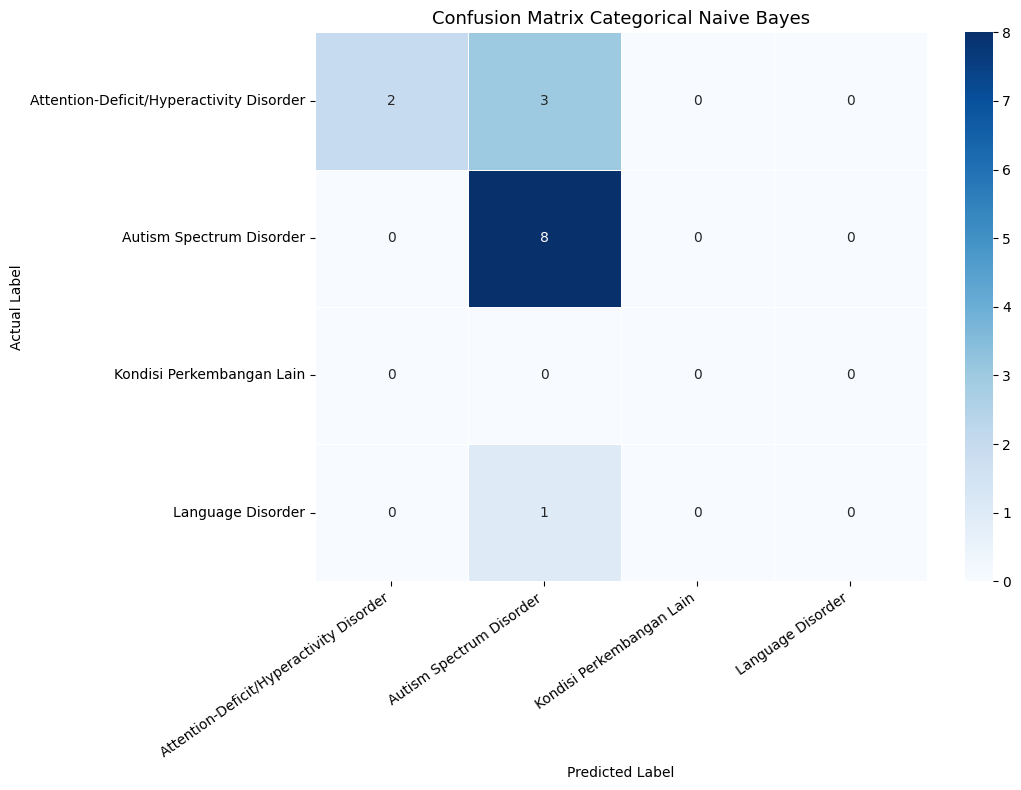

In [185]:
# ============================================================
# CELL 14: EVALUASI MODEL
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Validasi hasil prediksi
# ------------------------------------------------------------

if len(y_test) != len(y_pred):
    raise ValueError(
        "Jumlah data aktual dan hasil prediksi tidak sama."
    )

# Mengambil kelas yang dipelajari model
all_classes = model_cnb.classes_.tolist()

# Memastikan seluruh kelas aktual tersedia dalam model
unseen_classes = set(y_test.unique()) - set(all_classes)

if unseen_classes:
    raise ValueError(
        f"Terdapat kelas testing yang tidak dipelajari model: "
        f"{unseen_classes}"
    )

# ------------------------------------------------------------
# 2. Menghitung akurasi
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

# ------------------------------------------------------------
# 3. Menampilkan classification report
# ------------------------------------------------------------

print("=" * 65)
print("EVALUASI CATEGORICAL NAIVE BAYES")
print("=" * 65)

print(
    f"\nAccuracy: {accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print("\nClassification Report:")

report = classification_report(
    y_test,
    y_pred,
    labels=all_classes,
    zero_division=0
)

print(report)

# ------------------------------------------------------------
# 4. Membentuk confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=all_classes
)

print("\nConfusion Matrix:")
print(cm)

# ------------------------------------------------------------
# 5. Visualisasi confusion matrix
# ------------------------------------------------------------

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=all_classes,
    yticklabels=all_classes,
    linewidths=0.5
)

plt.title(
    "Confusion Matrix Categorical Naive Bayes",
    fontsize=13
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [186]:
# ============================================================
# CELL 15: ANALISIS DETAIL HASIL PREDIKSI
# ============================================================

import pandas as pd
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. Validasi hasil prediksi
# ------------------------------------------------------------

if len(y_test) != len(y_pred):
    raise ValueError(
        "Jumlah data aktual dan prediksi tidak sama."
    )

# ------------------------------------------------------------
# 2. Membentuk tabel hasil prediksi
# ------------------------------------------------------------

hasil_prediksi = pd.DataFrame({
    'Diagnosis_Aktual': y_test.to_numpy(),
    'Diagnosis_Prediksi': y_pred
})

hasil_prediksi['Status'] = (
    hasil_prediksi['Diagnosis_Aktual'] ==
    hasil_prediksi['Diagnosis_Prediksi']
).map({
    True: 'Benar',
    False: 'Salah'
})

# ------------------------------------------------------------
# 3. Menghitung jumlah prediksi benar dan salah
# ------------------------------------------------------------

jumlah_prediksi = (
    hasil_prediksi['Status']
    .value_counts()
    .reindex(['Benar', 'Salah'], fill_value=0)
)

print("=" * 65)
print("ANALISIS HASIL PREDIKSI CATEGORICAL NAIVE BAYES")
print("=" * 65)

print("\nRingkasan hasil prediksi:")
print(jumlah_prediksi)

print("\nTotal data pengujian:", len(hasil_prediksi))

# ------------------------------------------------------------
# 4. Membentuk confusion matrix
# ------------------------------------------------------------

all_classes = model_cnb.classes_.tolist()

cm_detail = confusion_matrix(
    y_test,
    y_pred,
    labels=all_classes
)

cm_df = pd.DataFrame(
    cm_detail,
    index=all_classes,
    columns=all_classes
)

print("\nConfusion Matrix:")
display(cm_df)

print("\nAnalisis hasil prediksi selesai.")

ANALISIS HASIL PREDIKSI CATEGORICAL NAIVE BAYES

Ringkasan hasil prediksi:
Status
Benar    10
Salah     4
Name: count, dtype: int64

Total data pengujian: 14

Confusion Matrix:


,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,Kondisi Perkembangan Lain,Language Disorder
Attention-Deficit/Hyperactivity Disorder,2,3,0,0
Autism Spectrum Disorder,0,8,0,0
Kondisi Perkembangan Lain,0,0,0,0
Language Disorder,0,1,0,0



Analisis hasil prediksi selesai.


In [187]:
# ============================================================
# CELL 16: AUDIT FITUR PADA PREDIKSI YANG SALAH
# ============================================================

# ------------------------------------------------------------
# 1. Validasi kesesuaian jumlah data
# ------------------------------------------------------------

if len(X_test) != len(hasil_prediksi):
    raise ValueError(
        "Jumlah data testing dan hasil prediksi tidak konsisten."
    )

# ------------------------------------------------------------
# 2. Menyamakan indeks berdasarkan urutan data
# ------------------------------------------------------------

X_test_reset = X_test.reset_index(drop=True)
hasil_prediksi_reset = hasil_prediksi.reset_index(drop=True)

# ------------------------------------------------------------
# 3. Mengidentifikasi prediksi yang salah
# ------------------------------------------------------------

mask_salah = (
    hasil_prediksi_reset['Status'] == 'Salah'
)

posisi_salah = mask_salah.to_numpy().nonzero()[0]

# ------------------------------------------------------------
# 4. Mengambil fitur asli dari data yang salah diprediksi
# ------------------------------------------------------------

audit_salah = X_test_reset.iloc[posisi_salah].copy()

# Menambahkan diagnosis aktual dan prediksi
audit_salah.insert(
    0,
    'Diagnosis_Aktual',
    hasil_prediksi_reset.loc[
        posisi_salah, 'Diagnosis_Aktual'
    ].to_numpy()
)

audit_salah.insert(
    1,
    'Diagnosis_Prediksi',
    hasil_prediksi_reset.loc[
        posisi_salah, 'Diagnosis_Prediksi'
    ].to_numpy()
)

# ------------------------------------------------------------
# 5. Ringkasan hasil audit
# ------------------------------------------------------------

print("=" * 65)
print("AUDIT FITUR PADA PREDIKSI YANG SALAH")
print("=" * 65)

print("\nJumlah data testing:", len(X_test))
print("Jumlah prediksi salah:", len(audit_salah))

print("\nAudit fitur berhasil dilakukan.")
print(
    "Detail diagnosis dan atribut individual tidak "
    "ditampilkan pada notebook publik."
)

AUDIT FITUR PADA PREDIKSI YANG SALAH

Jumlah data testing: 14
Jumlah prediksi salah: 4

Audit fitur berhasil dilakukan.
Detail diagnosis dan atribut individual tidak ditampilkan pada notebook publik.


In [188]:
# ============================================================
# CELL 17: PEMERIKSAAN DUPLIKASI FITUR
# ============================================================

print("=" * 65)
print("AUDIT DUPLIKASI DATASET")
print("=" * 65)

# ------------------------------------------------------------
# 1. Validasi kesesuaian data
# ------------------------------------------------------------

if not X.index.equals(y.index):
    raise ValueError(
        "Indeks fitur dan target tidak konsisten."
    )

# Menggabungkan fitur dan target
data_audit = X.copy()
data_audit[TARGET] = y

# ------------------------------------------------------------
# 2. Pemeriksaan duplikasi seluruh fitur dan target
# ------------------------------------------------------------

print("\n1. DUPLIKASI SELURUH FITUR DAN TARGET")

jumlah_duplikat_total = data_audit.duplicated(
    keep='first'
).sum()

jumlah_baris_terlibat = data_audit.duplicated(
    keep=False
).sum()

print(
    "Jumlah baris duplikat tambahan:",
    jumlah_duplikat_total
)

print(
    "Jumlah seluruh baris yang terlibat dalam duplikasi:",
    jumlah_baris_terlibat
)

# ------------------------------------------------------------
# 3. Pemeriksaan kombinasi fitur tanpa target
# ------------------------------------------------------------

print("\n2. DUPLIKASI FITUR TANPA TARGET")

# Mengelompokkan kombinasi fitur yang benar-benar muncul
grouped_features = (
    data_audit
    .groupby(
        FEATURE_COLUMNS,
        dropna=False,
        observed=True
    )[TARGET]
    .agg(['size', 'nunique'])
)

# Mengambil kombinasi fitur yang berulang
duplicate_groups = grouped_features[
    grouped_features['size'] > 1
]

jumlah_kombinasi_berulang = len(duplicate_groups)

jumlah_baris_berulang = int(
    duplicate_groups['size'].sum()
)

print(
    "Jumlah kombinasi fitur berulang:",
    jumlah_kombinasi_berulang
)

print(
    "Jumlah baris dalam kombinasi berulang:",
    jumlah_baris_berulang
)

# ------------------------------------------------------------
# 4. Pemeriksaan kombinasi fitur dengan label berbeda
# ------------------------------------------------------------

print("\n3. KOMBINASI FITUR DENGAN LABEL BERBEDA")

fitur_konflik = grouped_features[
    grouped_features['nunique'] > 1
]

jumlah_kombinasi_konflik = len(fitur_konflik)

jumlah_baris_konflik = int(
    fitur_konflik['size'].sum()
)

print(
    "Jumlah kombinasi fitur dengan label berbeda:",
    jumlah_kombinasi_konflik
)

print(
    "Jumlah baris yang terlibat dalam kombinasi konflik:",
    jumlah_baris_konflik
)

# ------------------------------------------------------------
# 5. Kesimpulan audit
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("RINGKASAN AUDIT DUPLIKASI")
print("=" * 65)

print("Duplikasi seluruh fitur dan target:",
      jumlah_duplikat_total)

print("Kombinasi fitur berulang:",
      jumlah_kombinasi_berulang)

print("Kombinasi fitur dengan label berbeda:",
      jumlah_kombinasi_konflik)

if jumlah_duplikat_total > 0:
    print(
        "\nPERHATIAN: Ditemukan baris yang identik sepenuhnya. "
        "Perlu pemeriksaan lebih lanjut."
    )

if jumlah_kombinasi_konflik > 0:
    print(
        "\nPERHATIAN: Ditemukan kombinasi fitur yang sama "
        "dengan label diagnosis berbeda."
    )

print("\nAudit duplikasi selesai.")

AUDIT DUPLIKASI DATASET

1. DUPLIKASI SELURUH FITUR DAN TARGET
Jumlah baris duplikat tambahan: 18
Jumlah seluruh baris yang terlibat dalam duplikasi: 26

2. DUPLIKASI FITUR TANPA TARGET
Jumlah kombinasi fitur berulang: 10
Jumlah baris dalam kombinasi berulang: 33

3. KOMBINASI FITUR DENGAN LABEL BERBEDA
Jumlah kombinasi fitur dengan label berbeda: 5
Jumlah baris yang terlibat dalam kombinasi konflik: 16

RINGKASAN AUDIT DUPLIKASI
Duplikasi seluruh fitur dan target: 18
Kombinasi fitur berulang: 10
Kombinasi fitur dengan label berbeda: 5

PERHATIAN: Ditemukan baris yang identik sepenuhnya. Perlu pemeriksaan lebih lanjut.

PERHATIAN: Ditemukan kombinasi fitur yang sama dengan label diagnosis berbeda.

Audit duplikasi selesai.


In [189]:
# ============================================================
# CELL 18: AUDIT KEIDENTIKAN FITUR DATA SALAH PREDIKSI
# DENGAN DATA TRAINING
# ============================================================

# ------------------------------------------------------------
# 1. Validasi kesesuaian fitur
# ------------------------------------------------------------

if list(X_train.columns) != list(X_test.columns):
    raise ValueError(
        "Susunan fitur training dan testing tidak konsisten."
    )

if len(X_test) != len(hasil_prediksi):
    raise ValueError(
        "Jumlah data testing dan hasil prediksi tidak konsisten."
    )

if len(X_train) != len(y_train):
    raise ValueError(
        "Jumlah data training dan target tidak konsisten."
    )

# ------------------------------------------------------------
# 2. Menyamakan indeks
# ------------------------------------------------------------

X_train_audit = X_train.reset_index(drop=True).copy()
X_test_audit = X_test.reset_index(drop=True).copy()

y_train_audit = y_train.reset_index(drop=True)
hasil_audit = hasil_prediksi.reset_index(drop=True)

# ------------------------------------------------------------
# 3. Mengambil data testing yang salah diprediksi
# ------------------------------------------------------------

mask_salah = (
    hasil_audit['Status'] == 'Salah'
)

posisi_salah = np.flatnonzero(
    mask_salah.to_numpy()
)

# ------------------------------------------------------------
# 4. Membandingkan fitur dengan seluruh data training
# ------------------------------------------------------------

hasil_audit_kemiripan = []

for idx in posisi_salah:

    # Mengambil fitur asli dari data testing
    fitur_test = X_test_audit.iloc[idx]

    # Mencari kombinasi fitur yang identik
    mask_identik = (
        X_train_audit.eq(
            fitur_test,
            axis='columns'
        ).all(axis=1)
    )

    # Mengambil posisi pasangan pada data training
    indeks_pasangan = np.flatnonzero(
        mask_identik.to_numpy()
    )

    # Mengambil label pasangan training
    label_pasangan = y_train_audit.iloc[
        indeks_pasangan
    ]

    # Membandingkan label training dengan aktual testing
    diagnosis_aktual = (
        hasil_audit.iloc[idx]['Diagnosis_Aktual']
    )

    label_berbeda = (
        label_pasangan != diagnosis_aktual
    ).any() if len(indeks_pasangan) > 0 else False

    # Memeriksa apakah pasangan training memiliki
    # lebih dari satu kategori diagnosis
    label_training_beragam = (
        label_pasangan.nunique() > 1
    )

    hasil_audit_kemiripan.append({
        'posisi_testing': idx,
        'jumlah_pasangan_identik': len(indeks_pasangan),
        'terdapat_label_training_berbeda': label_berbeda,
        'label_training_beragam': label_training_beragam
    })

# ------------------------------------------------------------
# 5. Menghitung ringkasan audit
# ------------------------------------------------------------

total_salah = len(posisi_salah)

jumlah_dengan_pasangan = sum(
    item['jumlah_pasangan_identik'] > 0
    for item in hasil_audit_kemiripan
)

jumlah_tanpa_pasangan = (
    total_salah - jumlah_dengan_pasangan
)

jumlah_label_berbeda = sum(
    item['terdapat_label_training_berbeda']
    for item in hasil_audit_kemiripan
)

jumlah_label_beragam = sum(
    item['label_training_beragam']
    for item in hasil_audit_kemiripan
)

# ------------------------------------------------------------
# 6. Menampilkan hasil audit secara agregat
# ------------------------------------------------------------

print("=" * 70)
print("HASIL AUDIT KEIDENTIKAN FITUR")
print("=" * 70)

print("\nJumlah sampel testing yang salah diprediksi:",
      total_salah)

print("Sampel dengan pasangan fitur identik di training:",
      jumlah_dengan_pasangan)

print("Sampel tanpa pasangan fitur identik:",
      jumlah_tanpa_pasangan)

print("Sampel dengan label training berbeda dari aktual:",
      jumlah_label_berbeda)

print("Sampel dengan pasangan training memiliki label beragam:",
      jumlah_label_beragam)

if total_salah > 0:
    persentase_identik = (
        jumlah_dengan_pasangan / total_salah
    ) * 100

    print(
        "\nPersentase sampel salah prediksi "
        f"dengan pasangan identik: {persentase_identik:.2f}%"
    )

print("\nAudit keidentikan fitur selesai.")

HASIL AUDIT KEIDENTIKAN FITUR

Jumlah sampel testing yang salah diprediksi: 4
Sampel dengan pasangan fitur identik di training: 3
Sampel tanpa pasangan fitur identik: 1
Sampel dengan label training berbeda dari aktual: 0
Sampel dengan pasangan training memiliki label beragam: 0

Persentase sampel salah prediksi dengan pasangan identik: 75.00%

Audit keidentikan fitur selesai.


In [190]:
# ============================================================
# CELL 19: AUDIT PROBABILITAS PREDIKSI
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Validasi kesesuaian data
# ------------------------------------------------------------

if len(X_test_processed) != len(hasil_prediksi):
    raise ValueError(
        "Jumlah data testing dan hasil prediksi tidak konsisten."
    )

# ------------------------------------------------------------
# 2. Reset indeks
# ------------------------------------------------------------

X_test_proc_reset = X_test_processed.reset_index(drop=True)
hasil_reset = hasil_prediksi.reset_index(drop=True)

# Mengambil data yang salah diprediksi
mask_salah = hasil_reset['Status'].eq('Salah')

X_salah_encoded = X_test_proc_reset.loc[mask_salah].copy()

# ------------------------------------------------------------
# 3. Menghitung probabilitas prediksi
# ------------------------------------------------------------

all_classes = model_cnb.classes_.tolist()

print("=" * 70)
print("AUDIT PROBABILITAS PREDIKSI DATA YANG SALAH")
print("=" * 70)

jumlah_salah = len(X_salah_encoded)

print("\nJumlah data testing:", len(X_test_processed))
print("Jumlah prediksi salah:", jumlah_salah)

if jumlah_salah > 0:

    # Menghitung probabilitas setiap kelas
    probabilitas = model_cnb.predict_proba(
        X_salah_encoded
    )

    # Membentuk tabel probabilitas
    tabel_prob = pd.DataFrame(
        probabilitas,
        columns=all_classes
    )

    tabel_prob.insert(
        0,
        'Diagnosis_Aktual',
        hasil_reset.loc[
            mask_salah, 'Diagnosis_Aktual'
        ].values
    )

    tabel_prob.insert(
        1,
        'Diagnosis_Prediksi',
        hasil_reset.loc[
            mask_salah, 'Diagnosis_Prediksi'
        ].values
    )

    # Menambahkan probabilitas maksimum
    tabel_prob['Probabilitas_Prediksi'] = (
        probabilitas.max(axis=1)
    )

    # Ringkasan probabilitas
    rata_rata = probabilitas.max(axis=1).mean()
    minimum = probabilitas.max(axis=1).min()
    maksimum = probabilitas.max(axis=1).max()

    print("\nRINGKASAN PROBABILITAS PREDIKSI")
    print(
        f"Rata-rata probabilitas kelas prediksi: "
        f"{rata_rata:.4f}"
    )
    print(f"Probabilitas minimum: {minimum:.4f}")
    print(f"Probabilitas maksimum: {maksimum:.4f}")

else:

    # Membentuk tabel kosong jika tidak ada prediksi salah
    probabilitas = np.empty(
        (0, len(all_classes))
    )

    tabel_prob = pd.DataFrame(
        columns=[
            'Diagnosis_Aktual',
            'Diagnosis_Prediksi',
            *all_classes,
            'Probabilitas_Prediksi'
        ]
    )

    print("\nTidak ditemukan prediksi yang salah.")

print("\nAudit probabilitas prediksi selesai.")

AUDIT PROBABILITAS PREDIKSI DATA YANG SALAH

Jumlah data testing: 14
Jumlah prediksi salah: 4

RINGKASAN PROBABILITAS PREDIKSI
Rata-rata probabilitas kelas prediksi: 0.6977
Probabilitas minimum: 0.5561
Probabilitas maksimum: 0.7763

Audit probabilitas prediksi selesai.


In [191]:
# ============================================================
# CELL 20: EKSPERIMEN SENSITIVITAS ALPHA CATEGORICAL NB
# ============================================================

from sklearn.naive_bayes import CategoricalNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Menentukan konfigurasi eksperimen
# ------------------------------------------------------------

daftar_alpha = [0.1, 0.5, 1.0, 2.0, 5.0]

# Menggunakan seluruh kelas yang dipelajari model
all_classes = model_cnb.classes_.tolist()

# Menyesuaikan ruang kategori dengan encoder
min_categories = [
    len(categories) + 1
    for categories in encoder.categories_
]

hasil_alpha = []

# ------------------------------------------------------------
# 2. Eksperimen setiap nilai alpha
# ------------------------------------------------------------

for alpha in daftar_alpha:

    # Membuat model percobaan
    model_uji = CategoricalNB(
        alpha=alpha,
        min_categories=min_categories
    )

    # Training menggunakan data training
    model_uji.fit(
        X_train_processed,
        y_train
    )

    # Prediksi data testing
    prediksi_uji = model_uji.predict(
        X_test_processed
    )

    # Menghitung metrik evaluasi
    hasil_alpha.append({
        'Alpha': alpha,

        'Accuracy': accuracy_score(
            y_test,
            prediksi_uji
        ),

        'Macro Precision': precision_score(
            y_test,
            prediksi_uji,
            labels=all_classes,
            average='macro',
            zero_division=0
        ),

        'Macro Recall': recall_score(
            y_test,
            prediksi_uji,
            labels=all_classes,
            average='macro',
            zero_division=0
        ),

        'Macro F1': f1_score(
            y_test,
            prediksi_uji,
            labels=all_classes,
            average='macro',
            zero_division=0
        )
    })

# ------------------------------------------------------------
# 3. Membentuk tabel hasil eksperimen
# ------------------------------------------------------------

tabel_alpha = pd.DataFrame(hasil_alpha)

print("=" * 70)
print("PERBANDINGAN PARAMETER ALPHA CATEGORICAL NAIVE BAYES")
print("=" * 70)

display(
    tabel_alpha.round(4)
)

print("\nJumlah percobaan:", len(tabel_alpha))
print("Nilai alpha yang diuji:", daftar_alpha)

print("\nEksperimen sensitivitas alpha selesai.")

print(
    "\nCATATAN: Hasil pengujian ini bersifat deskriptif "
    "dan tidak digunakan untuk memilih hyperparameter terbaik."
)

PERBANDINGAN PARAMETER ALPHA CATEGORICAL NAIVE BAYES


,Alpha,Accuracy,Macro Precision,Macro Recall,Macro F1
0,0.1,0.7857,0.5694,0.6188,0.5600
1,0.5,0.6429,0.4091,0.3188,0.3271
2,1.0,0.7143,0.4167,0.3500,0.3429
3,2.0,0.5714,0.1429,0.2500,0.1818
4,5.0,0.5714,0.1429,0.2500,0.1818



Jumlah percobaan: 5
Nilai alpha yang diuji: [0.1, 0.5, 1.0, 2.0, 5.0]

Eksperimen sensitivitas alpha selesai.

CATATAN: Hasil pengujian ini bersifat deskriptif dan tidak digunakan untuk memilih hyperparameter terbaik.


In [192]:
# ============================================================
# CELL 21: EVALUASI DETAIL MODEL DENGAN ALPHA 0.1
# ANALISIS TAMBAHAN, BUKAN MODEL FINAL APLIKASI
# ============================================================

from sklearn.naive_bayes import CategoricalNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Menentukan konfigurasi model
# ------------------------------------------------------------

ALPHA_UJI = 0.1

all_classes = np.asarray(
    model_cnb.classes_
)

min_categories = [
    len(categories) + 1
    for categories in encoder.categories_
]

# ------------------------------------------------------------
# 2. Membuat dan melatih model alpha 0.1
# ------------------------------------------------------------

model_cnb_alpha01 = CategoricalNB(
    alpha=ALPHA_UJI,
    min_categories=min_categories
)

model_cnb_alpha01.fit(
    X_train_processed,
    y_train
)

# ------------------------------------------------------------
# 3. Prediksi data testing
# ------------------------------------------------------------

y_pred_alpha01 = model_cnb_alpha01.predict(
    X_test_processed
)

# ------------------------------------------------------------
# 4. Validasi hasil prediksi
# ------------------------------------------------------------

if len(y_test) != len(y_pred_alpha01):
    raise ValueError(
        "Jumlah data aktual dan prediksi tidak konsisten."
    )

label_kelas = model_cnb_alpha01.classes_

if not np.array_equal(label_kelas, all_classes):
    raise ValueError(
        "Daftar kelas model alpha 0.1 tidak konsisten."
    )

# ------------------------------------------------------------
# 5. Evaluasi model
# ------------------------------------------------------------

accuracy_alpha01 = accuracy_score(
    y_test,
    y_pred_alpha01
)

print("=" * 75)
print("EVALUASI CATEGORICAL NAIVE BAYES - ALPHA 0.1")
print("=" * 75)

print("\nParameter model:")
print("Alpha:", model_cnb_alpha01.alpha)
print("Jumlah fitur:", X_train_processed.shape[1])

print(
    f"\nAccuracy: {accuracy_alpha01:.4f} "
    f"({accuracy_alpha01 * 100:.2f}%)"
)

# ------------------------------------------------------------
# 6. Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_alpha01,
        labels=label_kelas,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 7. Confusion Matrix
# ------------------------------------------------------------

cm_alpha01 = confusion_matrix(
    y_test,
    y_pred_alpha01,
    labels=label_kelas
)

cm_alpha01_df = pd.DataFrame(
    cm_alpha01,
    index=label_kelas,
    columns=label_kelas
)

print("\nConfusion Matrix:")
display(cm_alpha01_df)

# ------------------------------------------------------------
# 8. Membentuk tabel hasil prediksi untuk analisis internal
# ------------------------------------------------------------

hasil_alpha01 = pd.DataFrame({
    'Diagnosis_Aktual': y_test.to_numpy(),
    'Diagnosis_Prediksi': y_pred_alpha01
})

hasil_alpha01['Status'] = (
    hasil_alpha01['Diagnosis_Aktual'] ==
    hasil_alpha01['Diagnosis_Prediksi']
).map({
    True: 'Benar',
    False: 'Salah'
})

# Hanya menampilkan ringkasan, bukan diagnosis individual
print("\nRingkasan hasil prediksi:")

print(
    hasil_alpha01['Status'].value_counts()
    .reindex(['Benar', 'Salah'], fill_value=0)
)

# ------------------------------------------------------------
# 9. Perhitungan macro metrics
# ------------------------------------------------------------

macro_precision_alpha01 = precision_score(
    y_test,
    y_pred_alpha01,
    labels=label_kelas,
    average='macro',
    zero_division=0
)

macro_recall_alpha01 = recall_score(
    y_test,
    y_pred_alpha01,
    labels=label_kelas,
    average='macro',
    zero_division=0
)

macro_f1_alpha01 = f1_score(
    y_test,
    y_pred_alpha01,
    labels=label_kelas,
    average='macro',
    zero_division=0
)

print("\nMACRO METRICS:")
print("Macro Precision:", round(macro_precision_alpha01, 4))
print("Macro Recall   :", round(macro_recall_alpha01, 4))
print("Macro F1       :", round(macro_f1_alpha01, 4))

print("\nEvaluasi tambahan alpha 0.1 selesai.")

EVALUASI CATEGORICAL NAIVE BAYES - ALPHA 0.1

Parameter model:
Alpha: 0.1
Jumlah fitur: 18

Accuracy: 0.7857 (78.57%)

Classification Report:
                                          precision    recall  f1-score   support

Attention-Deficit/Hyperactivity Disorder       1.00      0.60      0.75         5
                Autism Spectrum Disorder       0.78      0.88      0.82         8
               Kondisi Perkembangan Lain       0.00      0.00      0.00         0
                       Language Disorder       0.50      1.00      0.67         1

                                accuracy                           0.79        14
                               macro avg       0.57      0.62      0.56        14
                            weighted avg       0.84      0.79      0.79        14


Confusion Matrix:


,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,Kondisi Perkembangan Lain,Language Disorder
Attention-Deficit/Hyperactivity Disorder,3,2,0,0
Autism Spectrum Disorder,0,7,0,1
Kondisi Perkembangan Lain,0,0,0,0
Language Disorder,0,0,0,1



Ringkasan hasil prediksi:
Status
Benar    11
Salah     3
Name: count, dtype: int64

MACRO METRICS:
Macro Precision: 0.5694
Macro Recall   : 0.6188
Macro F1       : 0.56

Evaluasi tambahan alpha 0.1 selesai.


In [193]:
# ============================================================
# CELL 22: EVALUASI ULANG ALPHA 1.0
# DENGAN EMPAT KELAS YANG SAMA
# ============================================================

from sklearn.naive_bayes import CategoricalNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Menentukan konfigurasi kategori
# ------------------------------------------------------------

min_categories = [
    len(categories) + 1
    for categories in encoder.categories_
]

# ------------------------------------------------------------
# 2. Melatih ulang model alpha 1.0
# ------------------------------------------------------------

model_alpha10 = CategoricalNB(
    alpha=1.0,
    min_categories=min_categories
)

model_alpha10.fit(
    X_train_processed,
    y_train
)

# Prediksi data testing
pred_alpha10 = model_alpha10.predict(
    X_test_processed
)

# ------------------------------------------------------------
# 3. Validasi kesamaan kelas kedua model
# ------------------------------------------------------------

label_kelas = model_alpha10.classes_.tolist()

if not np.array_equal(
    model_alpha10.classes_,
    model_cnb_alpha01.classes_
):
    raise ValueError(
        "Kelas model alpha 1.0 dan alpha 0.1 tidak konsisten."
    )

if len(y_test) != len(pred_alpha10):
    raise ValueError(
        "Jumlah prediksi alpha 1.0 tidak konsisten."
    )

if len(y_test) != len(y_pred_alpha01):
    raise ValueError(
        "Jumlah prediksi alpha 0.1 tidak konsisten."
    )

# ------------------------------------------------------------
# 4. Menghitung metrik alpha 1.0
# ------------------------------------------------------------

hasil_alpha10 = {
    'Alpha': 1.0,

    'Accuracy': accuracy_score(
        y_test,
        pred_alpha10
    ),

    'Macro Precision': precision_score(
        y_test,
        pred_alpha10,
        labels=label_kelas,
        average='macro',
        zero_division=0
    ),

    'Macro Recall': recall_score(
        y_test,
        pred_alpha10,
        labels=label_kelas,
        average='macro',
        zero_division=0
    ),

    'Macro F1': f1_score(
        y_test,
        pred_alpha10,
        labels=label_kelas,
        average='macro',
        zero_division=0
    )
}

# ------------------------------------------------------------
# 5. Menghitung metrik alpha 0.1
# ------------------------------------------------------------

hasil_alpha01 = {
    'Alpha': 0.1,

    'Accuracy': accuracy_score(
        y_test,
        y_pred_alpha01
    ),

    'Macro Precision': precision_score(
        y_test,
        y_pred_alpha01,
        labels=label_kelas,
        average='macro',
        zero_division=0
    ),

    'Macro Recall': recall_score(
        y_test,
        y_pred_alpha01,
        labels=label_kelas,
        average='macro',
        zero_division=0
    ),

    'Macro F1': f1_score(
        y_test,
        y_pred_alpha01,
        labels=label_kelas,
        average='macro',
        zero_division=0
    )
}

# ------------------------------------------------------------
# 6. Membentuk tabel perbandingan
# ------------------------------------------------------------

hasil_perbandingan_setara = pd.DataFrame([
    hasil_alpha10,
    hasil_alpha01
])

print("=" * 70)
print("PERBANDINGAN MODEL CATEGORICAL NAIVE BAYES")
print("=" * 70)

print("\nParameter yang dibandingkan:")
print("Alpha 1.0 dan Alpha 0.1")

print("\nJumlah kelas evaluasi:", len(label_kelas))

print("\nHasil perbandingan:")
display(
    hasil_perbandingan_setara.round(4)
)

print("\nEvaluasi perbandingan selesai.")

print(
    "\nCatatan: Hasil ini merupakan analisis deskriptif "
    "pada data testing, bukan dasar pemilihan hyperparameter."
)

PERBANDINGAN MODEL CATEGORICAL NAIVE BAYES

Parameter yang dibandingkan:
Alpha 1.0 dan Alpha 0.1

Jumlah kelas evaluasi: 4

Hasil perbandingan:


,Alpha,Accuracy,Macro Precision,Macro Recall,Macro F1
0,1.0,0.7143,0.4167,0.3500,0.3429
1,0.1,0.7857,0.5694,0.6188,0.5600



Evaluasi perbandingan selesai.

Catatan: Hasil ini merupakan analisis deskriptif pada data testing, bukan dasar pemilihan hyperparameter.


In [194]:

# ================================================================
# CELL 23: STRATIFIED 5-FOLD CROSS-VALIDATION
# CATEGORICAL NAIVE BAYES
# PEMBAGIAN KELAS MINORITAS, FOLD-WISE ENCODING,
# AUDIT KATEGORI, DAN PERBANDINGAN VARIASI ALPHA
# ================================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ================================================================
# 1. PERSIAPAN DATA TRAINING DAN PEMBAGIAN KELAS MINORITAS
# ================================================================

# Mengambil data training awal
X_raw = X_train.reset_index(drop=True).copy()
y_raw = y_train.reset_index(drop=True).copy()

# Validasi jumlah data dan fitur
if len(X_raw) != len(y_raw):
    raise ValueError(
        "Jumlah fitur dan target training tidak konsisten."
    )

if len(X_raw) != 53:
    raise ValueError(
        f"Jumlah data training seharusnya 53, "
        f"ditemukan {len(X_raw)}."
    )

if X_raw.shape[1] != 18:
    raise ValueError(
        f"Jumlah fitur seharusnya 18, "
        f"ditemukan {X_raw.shape[1]}."
    )

# Validasi missing values
if X_raw.isnull().any().any():
    raise ValueError(
        "Ditemukan missing values pada fitur training."
    )

if y_raw.isnull().any():
    raise ValueError(
        "Ditemukan missing values pada target training."
    )

# Menentukan label kelas minoritas
LABEL_MINORITAS = 'Kondisi Perkembangan Lain'

# Mengidentifikasi sampel kelas minoritas
mask_minoritas = y_raw.eq(LABEL_MINORITAS)

jumlah_minoritas = int(mask_minoritas.sum())

if jumlah_minoritas != 1:
    raise ValueError(
        "Kelas Kondisi Perkembangan Lain seharusnya "
        f"memiliki 1 sampel, ditemukan {jumlah_minoritas}."
    )

# Memisahkan sampel kelas minoritas
X_minor = (
    X_raw.loc[mask_minoritas]
    .copy()
    .reset_index(drop=True)
)

y_minor = (
    y_raw.loc[mask_minoritas]
    .copy()
    .reset_index(drop=True)
)

# Memisahkan tiga kelas yang mengikuti Cross-Validation
X_memadai = (
    X_raw.loc[~mask_minoritas]
    .copy()
    .reset_index(drop=True)
)

y_memadai = (
    y_raw.loc[~mask_minoritas]
    .copy()
    .reset_index(drop=True)
)

# Dataset induk tetap menyimpan seluruh 53 sampel
X_cv = X_raw.copy()
y_cv = y_raw.copy()

# Menyimpan posisi data pada dataset induk
pos_minoritas = np.flatnonzero(
    mask_minoritas.to_numpy()
)

pos_memadai = np.flatnonzero(
    (~mask_minoritas).to_numpy()
)

# Daftar kelas mayoritas dan minoritas
distribusi = y_memadai.value_counts()

kelas_memadai = distribusi.index.tolist()
kelas_minoritas = y_minor.unique().tolist()

# Jumlah fold
N_SPLITS = 5

# Validasi jumlah sampel setiap kelas
if (distribusi < N_SPLITS).any():
    raise ValueError(
        "Terdapat kelas dengan jumlah sampel kurang "
        "dari jumlah fold."
    )

# Validasi hasil pembagian
assert len(X_raw) == 53
assert len(X_memadai) == 52
assert len(X_minor) == 1

assert len(pos_memadai) + len(pos_minoritas) == 53

assert X_memadai.shape[1] == 18
assert X_minor.shape[1] == 18

print("=" * 75)
print("PEMBAGIAN DATA CROSS-VALIDATION BERHASIL")
print("=" * 75)

print("\nDistribusi kelas yang mengikuti CV:")
print(distribusi)

print("\nKelas yang dipertahankan dalam training:")
print(y_minor.value_counts())

print("\nJumlah data training awal:", len(X_raw))
print("Jumlah data untuk Cross-Validation:", len(X_memadai))
print("Jumlah sampel kelas minoritas:", len(X_minor))

# ================================================================
# 2. PERSIAPAN STRATIFIED 5-FOLD
# ================================================================

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=42
)

# Membuat pembagian fold satu kali
# Pembagian ini digunakan untuk seluruh nilai alpha
daftar_fold = list(
    skf.split(X_memadai, y_memadai)
)

# Memastikan setiap sampel mayoritas masuk validasi satu kali
seluruh_posisi_validasi = np.concatenate([
    idx_valid for _, idx_valid in daftar_fold
])

assert len(seluruh_posisi_validasi) == len(X_memadai)
assert len(np.unique(seluruh_posisi_validasi)) == len(X_memadai)

assert set(seluruh_posisi_validasi) == set(
    range(len(X_memadai))
)

print("\nJumlah fold:", len(daftar_fold))
print("Jumlah sampel yang divalidasi:", len(X_memadai))

# ================================================================
# 3. MENENTUKAN VARIASI ALPHA
# ================================================================

daftar_alpha = [0.1, 0.5, 1.0, 2.0, 5.0]

# Menampung hasil rata-rata dan standar deviasi
hasil_cv = []

# MENAMPUNG HASIL SETIAP FOLD
hasil_cv_per_fold = []

# Menampung prediksi Out-of-Fold
hasil_oof = {}

# Menampung audit kategori lima fold
kategori_audit = []

# ================================================================
# 4. EKSPERIMEN CROSS-VALIDATION SETIAP ALPHA
# ================================================================

for alpha in daftar_alpha:

    print("\n" + "=" * 75)
    print(f"PROSES CROSS-VALIDATION ALPHA = {alpha}")
    print("=" * 75)

    metrik_fold = []

    # Menampung prediksi Out-of-Fold
    prediksi_oof = np.full(
        len(y_memadai),
        None,
        dtype=object
    )

    # ------------------------------------------------
    # 4.1 PERULANGAN SETIAP FOLD
    # ------------------------------------------------

    for fold, (idx_train, idx_valid) in enumerate(
        daftar_fold,
        start=1
    ):

        # ------------------------------------------------
        # A. MEMBENTUK DATA TRAINING DAN VALIDASI
        # ------------------------------------------------

        posisi_train_memadai = pos_memadai[idx_train]
        posisi_valid = pos_memadai[idx_valid]

        # Memasukkan seluruh sampel minoritas ke training
        posisi_train = np.concatenate([
            posisi_train_memadai,
            pos_minoritas
        ])

        # Membentuk data training fold
        X_fold_train = (
            X_cv.iloc[posisi_train]
            .copy()
        )

        y_fold_train = (
            y_cv.iloc[posisi_train]
            .copy()
        )

        # Membentuk data validation fold
        X_fold_valid = (
            X_cv.iloc[posisi_valid]
            .copy()
        )

        y_fold_valid = (
            y_cv.iloc[posisi_valid]
            .copy()
        )

        # ------------------------------------------------
        # B. VALIDASI DATA FOLD
        # ------------------------------------------------

        if X_fold_train.isnull().any().any():
            raise ValueError(
                f"Missing values ditemukan pada training fold {fold}."
            )

        if X_fold_valid.isnull().any().any():
            raise ValueError(
                f"Missing values ditemukan pada validation fold {fold}."
            )

        if len(X_fold_train) != len(y_fold_train):
            raise ValueError(
                f"Jumlah data training tidak konsisten pada fold {fold}."
            )

        if len(X_fold_valid) != len(y_fold_valid):
            raise ValueError(
                f"Jumlah data validation tidak konsisten pada fold {fold}."
            )

        # ------------------------------------------------
        # C. ENCODING: FIT HANYA PADA TRAINING FOLD
        # ------------------------------------------------

        # Mengubah kategori menjadi string
        X_fold_train = X_fold_train.astype(str)
        X_fold_valid = X_fold_valid.astype(str)

        # Membuat encoder khusus untuk setiap fold
        encoder_fold = OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        )

        # Fit encoder hanya pada data training
        X_fold_train_enc = (
            encoder_fold.fit_transform(
                X_fold_train
            ) + 1
        ).astype(int)

        # Transform validation menggunakan encoder training
        X_fold_valid_enc = (
            encoder_fold.transform(
                X_fold_valid
            ) + 1
        ).astype(int)

        # Kategori dikenal dimulai dari 1.
        # Kategori baru pada validation diberi kode 0.

        # Validasi hasil encoding
        if (X_fold_train_enc < 0).any():
            raise ValueError(
                f"Nilai negatif ditemukan pada training fold {fold}."
            )

        if (X_fold_valid_enc < 0).any():
            raise ValueError(
                f"Nilai negatif ditemukan pada validation fold {fold}."
            )

        # ------------------------------------------------
        # D. AUDIT KATEGORI SETIAP FOLD
        # HANYA DILAKUKAN PADA ALPHA PERTAMA
        # ------------------------------------------------

        if alpha == daftar_alpha[0]:

            for i, fitur in enumerate(X_fold_train.columns):

                kategori_train = set(
                    encoder_fold.categories_[i]
                )

                kategori_validasi = set(
                    X_fold_valid[fitur].unique()
                )

                kategori_tidak_dikenal = (
                    kategori_validasi - kategori_train
                )

                jumlah_unknown_encoded = int(
                    (X_fold_valid_enc[:, i] == 0).sum()
                )

                kategori_audit.append({
                    'Fold': fold,
                    'Fitur': fitur,
                    'Jumlah_Kategori_Training': len(kategori_train),
                    'Jumlah_Kategori_Validation': len(kategori_validasi),
                    'Kategori_Tidak_Dikenal': len(kategori_tidak_dikenal),
                    'Jumlah_Sampel_Unknown': jumlah_unknown_encoded,
                    'Kategori_Konstan': len(kategori_train) == 1
                })

        # ------------------------------------------------
        # E. MENENTUKAN MINIMUM KATEGORI SETIAP FITUR
        # ------------------------------------------------

        min_categories_fold = [
            len(categories) + 1
            for categories in encoder_fold.categories_
        ]

        # ------------------------------------------------
        # F. TRAINING CATEGORICAL NAIVE BAYES
        # ------------------------------------------------

        model_fold = CategoricalNB(
            alpha=alpha,
            min_categories=min_categories_fold
        )

        model_fold.fit(
            X_fold_train_enc,
            y_fold_train
        )

        # ------------------------------------------------
        # G. PREDIKSI DATA VALIDASI
        # ------------------------------------------------

        prediksi = model_fold.predict(
            X_fold_valid_enc
        )

        prediksi_oof[idx_valid] = prediksi

        # ------------------------------------------------
        # H. EVALUASI METRIK SETIAP FOLD
        # HANYA PADA TIGA KELAS YANG DIVALIDASI
        # ------------------------------------------------

        acc = accuracy_score(
            y_fold_valid,
            prediksi
        )

        prec = precision_score(
            y_fold_valid,
            prediksi,
            labels=kelas_memadai,
            average='macro',
            zero_division=0
        )

        rec = recall_score(
            y_fold_valid,
            prediksi,
            labels=kelas_memadai,
            average='macro',
            zero_division=0
        )

        f1 = f1_score(
            y_fold_valid,
            prediksi,
            labels=kelas_memadai,
            average='macro',
            zero_division=0
        )

        # ------------------------------------------------
        # I. MENYIMPAN METRIK FOLD
        # ------------------------------------------------

        metrik_fold.append({
            'Fold': fold,
            'Accuracy': acc,
            'Macro Precision': prec,
            'Macro Recall': rec,
            'Macro F1': f1
        })

        # ------------------------------------------------
        # J. MENYIMPAN HASIL EVALUASI SETIAP FOLD
        # PERBAIKAN UNTUK CELL 29
        # ------------------------------------------------

        hasil_cv_per_fold.append({
            'Alpha': alpha,
            'Fold': fold,
            'Jumlah_Training': len(y_fold_train),
            'Jumlah_Validation': len(y_fold_valid),
            'Accuracy': acc,
            'Macro Precision': prec,
            'Macro Recall': rec,
            'Macro F1': f1
        })

        print(
            f"Fold {fold}: "
            f"Training={len(y_fold_train)}, "
            f"Validation={len(y_fold_valid)}, "
            f"Accuracy={acc:.4f}, "
            f"Macro F1={f1:.4f}"
        )

    # ------------------------------------------------
    # 4.2 VALIDASI PREDIKSI OUT-OF-FOLD
    # ------------------------------------------------

    if any(value is None for value in prediksi_oof):
        raise ValueError(
            f"Prediksi OOF tidak lengkap pada alpha {alpha}."
        )

    # ------------------------------------------------
    # 4.3 MENYIMPAN RATA-RATA DAN STANDAR DEVIASI
    # ------------------------------------------------

    df_fold = pd.DataFrame(metrik_fold)

    hasil_cv.append({
        'Alpha': alpha,

        'Mean Accuracy':
            df_fold['Accuracy'].mean(),

        'Std Accuracy':
            df_fold['Accuracy'].std(ddof=1),

        'Mean Macro Precision':
            df_fold['Macro Precision'].mean(),

        'Std Macro Precision':
            df_fold['Macro Precision'].std(ddof=1),

        'Mean Macro Recall':
            df_fold['Macro Recall'].mean(),

        'Std Macro Recall':
            df_fold['Macro Recall'].std(ddof=1),

        'Mean Macro F1':
            df_fold['Macro F1'].mean(),

        'Std Macro F1':
            df_fold['Macro F1'].std(ddof=1)
    })

    # Menyimpan aktual dan prediksi OOF
    hasil_oof[alpha] = {
        'aktual': y_memadai.copy(),
        'prediksi': prediksi_oof.copy()
    }

# ================================================================
# 5. VALIDASI DAN TABEL HASIL SETIAP FOLD
# ================================================================

df_cv_fold_detail = pd.DataFrame(
    hasil_cv_per_fold
)

if df_cv_fold_detail.empty:
    raise ValueError(
        "Hasil evaluasi setiap fold tidak tersimpan."
    )

if len(df_cv_fold_detail) != len(daftar_alpha) * N_SPLITS:
    raise ValueError(
        "Jumlah baris hasil evaluasi setiap fold tidak sesuai."
    )

print("\n" + "=" * 90)
print("HASIL EVALUASI SETIAP FOLD")
print("=" * 90)

display(
    df_cv_fold_detail.round(4)
)

# ================================================================
# 6. AUDIT KATEGORI PADA LIMA FOLD
# ================================================================

df_audit_kategori = pd.DataFrame(
    kategori_audit
)

print("\n" + "=" * 90)
print("AUDIT KATEGORI PADA SETIAP FOLD")
print("=" * 90)

display(df_audit_kategori)

# ------------------------------------------------
# RINGKASAN AUDIT BERDASARKAN FITUR
# ------------------------------------------------

df_audit_ringkas = (
    df_audit_kategori
    .groupby('Fitur', as_index=False)
    .agg(
        Jumlah_Fold=('Fold', 'nunique'),

        Jumlah_Fold_Konstan=(
            'Kategori_Konstan',
            'sum'
        ),

        Jumlah_Fold_Dengan_Kategori_Tidak_Dikenal=(
            'Kategori_Tidak_Dikenal',
            lambda s: (s > 0).sum()
        ),

        Total_Kategori_Tidak_Dikenal=(
            'Kategori_Tidak_Dikenal',
            'sum'
        ),

        Total_Sampel_Unknown=(
            'Jumlah_Sampel_Unknown',
            'sum'
        )
    )
)

print("\nRINGKASAN AUDIT KATEGORI PER FITUR:")
display(df_audit_ringkas)

print(
    "\nJumlah fitur-fold dengan kategori konstan:",
    int(df_audit_kategori['Kategori_Konstan'].sum())
)

print(
    "Jumlah fitur-fold dengan kategori tidak dikenal:",
    int((df_audit_kategori['Kategori_Tidak_Dikenal'] > 0).sum())
)

print(
    "Total kategori tidak dikenal:",
    int(df_audit_kategori['Kategori_Tidak_Dikenal'].sum())
)

print(
    "Total sampel dengan kode unknown:",
    int(df_audit_kategori['Jumlah_Sampel_Unknown'].sum())
)

# ================================================================
# 7. TABEL HASIL CROSS-VALIDATION
# MEAN DAN STANDARD DEVIATION
# ================================================================

tabel_cv = pd.DataFrame(hasil_cv)

if tabel_cv.empty:
    raise ValueError(
        "Tabel hasil Cross-Validation kosong."
    )

tabel_cv = tabel_cv.sort_values(
    by='Mean Macro F1',
    ascending=False,
    kind='stable'
).reset_index(drop=True)

print("\n" + "=" * 90)
print("HASIL RATA-RATA STRATIFIED 5-FOLD CROSS-VALIDATION")
print("=" * 90)

display(
    tabel_cv.round(4)
)

# ================================================================
# 8. MENENTUKAN KANDIDAT ALPHA TERBAIK
# BERDASARKAN MEAN MACRO F1
# ================================================================

indeks_terbaik = tabel_cv['Mean Macro F1'].idxmax()

alpha_terbaik = tabel_cv.loc[
    indeks_terbaik, 'Alpha'
]

nilai_macro_f1 = tabel_cv.loc[
    indeks_terbaik, 'Mean Macro F1'
]

nilai_std_f1 = tabel_cv.loc[
    indeks_terbaik, 'Std Macro F1'
]

print("\n" + "=" * 75)
print("KANDIDAT ALPHA TERBAIK BERDASARKAN MEAN MACRO F1")
print("=" * 75)

print("Alpha kandidat:", alpha_terbaik)

print(
    "Mean Macro F1:",
    round(nilai_macro_f1, 4)
)

print(
    "Std Macro F1:",
    round(nilai_std_f1, 4)
)

# ================================================================
# 9. VALIDASI VARIABEL UNTUK CELL SELANJUTNYA
# ================================================================

assert len(hasil_cv_per_fold) == 25
assert len(hasil_oof) == len(daftar_alpha)
assert len(df_audit_kategori) == N_SPLITS * X_cv.shape[1]

print("\nVariabel hasil berhasil disiapkan:")
print("- hasil_cv")
print("- hasil_cv_per_fold")
print("- df_cv_fold_detail")
print("- hasil_oof")
print("- df_audit_kategori")
print("- df_audit_ringkas")
print("- tabel_cv")
print("- alpha_terbaik")

# ================================================================
# 10. CATATAN METODOLOGIS
# ================================================================

print("\n" + "=" * 75)
print("CATATAN EVALUASI")
print("=" * 75)

print(
    "Cross-Validation dilakukan pada tiga kelas "
    "yang memiliki minimal lima sampel."
)

print(
    "Satu sampel kelas minoritas dipertahankan "
    "dalam training pada setiap fold."
)

print(
    "Kinerja generalisasi kelas minoritas belum "
    "dapat dinilai melalui Cross-Validation ini."
)

print(
    "Macro metrics hanya mencakup tiga kelas "
    "yang mengikuti proses validasi."
)

print(
    "Encoding dilakukan secara fold-wise untuk "
    "mencegah kebocoran informasi antar-fold."
)

print(
    "Hasil setiap fold disimpan secara terpisah "
    "dalam variabel hasil_cv_per_fold."
)

print("\nSTRATIFIED 5-FOLD CROSS-VALIDATION SELESAI.")


PEMBAGIAN DATA CROSS-VALIDATION BERHASIL

Distribusi kelas yang mengikuti CV:
diagnosis_label
Autism Spectrum Disorder                    29
Attention-Deficit/Hyperactivity Disorder    12
Language Disorder                           11
Name: count, dtype: int64

Kelas yang dipertahankan dalam training:
diagnosis_label
Kondisi Perkembangan Lain    1
Name: count, dtype: int64

Jumlah data training awal: 53
Jumlah data untuk Cross-Validation: 52
Jumlah sampel kelas minoritas: 1

Jumlah fold: 5
Jumlah sampel yang divalidasi: 52

PROSES CROSS-VALIDATION ALPHA = 0.1
Fold 1: Training=42, Validation=11, Accuracy=0.4545, Macro F1=0.3535
Fold 2: Training=42, Validation=11, Accuracy=0.6364, Macro F1=0.4889
Fold 3: Training=43, Validation=10, Accuracy=0.7000, Macro F1=0.4410
Fold 4: Training=43, Validation=10, Accuracy=0.5000, Macro F1=0.2778
Fold 5: Training=43, Validation=10, Accuracy=0.8000, Macro F1=0.6190

PROSES CROSS-VALIDATION ALPHA = 0.5
Fold 1: Training=42, Validation=11, Accuracy=0.5455,

,Alpha,Fold,Jumlah_Training,Jumlah_Validation,Accuracy,Macro Precision,Macro Recall,Macro F1
0,0.1,1,42,11,0.4545,0.3333,0.3778,0.3535
1,0.1,2,42,11,0.6364,0.5556,0.5000,0.4889
2,0.1,3,43,10,0.7000,0.3968,0.5000,0.4410
3,0.1,4,43,10,0.5000,0.2778,0.2778,0.2778
4,0.1,5,43,10,0.8000,0.5833,0.6667,0.6190
5,0.5,1,42,11,0.5455,0.3492,0.4444,0.3889
6,0.5,2,42,11,0.5455,0.2000,0.3333,0.2500
7,0.5,3,43,10,0.7000,0.3968,0.5000,0.4410
8,0.5,4,43,10,0.5000,0.2381,0.2778,0.2564
9,0.5,5,43,10,0.6000,0.2000,0.3333,0.2500



AUDIT KATEGORI PADA SETIAP FOLD


,Fold,Fitur,Jumlah_Kategori_Training,Jumlah_Kategori_Validation,Kategori_Tidak_Dikenal,Jumlah_Sampel_Unknown,Kategori_Konstan
0,1,jenis_kelamin,2,2,0,0,False
1,1,kontak_mata,1,1,0,0,True
2,1,respon_panggil_nama,2,2,0,0,False
3,1,pemahaman_instruksi_reseptif,2,1,0,0,False
4,1,kemampuan_bicara_ekspresif,2,2,0,0,False
...,...,...,...,...,...,...,...
85,5,denver_motorik_halus,2,1,0,0,False
86,5,denver_bahasa,1,1,0,0,True
87,5,denver_motorik_kasar,1,1,0,0,True
88,5,kemandirian_adl,1,1,0,0,True



RINGKASAN AUDIT KATEGORI PER FITUR:


,Fitur,Jumlah_Fold,Jumlah_Fold_Konstan,Jumlah_Fold_Dengan_Kategori_Tidak_Dikenal,Total_Kategori_Tidak_Dikenal,Total_Sampel_Unknown
0,denver_bahasa,5,5,0,0,0
1,denver_motorik_halus,5,1,1,1,1
2,denver_motorik_kasar,5,5,0,0,0
3,denver_personal_sosial,5,5,0,0,0
4,dispraksia_motorik,5,0,0,0,0
5,gangguan_fokus_atensi,5,0,0,0,0
6,hiperaktivitas_impulsivitas,5,0,0,0,0
7,jenis_kelamin,5,0,0,0,0
8,kelompok_usia,5,0,0,0,0
9,kemampuan_bicara_ekspresif,5,0,0,0,0



Jumlah fitur-fold dengan kategori konstan: 27
Jumlah fitur-fold dengan kategori tidak dikenal: 2
Total kategori tidak dikenal: 2
Total sampel dengan kode unknown: 2

HASIL RATA-RATA STRATIFIED 5-FOLD CROSS-VALIDATION


,Alpha,Mean Accuracy,Std Accuracy,Mean Macro Precision,Std Macro Precision,Mean Macro Recall,Std Macro Recall,Mean Macro F1,Std Macro F1
0,0.1,0.6182,0.1421,0.4294,0.1350,0.4644,0.1464,0.4361,0.1305
1,0.5,0.5782,0.0768,0.2768,0.0908,0.3778,0.0913,0.3173,0.0911
2,1.0,0.5600,0.0950,0.2373,0.0943,0.3556,0.0843,0.2812,0.0914
3,2.0,0.5400,0.0635,0.1920,0.0229,0.3222,0.0248,0.2393,0.0181
4,5.0,0.5600,0.0635,0.1867,0.0212,0.3333,0.0000,0.2387,0.0181



KANDIDAT ALPHA TERBAIK BERDASARKAN MEAN MACRO F1
Alpha kandidat: 0.1
Mean Macro F1: 0.4361
Std Macro F1: 0.1305

Variabel hasil berhasil disiapkan:
- hasil_cv
- hasil_cv_per_fold
- df_cv_fold_detail
- hasil_oof
- df_audit_kategori
- df_audit_ringkas
- tabel_cv
- alpha_terbaik

CATATAN EVALUASI
Cross-Validation dilakukan pada tiga kelas yang memiliki minimal lima sampel.
Satu sampel kelas minoritas dipertahankan dalam training pada setiap fold.
Kinerja generalisasi kelas minoritas belum dapat dinilai melalui Cross-Validation ini.
Macro metrics hanya mencakup tiga kelas yang mengikuti proses validasi.
Encoding dilakukan secara fold-wise untuk mencegah kebocoran informasi antar-fold.
Hasil setiap fold disimpan secara terpisah dalam variabel hasil_cv_per_fold.

STRATIFIED 5-FOLD CROSS-VALIDATION SELESAI.


In [195]:

# ============================================================
# CELL 24: AUDIT KATEGORI LENGKAP 5-FOLD CROSS-VALIDATION
# ============================================================

# Variabel yang digunakan berasal dari Cell 23:
# X_cv, pos_memadai, pos_minoritas, daftar_fold

kategori_audit_semua_fold = []

# ------------------------------------------------------------
# 1. VALIDASI VARIABEL DARI CELL 23
# ------------------------------------------------------------

if 'daftar_fold' not in globals():
    raise ValueError(
        "Jalankan Cell 23 terlebih dahulu."
    )

if 'pos_minoritas' not in globals():
    raise ValueError(
        "Variabel pos_minoritas tidak ditemukan."
    )

if 'pos_memadai' not in globals():
    raise ValueError(
        "Variabel pos_memadai tidak ditemukan."
    )

# ------------------------------------------------------------
# 2. AUDIT KATEGORI PADA SETIAP FOLD
# ------------------------------------------------------------

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    # Mengembalikan indeks fold ke posisi dataset training awal
    posisi_train_memadai = pos_memadai[idx_train]
    posisi_valid = pos_memadai[idx_valid]

    # Memasukkan sampel minoritas ke training
    posisi_train = np.concatenate([
        posisi_train_memadai,
        pos_minoritas
    ])

    # Membentuk data training dan validasi
    X_fold_train = (
        X_cv.iloc[posisi_train]
        .copy()
        .astype(str)
    )

    X_fold_valid = (
        X_cv.iloc[posisi_valid]
        .copy()
        .astype(str)
    )

    # --------------------------------------------------------
    # 3. FIT ENCODER HANYA PADA DATA TRAINING
    # --------------------------------------------------------

    encoder_audit = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    encoder_audit.fit(X_fold_train)

    # Transformasi validation untuk mendeteksi
    # kategori yang tidak dikenal oleh encoder
    X_fold_valid_encoded = encoder_audit.transform(
        X_fold_valid
    )

    # --------------------------------------------------------
    # 4. MEMERIKSA SETIAP FITUR
    # --------------------------------------------------------

    for i, fitur in enumerate(X_fold_train.columns):

        kategori_train = set(
            encoder_audit.categories_[i]
        )

        kategori_validasi = set(
            X_fold_valid[fitur].unique()
        )

        kategori_tidak_dikenal = (
            kategori_validasi - kategori_train
        )

        # Memeriksa hasil transformasi unknown
        jumlah_unknown_encoded = int(
            (X_fold_valid_encoded[:, i] == -1).sum()
        )

        kategori_audit_semua_fold.append({
            'Fold': fold,
            'Fitur': fitur,
            'Jumlah_Kategori_Training': len(kategori_train),
            'Jumlah_Kategori_Validation': len(kategori_validasi),
            'Kategori_Tidak_Dikenal': len(kategori_tidak_dikenal),
            'Jumlah_Sampel_Unknown': jumlah_unknown_encoded,
            'Kategori_Konstan': len(kategori_train) == 1
        })

# ------------------------------------------------------------
# 5. MEMBENTUK TABEL AUDIT
# ------------------------------------------------------------

df_audit_semua = pd.DataFrame(
    kategori_audit_semua_fold
)

print("=" * 75)
print("REKAPITULASI AUDIT KATEGORI 5-FOLD")
print("=" * 75)

display(df_audit_semua)

# ------------------------------------------------------------
# 6. REKAPITULASI FITUR KONSTAN SETIAP FOLD
# ------------------------------------------------------------

print("\nJUMLAH FITUR KONSTAN SETIAP FOLD")

rekap_konstan = (
    df_audit_semua
    .groupby('Fold')
    .agg(
        Jumlah_Fitur_Konstan=(
            'Kategori_Konstan',
            'sum'
        )
    )
    .reset_index()
)

display(rekap_konstan)

# ------------------------------------------------------------
# 7. REKAPITULASI KATEGORI TIDAK DIKENAL SETIAP FOLD
# ------------------------------------------------------------

print("\nJUMLAH FITUR DENGAN KATEGORI TIDAK DIKENAL")

rekap_unknown = (
    df_audit_semua
    .groupby('Fold')
    .agg(
        Jumlah_Fitur_Dengan_Unknown=(
            'Kategori_Tidak_Dikenal',
            lambda x: (x > 0).sum()
        ),
        Total_Kategori_Tidak_Dikenal=(
            'Kategori_Tidak_Dikenal',
            'sum'
        ),
        Total_Sampel_Unknown=(
            'Jumlah_Sampel_Unknown',
            'sum'
        )
    )
    .reset_index()
)

display(rekap_unknown)

# ------------------------------------------------------------
# 8. RINGKASAN AUDIT KESELURUHAN
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RINGKASAN AUDIT KATEGORI")
print("=" * 75)

print(
    "Total baris audit:",
    len(df_audit_semua)
)

print(
    "Jumlah fitur yang diaudit:",
    df_audit_semua['Fitur'].nunique()
)

print(
    "Jumlah fitur-fold dengan kategori konstan:",
    df_audit_semua['Kategori_Konstan'].sum()
)

print(
    "Jumlah fitur-fold dengan kategori tidak dikenal:",
    (df_audit_semua['Kategori_Tidak_Dikenal'] > 0).sum()
)

print(
    "Total kategori tidak dikenal:",
    df_audit_semua['Kategori_Tidak_Dikenal'].sum()
)

print("\nAudit kategori lengkap 5-Fold selesai.")


REKAPITULASI AUDIT KATEGORI 5-FOLD


,Fold,Fitur,Jumlah_Kategori_Training,Jumlah_Kategori_Validation,Kategori_Tidak_Dikenal,Jumlah_Sampel_Unknown,Kategori_Konstan
0,1,jenis_kelamin,2,2,0,0,False
1,1,kontak_mata,1,1,0,0,True
2,1,respon_panggil_nama,2,2,0,0,False
3,1,pemahaman_instruksi_reseptif,2,1,0,0,False
4,1,kemampuan_bicara_ekspresif,2,2,0,0,False
...,...,...,...,...,...,...,...
85,5,denver_motorik_halus,2,1,0,0,False
86,5,denver_bahasa,1,1,0,0,True
87,5,denver_motorik_kasar,1,1,0,0,True
88,5,kemandirian_adl,1,1,0,0,True



JUMLAH FITUR KONSTAN SETIAP FOLD


,Fold,Jumlah_Fitur_Konstan
0,1,5
1,2,6
2,3,5
3,4,6
4,5,5



JUMLAH FITUR DENGAN KATEGORI TIDAK DIKENAL


,Fold,Jumlah_Fitur_Dengan_Unknown,Total_Kategori_Tidak_Dikenal,Total_Sampel_Unknown
0,1,0,0,0
1,2,1,1,1
2,3,0,0,0
3,4,1,1,1
4,5,0,0,0



RINGKASAN AUDIT KATEGORI
Total baris audit: 90
Jumlah fitur yang diaudit: 18
Jumlah fitur-fold dengan kategori konstan: 27
Jumlah fitur-fold dengan kategori tidak dikenal: 2
Total kategori tidak dikenal: 2

Audit kategori lengkap 5-Fold selesai.


In [196]:

# ============================================================
# CELL 25: IDENTIFIKASI KATEGORI VALIDATION YANG TIDAK DIKENAL
# ============================================================

detail_unknown = []

# ------------------------------------------------------------
# 1. Validasi variabel dari Cell 23
# ------------------------------------------------------------

if 'daftar_fold' not in globals():
    raise ValueError(
        "Jalankan Cell 23 terlebih dahulu."
    )

if 'pos_minoritas' not in globals():
    raise ValueError(
        "Variabel pos_minoritas tidak ditemukan."
    )

if 'pos_memadai' not in globals():
    raise ValueError(
        "Variabel pos_memadai tidak ditemukan."
    )

# ------------------------------------------------------------
# 2. Identifikasi kategori tidak dikenal setiap fold
# ------------------------------------------------------------

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    # Mengembalikan indeks ke posisi dataset training awal
    posisi_train_memadai = pos_memadai[idx_train]
    posisi_valid = pos_memadai[idx_valid]

    # Memasukkan kelas minoritas ke data training
    posisi_train = np.concatenate([
        posisi_train_memadai,
        pos_minoritas
    ])

    # Membentuk data training dan validation
    X_fold_train_audit = (
        X_cv.iloc[posisi_train]
        .copy()
        .astype(str)
    )

    X_fold_valid_audit = (
        X_cv.iloc[posisi_valid]
        .copy()
        .astype(str)
    )

    # --------------------------------------------------------
    # 3. Fit encoder hanya pada training fold
    # --------------------------------------------------------

    encoder_audit = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    encoder_audit.fit(X_fold_train_audit)

    # --------------------------------------------------------
    # 4. Mencari kategori validation yang tidak dikenal
    # --------------------------------------------------------

    for i, fitur in enumerate(X_fold_train_audit.columns):

        kategori_train = set(
            encoder_audit.categories_[i]
        )

        kategori_validasi = set(
            X_fold_valid_audit[fitur].unique()
        )

        unknown = kategori_validasi - kategori_train

        if unknown:

            for kategori in sorted(unknown):

                detail_unknown.append({
                    'Fold': fold,
                    'Fitur': fitur,
                    'Kategori_Tidak_Dikenal': kategori
                })

# ------------------------------------------------------------
# 5. Membentuk tabel hasil audit
# ------------------------------------------------------------

df_detail_unknown = pd.DataFrame(
    detail_unknown,
    columns=[
        'Fold',
        'Fitur',
        'Kategori_Tidak_Dikenal'
    ]
)

print("=" * 75)
print("IDENTIFIKASI KATEGORI VALIDATION YANG TIDAK DIKENAL")
print("=" * 75)

if not df_detail_unknown.empty:

    display(df_detail_unknown)

    print(
        "\nJumlah kategori tidak dikenal:",
        len(df_detail_unknown)
    )

    print(
        "Jumlah fold yang memiliki kategori tidak dikenal:",
        df_detail_unknown['Fold'].nunique()
    )

    print(
        "Jumlah fitur yang memiliki kategori tidak dikenal:",
        df_detail_unknown['Fitur'].nunique()
    )

else:

    print(
        "\nTidak ditemukan kategori validation "
        "yang tidak dikenal pada seluruh fold."
    )

print("\nAudit kategori tidak dikenal selesai.")


IDENTIFIKASI KATEGORI VALIDATION YANG TIDAK DIKENAL


,Fold,Fitur,Kategori_Tidak_Dikenal
0,2,denver_motorik_halus,Tertunda
1,4,oromotor_bermasalah,Tidak



Jumlah kategori tidak dikenal: 2
Jumlah fold yang memiliki kategori tidak dikenal: 2
Jumlah fitur yang memiliki kategori tidak dikenal: 2

Audit kategori tidak dikenal selesai.


In [197]:

# ============================================================
# CELL 26: RINGKASAN PERBANDINGAN CROSS-VALIDATION
# CATEGORICAL NAIVE BAYES
# 5-FOLD | FOLD-WISE ENCODING | VARIASI ALPHA
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. VALIDASI HASIL CELL 23
# ------------------------------------------------------------

if 'tabel_cv' not in globals():
    raise ValueError(
        "Hasil tabel_cv tidak ditemukan. "
        "Jalankan Cell 23 terlebih dahulu."
    )

# Memastikan kolom hasil tersedia
kolom_dibutuhkan = [
    'Alpha',
    'Mean Accuracy',
    'Std Accuracy',
    'Mean Macro Precision',
    'Std Macro Precision',
    'Mean Macro Recall',
    'Std Macro Recall',
    'Mean Macro F1',
    'Std Macro F1'
]

kolom_tidak_tersedia = [
    col for col in kolom_dibutuhkan
    if col not in tabel_cv.columns
]

if kolom_tidak_tersedia:
    raise ValueError(
        f"Kolom hasil CV tidak ditemukan: {kolom_tidak_tersedia}"
    )

# ------------------------------------------------------------
# 2. MEMBENTUK TABEL PERBANDINGAN
# ------------------------------------------------------------

df_hasil_cv = tabel_cv[kolom_dibutuhkan].copy()

# Mengubah nama kolom agar lebih ringkas
df_hasil_cv = df_hasil_cv.rename(columns={
    'Mean Accuracy': 'Accuracy_Mean',
    'Std Accuracy': 'Accuracy_Std',

    'Mean Macro Precision': 'Macro_Precision_Mean',
    'Std Macro Precision': 'Macro_Precision_Std',

    'Mean Macro Recall': 'Macro_Recall_Mean',
    'Std Macro Recall': 'Macro_Recall_Std',

    'Mean Macro F1': 'Macro_F1_Mean',
    'Std Macro F1': 'Macro_F1_Std'
})

# ------------------------------------------------------------
# 3. MENGUBAH NILAI METRIK MENJADI PERSENTASE
# ------------------------------------------------------------

kolom_persen = [
    col for col in df_hasil_cv.columns
    if col != 'Alpha'
]

df_hasil_cv[kolom_persen] = (
    df_hasil_cv[kolom_persen] * 100
)

# Mengurutkan berdasarkan Mean Macro F1
df_hasil_cv = df_hasil_cv.sort_values(
    by='Macro_F1_Mean',
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# 4. MENAMPILKAN TABEL PERBANDINGAN
# ------------------------------------------------------------

print("=" * 100)
print("PERBANDINGAN HASIL STRATIFIED 5-FOLD CROSS-VALIDATION")
print("MEAN DAN STANDARD DEVIATION (%)")
print("=" * 100)

display(
    df_hasil_cv.round(2)
)

# ------------------------------------------------------------
# 5. MENENTUKAN KANDIDAT ALPHA TERBAIK
# ------------------------------------------------------------

indeks_terbaik = df_hasil_cv[
    'Macro_F1_Mean'
].idxmax()

alpha_terbaik_cv = df_hasil_cv.loc[
    indeks_terbaik
]

print("\n" + "=" * 75)
print("KANDIDAT ALPHA TERBAIK BERDASARKAN MEAN MACRO F1")
print("=" * 75)

print("Alpha kandidat:", alpha_terbaik_cv['Alpha'])

print(
    "Mean Macro F1:",
    round(alpha_terbaik_cv['Macro_F1_Mean'], 2),
    "%"
)

print(
    "Standard Deviation:",
    round(alpha_terbaik_cv['Macro_F1_Std'], 2),
    "%"
)

# ------------------------------------------------------------
# 6. CATATAN EVALUASI
# ------------------------------------------------------------

print("\nCATATAN METODOLOGIS:")

print(
    "Hasil menggunakan lima fold dari Cell 23."
)

print(
    "Macro metrics hanya mencakup tiga kelas "
    "yang mengikuti proses validasi."
)

print(
    "Kelas minoritas tetap dipertahankan dalam "
    "training setiap fold."
)

print(
    "Hasil ini digunakan untuk analisis pemilihan "
    "kandidat hyperparameter."
)

print("\nRingkasan Cross-Validation selesai.")


PERBANDINGAN HASIL STRATIFIED 5-FOLD CROSS-VALIDATION
MEAN DAN STANDARD DEVIATION (%)


,Alpha,Accuracy_Mean,Accuracy_Std,Macro_Precision_Mean,Macro_Precision_Std,Macro_Recall_Mean,Macro_Recall_Std,Macro_F1_Mean,Macro_F1_Std
0,0.1,61.82,14.21,42.94,13.50,46.44,14.64,43.61,13.05
1,0.5,57.82,7.68,27.68,9.08,37.78,9.13,31.73,9.11
2,1.0,56.00,9.50,23.73,9.43,35.56,8.43,28.12,9.14
3,2.0,54.00,6.35,19.20,2.29,32.22,2.48,23.93,1.81
4,5.0,56.00,6.35,18.67,2.12,33.33,0.00,23.87,1.81



KANDIDAT ALPHA TERBAIK BERDASARKAN MEAN MACRO F1
Alpha kandidat: 0.1
Mean Macro F1: 43.61 %
Standard Deviation: 13.05 %

CATATAN METODOLOGIS:
Hasil menggunakan lima fold dari Cell 23.
Macro metrics hanya mencakup tiga kelas yang mengikuti proses validasi.
Kelas minoritas tetap dipertahankan dalam training setiap fold.
Hasil ini digunakan untuk analisis pemilihan kandidat hyperparameter.

Ringkasan Cross-Validation selesai.


In [198]:

# ============================================================
# CELL 27: AUDIT PREDIKSI KELAS MINORITAS
# PADA STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. MENENTUKAN KELAS MINORITAS
# ------------------------------------------------------------

LABEL_MINORITAS = 'Kondisi Perkembangan Lain'

# Memastikan hasil OOF dari Cell 23 tersedia
if 'hasil_oof' not in globals():
    raise ValueError(
        "Hasil OOF tidak ditemukan. Jalankan Cell 23 terlebih dahulu."
    )

if 'daftar_alpha' not in globals():
    raise ValueError(
        "Daftar alpha tidak ditemukan. Periksa Cell 23."
    )

# ------------------------------------------------------------
# 2. AUDIT PREDIKSI SETIAP ALPHA
# ------------------------------------------------------------

hasil_audit_minoritas = []

for alpha in daftar_alpha:

    if alpha not in hasil_oof:
        raise ValueError(
            f"Hasil OOF untuk alpha {alpha} tidak ditemukan."
        )

    # Mengambil prediksi out-of-fold
    prediksi_oof = np.asarray(
        hasil_oof[alpha]['prediksi'],
        dtype=object
    )

    # Menghitung jumlah prediksi kelas minoritas
    total_prediksi_minoritas = int(
        np.sum(prediksi_oof == LABEL_MINORITAS)
    )

    # Total data validasi dari seluruh fold
    total_data_validasi = len(prediksi_oof)

    # Menghitung persentase prediksi minoritas
    persentase_prediksi_minoritas = (
        total_prediksi_minoritas / total_data_validasi * 100
        if total_data_validasi > 0
        else 0
    )

    hasil_audit_minoritas.append({
        'Alpha': alpha,
        'Jumlah_Prediksi_Kelas_Minoritas':
            total_prediksi_minoritas,
        'Total_Data_Validation':
            total_data_validasi,
        'Persentase_Prediksi_Minoritas':
            persentase_prediksi_minoritas
    })

# ------------------------------------------------------------
# 3. MEMBENTUK TABEL HASIL AUDIT
# ------------------------------------------------------------

df_audit_minoritas = pd.DataFrame(
    hasil_audit_minoritas
)

print("=" * 80)
print("AUDIT PREDIKSI KELAS MINORITAS PADA CROSS-VALIDATION")
print("=" * 80)

display(
    df_audit_minoritas.round(2)
)

# ------------------------------------------------------------
# 4. RINGKASAN HASIL AUDIT
# ------------------------------------------------------------

print("\nRINGKASAN AUDIT")

for _, row in df_audit_minoritas.iterrows():

    print(
        f"Alpha {row['Alpha']}: "
        f"{int(row['Jumlah_Prediksi_Kelas_Minoritas'])} "
        f"dari {int(row['Total_Data_Validation'])} "
        f"data validasi "
        f"({row['Persentase_Prediksi_Minoritas']:.2f}%)"
    )

print("\nAudit prediksi kelas minoritas selesai.")

# ------------------------------------------------------------
# 5. CATATAN METODOLOGIS
# ------------------------------------------------------------

print("\nCATATAN:")
print(
    "Penghitungan menggunakan prediksi out-of-fold "
    "dari lima fold pada Cell 23."
)

print(
    "Kelas minoritas dipertahankan dalam data training "
    "setiap fold."
)

print(
    "Jumlah prediksi kelas minoritas tidak menunjukkan "
    "akurasi atau recall kelas minoritas."
)

print(
    "Kinerja generalisasi kelas minoritas belum dapat "
    "dinilai karena tidak terdapat sampel kelas tersebut "
    "dalam data validasi."
)


AUDIT PREDIKSI KELAS MINORITAS PADA CROSS-VALIDATION


,Alpha,Jumlah_Prediksi_Kelas_Minoritas,Total_Data_Validation,Persentase_Prediksi_Minoritas
0,0.1,0,52,0.0
1,0.5,0,52,0.0
2,1.0,0,52,0.0
3,2.0,0,52,0.0
4,5.0,0,52,0.0



RINGKASAN AUDIT
Alpha 0.1: 0 dari 52 data validasi (0.00%)
Alpha 0.5: 0 dari 52 data validasi (0.00%)
Alpha 1.0: 0 dari 52 data validasi (0.00%)
Alpha 2.0: 0 dari 52 data validasi (0.00%)
Alpha 5.0: 0 dari 52 data validasi (0.00%)

Audit prediksi kelas minoritas selesai.

CATATAN:
Penghitungan menggunakan prediksi out-of-fold dari lima fold pada Cell 23.
Kelas minoritas dipertahankan dalam data training setiap fold.
Jumlah prediksi kelas minoritas tidak menunjukkan akurasi atau recall kelas minoritas.
Kinerja generalisasi kelas minoritas belum dapat dinilai karena tidak terdapat sampel kelas tersebut dalam data validasi.


In [199]:

# ============================================================
# CELL 28: IDENTIFIKASI PREDIKSI KELAS MINORITAS
# KHUSUS ALPHA 0.1
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. MENENTUKAN PARAMETER AUDIT
# ------------------------------------------------------------

ALPHA_UJI = 0.1

LABEL_MINORITAS = 'Kondisi Perkembangan Lain'

# Memastikan hasil OOF tersedia
if 'hasil_oof' not in globals():
    raise ValueError(
        "Hasil OOF tidak ditemukan. Jalankan Cell 23 terlebih dahulu."
    )

if ALPHA_UJI not in hasil_oof:
    raise ValueError(
        f"Hasil OOF alpha {ALPHA_UJI} tidak ditemukan."
    )

# ------------------------------------------------------------
# 2. MENGAMBIL HASIL PREDIKSI OOF
# ------------------------------------------------------------

aktual_oof = np.asarray(
    hasil_oof[ALPHA_UJI]['aktual'],
    dtype=object
)

prediksi_oof = np.asarray(
    hasil_oof[ALPHA_UJI]['prediksi'],
    dtype=object
)

if len(aktual_oof) != len(prediksi_oof):
    raise ValueError(
        "Jumlah aktual dan prediksi OOF tidak konsisten."
    )

# ------------------------------------------------------------
# 3. IDENTIFIKASI PREDIKSI KELAS MINORITAS SETIAP FOLD
# ------------------------------------------------------------

detail_prediksi_minoritas = []

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    # Mengambil aktual dan prediksi pada fold terkait
    aktual_fold = aktual_oof[idx_valid]
    prediksi_fold = prediksi_oof[idx_valid]

    # Mengambil posisi data pada dataset training awal
    posisi_cv = pos_memadai[idx_valid]

    # Mengidentifikasi prediksi kelas minoritas
    mask_minoritas = (
        prediksi_fold == LABEL_MINORITAS
    )

    posisi_ditemukan = np.where(
        mask_minoritas
    )[0]

    # Menyimpan detail prediksi
    for posisi in posisi_ditemukan:

        aktual = aktual_fold[posisi]
        prediksi = prediksi_fold[posisi]

        detail_prediksi_minoritas.append({
            'Alpha': ALPHA_UJI,
            'Fold': fold,
            'Indeks_Data_CV': int(posisi_cv[posisi]),
            'Diagnosis_Aktual': aktual,
            'Diagnosis_Prediksi': prediksi,
            'Status': (
                'Benar' if aktual == prediksi else 'Salah'
            )
        })

# ------------------------------------------------------------
# 4. MEMBENTUK TABEL DETAIL
# ------------------------------------------------------------

df_detail_minoritas = pd.DataFrame(
    detail_prediksi_minoritas,
    columns=[
        'Alpha',
        'Fold',
        'Indeks_Data_CV',
        'Diagnosis_Aktual',
        'Diagnosis_Prediksi',
        'Status'
    ]
)

print("=" * 75)
print("IDENTIFIKASI PREDIKSI KELAS MINORITAS")
print("CATEGORICAL NAIVE BAYES - ALPHA 0.1")
print("=" * 75)

print("\nJumlah data yang divalidasi:", len(aktual_oof))

print(
    "Jumlah prediksi kelas minoritas:",
    len(df_detail_minoritas)
)

# ------------------------------------------------------------
# 5. RINGKASAN PREDIKSI SETIAP FOLD
# ------------------------------------------------------------

if not df_detail_minoritas.empty:

    rekap_prediksi_minoritas = (
        df_detail_minoritas
        .groupby('Fold')
        .size()
        .reindex(range(1, len(daftar_fold) + 1), fill_value=0)
        .reset_index(name='Jumlah_Prediksi_Minoritas')
    )

    print("\nREKAPITULASI PREDIKSI KELAS MINORITAS:")
    display(rekap_prediksi_minoritas)

    print(
        "\nJumlah prediksi minoritas yang benar:",
        (df_detail_minoritas['Status'] == 'Benar').sum()
    )

    print(
        "Jumlah prediksi minoritas yang salah:",
        (df_detail_minoritas['Status'] == 'Salah').sum()
    )

else:

    print(
        "\nTidak ditemukan prediksi kelas minoritas "
        "pada seluruh fold."
    )

# ------------------------------------------------------------
# 6. CATATAN METODOLOGIS
# ------------------------------------------------------------

print("\nCATATAN EVALUASI:")

print(
    "Analisis menggunakan prediksi Out-of-Fold "
    "dari Cell 23."
)

print(
    "Sampel kelas minoritas dipertahankan dalam "
    "training setiap fold."
)

print(
    "Tidak ada sampel kelas minoritas yang menjadi "
    "data validasi."
)

print(
    "Prediksi kelas minoritas pada validasi merupakan "
    "prediksi salah karena kelas tersebut tidak terdapat "
    "dalam aktual data validasi."
)

print("\nIdentifikasi prediksi minoritas selesai.")


IDENTIFIKASI PREDIKSI KELAS MINORITAS
CATEGORICAL NAIVE BAYES - ALPHA 0.1

Jumlah data yang divalidasi: 52
Jumlah prediksi kelas minoritas: 0

Tidak ditemukan prediksi kelas minoritas pada seluruh fold.

CATATAN EVALUASI:
Analisis menggunakan prediksi Out-of-Fold dari Cell 23.
Sampel kelas minoritas dipertahankan dalam training setiap fold.
Tidak ada sampel kelas minoritas yang menjadi data validasi.
Prediksi kelas minoritas pada validasi merupakan prediksi salah karena kelas tersebut tidak terdapat dalam aktual data validasi.

Identifikasi prediksi minoritas selesai.


In [200]:

# ================================================================
# CELL 29: ANALISIS LENGKAP HASIL CROSS-VALIDATION
# CATEGORICAL NAIVE BAYES
# STRATIFIED 5-FOLD + PENANGANAN KELAS MINORITAS
# ================================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ================================================================
# 1. VALIDASI HASIL CELL 23
# ================================================================

variabel_wajib = [
    'hasil_oof',
    'hasil_cv_per_fold',
    'daftar_fold',
    'daftar_alpha',
    'X_memadai',
    'y_memadai',
    'pos_memadai',
    'kelas_memadai',
    'pos_minoritas',
    'y_raw'
]

for nama_variabel in variabel_wajib:
    if nama_variabel not in globals():
        raise ValueError(
            f"Variabel {nama_variabel} tidak ditemukan. "
            "Jalankan Cell 23 versi terbaru."
        )

if len(daftar_fold) != 5:
    raise ValueError(
        "Jumlah fold seharusnya lima."
    )

if len(daftar_alpha) != 5:
    raise ValueError(
        "Jumlah variasi alpha seharusnya lima."
    )

print("=" * 75)
print("ANALISIS LENGKAP HASIL CROSS-VALIDATION")
print("=" * 75)

print("Jumlah data validasi:", len(X_memadai))
print("Jumlah kelas validasi:", len(kelas_memadai))
print("Jumlah fold:", len(daftar_fold))
print("Variasi alpha:", daftar_alpha)

# ================================================================
# 2. TABEL HASIL EVALUASI SETIAP FOLD
# MENGGUNAKAN hasil_cv_per_fold DARI CELL 23
# ================================================================

df_cv_fold_detail = pd.DataFrame(
    hasil_cv_per_fold
)

if df_cv_fold_detail.empty:
    raise ValueError(
        "Hasil evaluasi setiap fold kosong."
    )

# Kolom yang wajib tersedia
kolom_fold = [
    'Alpha',
    'Fold',
    'Jumlah_Training',
    'Jumlah_Validation',
    'Accuracy',
    'Macro Precision',
    'Macro Recall',
    'Macro F1'
]

kolom_tidak_tersedia = [
    col for col in kolom_fold
    if col not in df_cv_fold_detail.columns
]

if kolom_tidak_tersedia:
    raise ValueError(
        f"Kolom hasil fold tidak ditemukan: "
        f"{kolom_tidak_tersedia}"
    )

# Memastikan terdapat 25 hasil evaluasi
jumlah_diharapkan = (
    len(daftar_alpha) * len(daftar_fold)
)

if len(df_cv_fold_detail) != jumlah_diharapkan:
    raise ValueError(
        f"Jumlah hasil fold seharusnya {jumlah_diharapkan}, "
        f"ditemukan {len(df_cv_fold_detail)}."
    )

# Memastikan setiap kombinasi alpha dan fold unik
if df_cv_fold_detail.duplicated(
    subset=['Alpha', 'Fold']
).any():
    raise ValueError(
        "Ditemukan duplikasi kombinasi Alpha dan Fold."
    )

# Mengatur susunan kolom dan baris
df_cv_fold_detail = (
    df_cv_fold_detail[kolom_fold]
    .sort_values(['Alpha', 'Fold'])
    .reset_index(drop=True)
)

print("\n" + "=" * 90)
print("HASIL EVALUASI SETIAP FOLD")
print("=" * 90)

display(
    df_cv_fold_detail.round(4)
)

# ================================================================
# 3. RINGKASAN MEAN DAN STANDARD DEVIATION
# ================================================================

kolom_metrik = [
    'Accuracy',
    'Macro Precision',
    'Macro Recall',
    'Macro F1'
]

df_cv_ringkasan = (
    df_cv_fold_detail
    .groupby('Alpha')[kolom_metrik]
    .agg(['mean', 'std'])
)

df_cv_ringkasan.columns = [
    f'{metrik}_{statistik}'
    for metrik, statistik in df_cv_ringkasan.columns
]

df_cv_ringkasan = (
    df_cv_ringkasan
    .reset_index()
)

print("\n" + "=" * 90)
print("RINGKASAN MEAN DAN STANDARD DEVIATION")
print("=" * 90)

display(
    df_cv_ringkasan.round(4)
)

# ================================================================
# 4. MEMBENTUK DATA PREDIKSI OUT-OF-FOLD
# ================================================================

df_prediksi_oof_list = []

# Menentukan nomor fold untuk setiap sampel validasi
fold_per_posisi = np.zeros(
    len(X_memadai),
    dtype=int
)

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    fold_per_posisi[idx_valid] = fold

# Memastikan seluruh sampel mempunyai nomor fold
if (fold_per_posisi == 0).any():
    raise ValueError(
        "Terdapat sampel yang belum mendapatkan nomor fold."
    )

# Memeriksa prediksi setiap alpha
for alpha in daftar_alpha:

    if alpha not in hasil_oof:
        raise ValueError(
            f"Hasil OOF alpha {alpha} tidak ditemukan."
        )

    aktual_oof = np.asarray(
        hasil_oof[alpha]['aktual'],
        dtype=object
    )

    prediksi_oof = np.asarray(
        hasil_oof[alpha]['prediksi'],
        dtype=object
    )

    if len(aktual_oof) != len(X_memadai):
        raise ValueError(
            f"Jumlah aktual OOF alpha {alpha} tidak konsisten."
        )

    if len(prediksi_oof) != len(X_memadai):
        raise ValueError(
            f"Jumlah prediksi OOF alpha {alpha} tidak konsisten."
        )

    # Memastikan urutan aktual sesuai dataset validasi
    if not np.array_equal(
        aktual_oof,
        y_memadai.to_numpy()
    ):
        raise ValueError(
            f"Urutan data aktual OOF alpha {alpha} tidak sesuai."
        )

    for i, (aktual, prediksi) in enumerate(
        zip(aktual_oof, prediksi_oof)
    ):

        df_prediksi_oof_list.append({
            'Alpha': alpha,
            'Fold': int(fold_per_posisi[i]),
            'Indeks_Data_CV': int(pos_memadai[i]),
            'Diagnosis_Aktual': aktual,
            'Diagnosis_Prediksi': prediksi,
            'Status': (
                'Benar' if aktual == prediksi else 'Salah'
            )
        })

# Membentuk tabel seluruh prediksi OOF
df_prediksi_oof = pd.DataFrame(
    df_prediksi_oof_list
)

# Validasi jumlah prediksi
jumlah_prediksi_diharapkan = (
    len(daftar_alpha) * len(X_memadai)
)

if len(df_prediksi_oof) != jumlah_prediksi_diharapkan:
    raise ValueError(
        "Jumlah prediksi OOF tidak sesuai."
    )

print("\nJumlah seluruh prediksi OOF:",
      len(df_prediksi_oof))

print("Jumlah prediksi untuk setiap alpha:",
      len(X_memadai))

# ================================================================
# 5. AUDIT PREDIKSI KELAS MINORITAS
# ================================================================

LABEL_MINORITAS = 'Kondisi Perkembangan Lain'

df_audit_minoritas = df_prediksi_oof[
    df_prediksi_oof['Diagnosis_Prediksi'] == LABEL_MINORITAS
].copy()

print("\n" + "=" * 90)
print("AUDIT PREDIKSI KELAS MINORITAS")
print("=" * 90)

# Rekapitulasi setiap alpha dan fold
rekap_minoritas = []

for alpha in daftar_alpha:

    for fold in range(1, len(daftar_fold) + 1):

        subset = df_prediksi_oof[
            (df_prediksi_oof['Alpha'] == alpha) &
            (df_prediksi_oof['Fold'] == fold)
        ]

        jumlah_minoritas = (
            subset['Diagnosis_Prediksi']
            .eq(LABEL_MINORITAS)
            .sum()
        )

        rekap_minoritas.append({
            'Alpha': alpha,
            'Fold': fold,
            'Jumlah_Prediksi_Minoritas': int(jumlah_minoritas),
            'Total_Data_Validation': len(subset)
        })

df_rekap_minoritas = pd.DataFrame(
    rekap_minoritas
)

print("\nREKAPITULASI PREDIKSI MINORITAS PER FOLD:")
display(df_rekap_minoritas)

# Total prediksi minoritas per alpha
jumlah_prediksi_minoritas = (
    df_prediksi_oof
    .assign(
        Prediksi_Minoritas=lambda x:
        x['Diagnosis_Prediksi'].eq(LABEL_MINORITAS)
    )
    .groupby('Alpha')
    .agg(
        Jumlah_Prediksi_Kelas_Minoritas=(
            'Prediksi_Minoritas',
            'sum'
        ),
        Total_Data_Validation=(
            'Diagnosis_Aktual',
            'count'
        )
    )
    .reset_index()
)

print("\nTOTAL PREDIKSI KELAS MINORITAS PER ALPHA:")
display(jumlah_prediksi_minoritas)

# ================================================================
# 6. CONFUSION MATRIX POOLED OUT-OF-FOLD
# MENGGUNAKAN SELURUH KELAS MODEL
# ================================================================

print("\n" + "=" * 90)
print("CONFUSION MATRIX POOLED OUT-OF-FOLD")
print("=" * 90)

# Seluruh kelas dari 53 sampel training
# Termasuk kelas minoritas yang tidak masuk validation
kelas_model = sorted(y_raw.unique())

df_confusion_oof_list = []
hasil_metrik_pooled = []

for alpha in daftar_alpha:

    subset = df_prediksi_oof[
        df_prediksi_oof['Alpha'] == alpha
    ]

    y_aktual = subset['Diagnosis_Aktual']
    y_prediksi = subset['Diagnosis_Prediksi']

    # Confusion matrix menggunakan seluruh empat kelas
    cm = confusion_matrix(
        y_aktual,
        y_prediksi,
        labels=kelas_model
    )

    cm_df = pd.DataFrame(
        cm,
        index=kelas_model,
        columns=kelas_model
    )

    print(f"\nCONFUSION MATRIX ALPHA = {alpha}")
    display(cm_df)

    # Menyimpan confusion matrix
    for i, kelas_aktual in enumerate(kelas_model):

        for j, kelas_prediksi in enumerate(kelas_model):

            df_confusion_oof_list.append({
                'Alpha': alpha,
                'Diagnosis_Aktual': kelas_aktual,
                'Diagnosis_Prediksi': kelas_prediksi,
                'Jumlah': int(cm[i, j])
            })

    # Classification report seluruh kelas model
    print(f"\nCLASSIFICATION REPORT ALPHA = {alpha}")

    print(
        classification_report(
            y_aktual,
            y_prediksi,
            labels=kelas_model,
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # METRIK POOLED OOF
    # HANYA TIGA KELAS YANG DIVALIDASI
    # --------------------------------------------------------

    hasil_metrik_pooled.append({
        'Alpha': alpha,

        'Pooled_Accuracy': accuracy_score(
            y_aktual,
            y_prediksi
        ),

        'Pooled_Macro_Precision': precision_score(
            y_aktual,
            y_prediksi,
            labels=kelas_memadai,
            average='macro',
            zero_division=0
        ),

        'Pooled_Macro_Recall': recall_score(
            y_aktual,
            y_prediksi,
            labels=kelas_memadai,
            average='macro',
            zero_division=0
        ),

        'Pooled_Macro_F1': f1_score(
            y_aktual,
            y_prediksi,
            labels=kelas_memadai,
            average='macro',
            zero_division=0
        )
    })

# Membentuk tabel hasil confusion matrix
df_confusion_oof = pd.DataFrame(
    df_confusion_oof_list
)

# Membentuk tabel pooled metrics
df_metrik_pooled = pd.DataFrame(
    hasil_metrik_pooled
)

# ================================================================
# 7. RINGKASAN METRIK POOLED OUT-OF-FOLD
# ================================================================

print("\n" + "=" * 90)
print("RINGKASAN METRIK POOLED OUT-OF-FOLD")
print("=" * 90)

display(
    df_metrik_pooled.round(4)
)

# ================================================================
# 8. VALIDASI AKHIR HASIL ANALISIS
# ================================================================

assert len(df_cv_fold_detail) == 25

assert len(df_prediksi_oof) == 260

assert len(df_rekap_minoritas) == 25

assert len(df_metrik_pooled) == 5

print("\nValidasi hasil analisis berhasil.")

# ================================================================
# 9. CATATAN METODOLOGIS
# ================================================================

print("\n" + "=" * 90)
print("CATATAN METODOLOGIS")
print("=" * 90)

print(
    "Hasil menggunakan pembagian fold dan prediksi OOF "
    "yang telah dihasilkan pada Cell 23."
)

print(
    "Tidak dilakukan training ulang pada Cell 29."
)

print(
    "Confusion matrix menggunakan empat kelas model, "
    "termasuk kelas minoritas."
)

print(
    "Kelas minoritas tidak memiliki sampel aktual "
    "dalam data validation."
)

print(
    "Macro metrics pooled OOF dihitung pada tiga kelas "
    "yang benar-benar mengikuti proses validasi."
)

print(
    "Classification report empat kelas dan metrik pooled "
    "tiga kelas memiliki cakupan berbeda."
)

print(
    "Mean metrik per fold dan pooled OOF merupakan "
    "dua cara perhitungan yang berbeda."
)

print("\nANALISIS CROSS-VALIDATION SELESAI.")


ANALISIS LENGKAP HASIL CROSS-VALIDATION
Jumlah data validasi: 52
Jumlah kelas validasi: 3
Jumlah fold: 5
Variasi alpha: [0.1, 0.5, 1.0, 2.0, 5.0]

HASIL EVALUASI SETIAP FOLD


,Alpha,Fold,Jumlah_Training,Jumlah_Validation,Accuracy,Macro Precision,Macro Recall,Macro F1
0,0.1,1,42,11,0.4545,0.3333,0.3778,0.3535
1,0.1,2,42,11,0.6364,0.5556,0.5000,0.4889
2,0.1,3,43,10,0.7000,0.3968,0.5000,0.4410
3,0.1,4,43,10,0.5000,0.2778,0.2778,0.2778
4,0.1,5,43,10,0.8000,0.5833,0.6667,0.6190
5,0.5,1,42,11,0.5455,0.3492,0.4444,0.3889
6,0.5,2,42,11,0.5455,0.2000,0.3333,0.2500
7,0.5,3,43,10,0.7000,0.3968,0.5000,0.4410
8,0.5,4,43,10,0.5000,0.2381,0.2778,0.2564
9,0.5,5,43,10,0.6000,0.2000,0.3333,0.2500



RINGKASAN MEAN DAN STANDARD DEVIATION


,Alpha,Accuracy_mean,Accuracy_std,Macro Precision_mean,Macro Precision_std,Macro Recall_mean,Macro Recall_std,Macro F1_mean,Macro F1_std
0,0.1,0.6182,0.1421,0.4294,0.1350,0.4644,0.1464,0.4361,0.1305
1,0.5,0.5782,0.0768,0.2768,0.0908,0.3778,0.0913,0.3173,0.0911
2,1.0,0.5600,0.0950,0.2373,0.0943,0.3556,0.0843,0.2812,0.0914
3,2.0,0.5400,0.0635,0.1920,0.0229,0.3222,0.0248,0.2393,0.0181
4,5.0,0.5600,0.0635,0.1867,0.0212,0.3333,0.0000,0.2387,0.0181



Jumlah seluruh prediksi OOF: 260
Jumlah prediksi untuk setiap alpha: 52

AUDIT PREDIKSI KELAS MINORITAS

REKAPITULASI PREDIKSI MINORITAS PER FOLD:


,Alpha,Fold,Jumlah_Prediksi_Minoritas,Total_Data_Validation
0,0.1,1,0,11
1,0.1,2,0,11
2,0.1,3,0,10
3,0.1,4,0,10
4,0.1,5,0,10
5,0.5,1,0,11
6,0.5,2,0,11
7,0.5,3,0,10
8,0.5,4,0,10
9,0.5,5,0,10


... (11 outputs left out)

,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,Kondisi Perkembangan Lain,Language Disorder
Attention-Deficit/Hyperactivity Disorder,0,12,0,0
Autism Spectrum Disorder,0,29,0,0
Kondisi Perkembangan Lain,0,0,0,0
Language Disorder,0,11,0,0



CLASSIFICATION REPORT ALPHA = 5.0
                                          precision    recall  f1-score   support

Attention-Deficit/Hyperactivity Disorder       0.00      0.00      0.00        12
                Autism Spectrum Disorder       0.56      1.00      0.72        29
               Kondisi Perkembangan Lain       0.00      0.00      0.00         0
                       Language Disorder       0.00      0.00      0.00        11

                                accuracy                           0.56        52
                               macro avg       0.14      0.25      0.18        52
                            weighted avg       0.31      0.56      0.40        52


RINGKASAN METRIK POOLED OUT-OF-FOLD


,Alpha,Pooled_Accuracy,Pooled_Macro_Precision,Pooled_Macro_Recall,Pooled_Macro_F1
0,0.1,0.6154,0.4583,0.4568,0.4489
1,0.5,0.5769,0.3229,0.3824,0.3407
2,1.0,0.5577,0.2907,0.3521,0.2967
3,2.0,0.5385,0.1905,0.3218,0.2393
4,5.0,0.5577,0.1859,0.3333,0.2387



Validasi hasil analisis berhasil.

CATATAN METODOLOGIS
Hasil menggunakan pembagian fold dan prediksi OOF yang telah dihasilkan pada Cell 23.
Tidak dilakukan training ulang pada Cell 29.
Confusion matrix menggunakan empat kelas model, termasuk kelas minoritas.
Kelas minoritas tidak memiliki sampel aktual dalam data validation.
Macro metrics pooled OOF dihitung pada tiga kelas yang benar-benar mengikuti proses validasi.
Classification report empat kelas dan metrik pooled tiga kelas memiliki cakupan berbeda.
Mean metrik per fold dan pooled OOF merupakan dua cara perhitungan yang berbeda.

ANALISIS CROSS-VALIDATION SELESAI.


In [201]:
# ================================================================
# CELL 30: ANALISIS PROBABILITAS DAN DISTRIBUSI PREDIKSI
# CATEGORICAL NAIVE BAYES - ALPHA 0.1
# STRATIFIED 5-FOLD CROSS-VALIDATION
# ================================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score

# ================================================================
# 1. KONFIGURASI DAN VALIDASI
# ================================================================

alpha_final = 0.1

LABEL_MINORITAS = 'Kondisi Perkembangan Lain'

variabel_wajib = [
    'X_cv',
    'y_cv',
    'X_memadai',
    'y_memadai',
    'pos_memadai',
    'pos_minoritas',
    'daftar_fold',
    'hasil_oof',
    'kelas_memadai'
]

for nama_variabel in variabel_wajib:
    if nama_variabel not in globals():
        raise ValueError(
            f"Variabel {nama_variabel} tidak ditemukan. "
            "Jalankan Cell 23 terlebih dahulu."
        )

if alpha_final not in hasil_oof:
    raise ValueError(
        f"Hasil OOF alpha {alpha_final} tidak ditemukan."
    )

if len(daftar_fold) != 5:
    raise ValueError(
        "Jumlah fold harus lima."
    )

if len(pos_minoritas) != 1:
    raise ValueError(
        "Jumlah sampel kelas minoritas harus satu."
    )

print("=" * 75)
print("ANALISIS PROBABILITAS CATEGORICAL NAIVE BAYES")
print("=" * 75)

print("Alpha:", alpha_final)
print("Jumlah data validasi:", len(X_memadai))
print("Jumlah fold:", len(daftar_fold))

# Menampung hasil probabilitas dan prior
hasil_probabilitas = []
hasil_prior = []

# ================================================================
# 2. MENGAMBIL REFERENSI HASIL OOF CELL 23
# ================================================================

aktual_oof_referensi = np.asarray(
    hasil_oof[alpha_final]['aktual'],
    dtype=object
)

prediksi_oof_referensi = np.asarray(
    hasil_oof[alpha_final]['prediksi'],
    dtype=object
)

if not np.array_equal(
    aktual_oof_referensi,
    y_memadai.to_numpy()
):
    raise ValueError(
        "Data aktual OOF tidak sesuai dengan dataset validasi."
    )

if len(prediksi_oof_referensi) != len(X_memadai):
    raise ValueError(
        "Jumlah prediksi OOF tidak sesuai."
    )

# ================================================================
# 3. PROSES CROSS-VALIDATION DAN PROBABILITAS
# ================================================================

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    # ------------------------------------------------------------
    # A. PEMBAGIAN DATA TRAINING DAN VALIDASI
    # ------------------------------------------------------------

    # Posisi data mayoritas pada dataset training awal
    posisi_train_memadai = pos_memadai[idx_train]

    # Posisi data validasi pada dataset training awal
    posisi_valid = pos_memadai[idx_valid]

    # Memasukkan sampel minoritas ke data training
    posisi_train = np.concatenate([
        posisi_train_memadai,
        pos_minoritas
    ])

    # Membentuk data training
    X_fold_train = (
        X_cv.iloc[posisi_train]
        .copy()
    )

    y_fold_train = (
        y_cv.iloc[posisi_train]
        .copy()
    )

    # Membentuk data validasi
    X_fold_valid = (
        X_cv.iloc[posisi_valid]
        .copy()
    )

    y_fold_valid = (
        y_cv.iloc[posisi_valid]
        .copy()
    )

    # Validasi jumlah data
    if len(X_fold_train) != len(y_fold_train):
        raise ValueError(
            f"Jumlah training tidak konsisten pada fold {fold}."
        )

    if len(X_fold_valid) != len(y_fold_valid):
        raise ValueError(
            f"Jumlah validasi tidak konsisten pada fold {fold}."
        )

    # Validasi missing values
    if X_fold_train.isnull().any().any():
        raise ValueError(
            f"Missing values ditemukan pada training fold {fold}."
        )

    if X_fold_valid.isnull().any().any():
        raise ValueError(
            f"Missing values ditemukan pada validation fold {fold}."
        )

    # Memastikan kelas minoritas tidak masuk validation
    if LABEL_MINORITAS in y_fold_valid.values:
        raise ValueError(
            f"Kelas minoritas masuk validation fold {fold}."
        )

    # ------------------------------------------------------------
    # B. ENCODING FOLD-WISE
    # ------------------------------------------------------------

    # Mengubah seluruh kategori menjadi string
    X_fold_train = X_fold_train.astype(str)
    X_fold_valid = X_fold_valid.astype(str)

    # Membuat encoder khusus untuk setiap fold
    encoder_fold = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    # Fit encoder hanya pada training fold
    X_train_enc = (
        encoder_fold.fit_transform(
            X_fold_train
        ) + 1
    ).astype(int)

    # Transform validation menggunakan encoder training
    X_valid_enc = (
        encoder_fold.transform(
            X_fold_valid
        ) + 1
    ).astype(int)

    # Kategori dikenal dimulai dari 1.
    # Kategori baru mendapatkan kode 0.

    # Menentukan minimum kategori setiap fitur
    min_categories_fold = [
        len(categories) + 1
        for categories in encoder_fold.categories_
    ]

    # Validasi hasil encoding
    if (X_train_enc < 0).any():
        raise ValueError(
            f"Nilai negatif ditemukan pada training fold {fold}."
        )

    if (X_valid_enc < 0).any():
        raise ValueError(
            f"Nilai negatif ditemukan pada validation fold {fold}."
        )

    # ------------------------------------------------------------
    # C. TRAINING CATEGORICAL NAIVE BAYES
    # ------------------------------------------------------------

    model = CategoricalNB(
        alpha=alpha_final,
        min_categories=min_categories_fold
    )

    model.fit(
        X_train_enc,
        y_fold_train
    )

    kelas_model = model.classes_

    # ------------------------------------------------------------
    # D. PREDIKSI DAN PROBABILITAS
    # ------------------------------------------------------------

    y_pred = model.predict(
        X_valid_enc
    )

    probabilitas = model.predict_proba(
        X_valid_enc
    )

    # Memastikan probabilitas valid
    if not np.allclose(
        probabilitas.sum(axis=1),
        1.0,
        atol=1e-8
    ):
        raise ValueError(
            f"Jumlah probabilitas tidak valid pada fold {fold}."
        )

    # Memastikan prediksi sama dengan OOF Cell 23
    if not np.array_equal(
        y_pred,
        prediksi_oof_referensi[idx_valid]
    ):
        raise ValueError(
            f"Prediksi berbeda dari OOF Cell 23 pada fold {fold}. "
            "Periksa konfigurasi encoder dan model."
        )

    # ------------------------------------------------------------
    # E. MENYIMPAN PRIOR KELAS SETIAP FOLD
    # ------------------------------------------------------------

    prior_kelas = (
        model.class_count_ /
        model.class_count_.sum()
    )

    for kelas, jumlah, prior in zip(
        kelas_model,
        model.class_count_,
        prior_kelas
    ):

        hasil_prior.append({
            'Fold': fold,
            'Kelas': kelas,
            'Jumlah_Training': int(jumlah),
            'Prior_Kelas': float(prior)
        })

    # ------------------------------------------------------------
    # F. MENYIMPAN DETAIL PROBABILITAS
    # ------------------------------------------------------------

    for posisi, (indeks_cv, aktual, prediksi) in enumerate(
        zip(idx_valid, y_fold_valid, y_pred)
    ):

        # Indeks CV dan indeks training awal berbeda
        baris = {
            'Fold': fold,

            # Indeks pada 52 sampel Cross-Validation
            'Indeks_Data_CV': int(indeks_cv),

            # Indeks pada 53 sampel training awal
            'Indeks_Data_Training': int(posisi_valid[posisi]),

            'Diagnosis_Aktual': aktual,
            'Diagnosis_Prediksi': prediksi,

            'Status': (
                'Benar' if aktual == prediksi else 'Salah'
            )
        }

        # Menyimpan probabilitas masing-masing kelas
        for j, kelas in enumerate(kelas_model):

            nama_kolom = f'Prob_{kelas}'

            baris[nama_kolom] = float(
                probabilitas[posisi, j]
            )

        # Probabilitas maksimum
        prob_urut = np.sort(
            probabilitas[posisi]
        )

        baris['Probabilitas_Maksimum'] = float(
            prob_urut[-1]
        )

        # Margin probabilitas tertinggi dan kedua
        baris['Margin_Probabilitas'] = float(
            prob_urut[-1] - prob_urut[-2]
        )

        hasil_probabilitas.append(baris)

    print(
        f"Fold {fold}: "
        f"Training={len(y_fold_train)}, "
        f"Validation={len(y_fold_valid)}, "
        f"Prediksi={len(y_pred)}"
    )

# ================================================================
# 4. MEMBENTUK DAN MENGURUTKAN DATAFRAME HASIL
# ================================================================

df_prob = pd.DataFrame(
    hasil_probabilitas
)

df_prior = pd.DataFrame(
    hasil_prior
)

# ------------------------------------------------------------
# MENGURUTKAN SESUAI INDEKS ASLI CROSS-VALIDATION
# ------------------------------------------------------------

df_prob = (
    df_prob
    .sort_values(
        by='Indeks_Data_CV',
        ascending=True
    )
    .reset_index(drop=True)
)

# Validasi jumlah prediksi
if len(df_prob) != len(X_memadai):
    raise ValueError(
        "Jumlah prediksi probabilitas tidak sesuai "
        "dengan jumlah data validasi."
    )

# Memastikan tidak terdapat indeks duplikat
if df_prob['Indeks_Data_CV'].duplicated().any():
    raise ValueError(
        "Ditemukan indeks CV yang duplikat."
    )

# Memastikan semua indeks tercakup secara berurutan
if not np.array_equal(
    df_prob['Indeks_Data_CV'].to_numpy(),
    np.arange(len(X_memadai))
):
    raise ValueError(
        "Urutan indeks probabilitas tidak sesuai "
        "dengan dataset Cross-Validation."
    )

print("\n" + "=" * 75)
print("HASIL ANALISIS PROBABILITAS")
print("=" * 75)

print("Jumlah prediksi OOF:", len(df_prob))

kolom_prob = [
    kolom for kolom in df_prob.columns
    if kolom.startswith('Prob_')
]

print("Jumlah kolom probabilitas:", len(kolom_prob))

# ================================================================
# 5. DISTRIBUSI DIAGNOSIS AKTUAL DAN HASIL PREDIKSI
# ================================================================

print("\n" + "=" * 75)
print("DISTRIBUSI AKTUAL DAN PREDIKSI")
print("=" * 75)

kelas_model = sorted(y_cv.unique())

distribusi = pd.crosstab(
    df_prob['Diagnosis_Aktual'],
    df_prob['Diagnosis_Prediksi']
)

# Memastikan empat kelas tampil
distribusi = distribusi.reindex(
    index=kelas_model,
    columns=kelas_model,
    fill_value=0
)

display(distribusi)

# Jumlah prediksi setiap kelas
jumlah_prediksi = (
    df_prob['Diagnosis_Prediksi']
    .value_counts()
    .reindex(kelas_model, fill_value=0)
    .rename_axis('Kelas_Prediksi')
    .reset_index(name='Jumlah_Prediksi')
)

jumlah_prediksi['Persentase'] = (
    jumlah_prediksi['Jumlah_Prediksi']
    / len(df_prob) * 100
)

print("\nDistribusi jumlah prediksi:")
display(jumlah_prediksi.round(2))

# ================================================================
# 6. RATA-RATA PROBABILITAS BERDASARKAN DIAGNOSIS AKTUAL
# ================================================================

print("\n" + "=" * 75)
print("RATA-RATA PROBABILITAS BERDASARKAN DIAGNOSIS AKTUAL")
print("=" * 75)

rata_prob_aktual = (
    df_prob
    .groupby('Diagnosis_Aktual')[kolom_prob]
    .mean()
    .reindex(kelas_memadai)
)

display(rata_prob_aktual.round(4))

# ================================================================
# 7. RATA-RATA PROBABILITAS BERDASARKAN HASIL PREDIKSI
# ================================================================

print("\n" + "=" * 75)
print("RATA-RATA PROBABILITAS BERDASARKAN HASIL PREDIKSI")
print("=" * 75)

rata_prob_prediksi = (
    df_prob
    .groupby('Diagnosis_Prediksi')[kolom_prob]
    .mean()
    .reindex(kelas_model)
)

display(rata_prob_prediksi.round(4))

# ================================================================
# 8. ANALISIS PROBABILITAS PREDIKSI YANG SALAH
# ================================================================

print("\n" + "=" * 75)
print("RINGKASAN PROBABILITAS PREDIKSI YANG SALAH")
print("=" * 75)

df_salah = df_prob[
    df_prob['Status'] == 'Salah'
].copy()

if not df_salah.empty:

    ringkasan_salah = df_salah[
        [
            'Probabilitas_Maksimum',
            'Margin_Probabilitas'
        ]
    ].agg(['count', 'mean', 'min', 'max'])

    display(ringkasan_salah.round(4))

else:
    print("Tidak ditemukan prediksi yang salah.")

# ================================================================
# 9. ANALISIS PRIOR KELAS SETIAP FOLD
# ================================================================

print("\n" + "=" * 75)
print("PRIOR KELAS PADA DATA TRAINING SETIAP FOLD")
print("=" * 75)

tabel_prior = df_prior.pivot(
    index='Fold',
    columns='Kelas',
    values='Prior_Kelas'
)

display(tabel_prior.round(4))

# ================================================================
# 10. ANALISIS KEYAKINAN PREDIKSI
# ================================================================

print("\n" + "=" * 75)
print("RINGKASAN KEYAKINAN PREDIKSI")
print("=" * 75)

ringkasan_keyakinan = (
    df_prob
    .groupby('Status')
    .agg(
        Jumlah_Data=('Status', 'count'),
        Rata_Rata_Probabilitas_Maksimum=(
            'Probabilitas_Maksimum',
            'mean'
        ),
        Rata_Rata_Margin=(
            'Margin_Probabilitas',
            'mean'
        )
    )
    .reindex(['Benar', 'Salah'])
)

display(ringkasan_keyakinan.round(4))

# ================================================================
# 11. RINGKASAN AKURASI POOLED OOF
# ================================================================

akurasi_oof = accuracy_score(
    df_prob['Diagnosis_Aktual'],
    df_prob['Diagnosis_Prediksi']
)

jumlah_benar = int(
    (df_prob['Status'] == 'Benar').sum()
)

jumlah_salah = int(
    (df_prob['Status'] == 'Salah').sum()
)

print("\n" + "=" * 75)
print("AKURASI POOLED OOF")
print("=" * 75)

print(f"Alpha                  : {alpha_final}")
print(f"Jumlah data validation : {len(df_prob)}")
print(f"Prediksi benar         : {jumlah_benar}")
print(f"Prediksi salah         : {jumlah_salah}")
print(f"Akurasi pooled OOF     : {akurasi_oof:.4f}")
print(f"Akurasi dalam persen   : {akurasi_oof * 100:.2f}%")

# ================================================================
# 12. VALIDASI KONSISTENSI DENGAN CELL 23
# ================================================================

# Membandingkan diagnosis aktual
aktual_konsisten = np.array_equal(
    df_prob['Diagnosis_Aktual'].to_numpy(),
    aktual_oof_referensi
)

# Membandingkan hasil prediksi
prediksi_konsisten = np.array_equal(
    df_prob['Diagnosis_Prediksi'].to_numpy(),
    prediksi_oof_referensi
)

if not aktual_konsisten:
    raise ValueError(
        "Diagnosis aktual tidak konsisten dengan Cell 23."
    )

if not prediksi_konsisten:
    raise ValueError(
        "Hasil prediksi tidak konsisten dengan Cell 23."
    )

# Memvalidasi jumlah benar dan salah
if jumlah_benar + jumlah_salah != len(X_memadai):
    raise ValueError(
        "Jumlah prediksi benar dan salah tidak konsisten."
    )

print("\n" + "=" * 75)
print("VALIDASI KONSISTENSI CELL 23 DAN CELL 30")
print("=" * 75)

print("Diagnosis aktual konsisten :", aktual_konsisten)
print("Hasil prediksi konsisten   :", prediksi_konsisten)
print("Urutan indeks konsisten    : True")

print("\nSeluruh hasil probabilitas konsisten dengan Cell 23.")

# ================================================================
# 13. CATATAN METODOLOGIS
# ================================================================

print("\n" + "=" * 75)
print("CATATAN METODOLOGIS")
print("=" * 75)

print(
    "Analisis probabilitas menggunakan alpha 0.1 "
    "dan pembagian fold yang sama dengan Cell 23."
)

print(
    "Encoder dilatih secara terpisah pada setiap training fold."
)

print(
    "Sampel kelas minoritas dipertahankan dalam training "
    "setiap fold."
)

print(
    "Probabilitas merupakan estimasi model dan "
    "bukan kepastian klinis."
)

print(
    "Kelas minoritas tidak memiliki sampel aktual "
    "dalam validation."
)

print(
    "Tabel detail probabilitas individual disimpan "
    "dalam df_prob dan tidak ditampilkan."
)

print("\nANALISIS PROBABILITAS SELESAI.")

ANALISIS PROBABILITAS CATEGORICAL NAIVE BAYES
Alpha: 0.1
Jumlah data validasi: 52
Jumlah fold: 5
Fold 1: Training=42, Validation=11, Prediksi=11
Fold 2: Training=42, Validation=11, Prediksi=11
Fold 3: Training=43, Validation=10, Prediksi=10
Fold 4: Training=43, Validation=10, Prediksi=10
Fold 5: Training=43, Validation=10, Prediksi=10

HASIL ANALISIS PROBABILITAS
Jumlah prediksi OOF: 52
Jumlah kolom probabilitas: 4

DISTRIBUSI AKTUAL DAN PREDIKSI


Diagnosis_Prediksi,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,Kondisi Perkembangan Lain,Language Disorder
Diagnosis_Aktual,,,,
Attention-Deficit/Hyperactivity Disorder,2,5,0,5
Autism Spectrum Disorder,2,27,0,0
Kondisi Perkembangan Lain,0,0,0,0
Language Disorder,4,4,0,3



Distribusi jumlah prediksi:


,Kelas_Prediksi,Jumlah_Prediksi,Persentase
0,Attention-Deficit/Hyperactivity Disorder,8,15.38
1,Autism Spectrum Disorder,36,69.23
2,Kondisi Perkembangan Lain,0,0.00
3,Language Disorder,8,15.38



RATA-RATA PROBABILITAS BERDASARKAN DIAGNOSIS AKTUAL


,Prob_Attention-Deficit/Hyperactivity Disorder,Prob_Autism Spectrum Disorder,Prob_Kondisi Perkembangan Lain,Prob_Language Disorder
Diagnosis_Aktual,,,,
Autism Spectrum Disorder,0.1147,0.7847,0.0002,0.1003
Attention-Deficit/Hyperactivity Disorder,0.2516,0.3134,0.0001,0.4350
Language Disorder,0.3888,0.3288,0.0006,0.2819


... (5 outputs left out)

Kelas,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,Kondisi Perkembangan Lain,Language Disorder
Fold,,,,
1,0.2143,0.5714,0.0238,0.1905
2,0.2143,0.5476,0.0238,0.2143
3,0.2326,0.5349,0.0233,0.2093
4,0.2326,0.5349,0.0233,0.2093
5,0.2326,0.5349,0.0233,0.2093



RINGKASAN KEYAKINAN PREDIKSI


,Jumlah_Data,Rata_Rata_Probabilitas_Maksimum,Rata_Rata_Margin
Status,,,
Benar,32,0.7850,0.6497
Salah,20,0.6828,0.4621



AKURASI POOLED OOF
Alpha                  : 0.1
Jumlah data validation : 52
Prediksi benar         : 32
Prediksi salah         : 20
Akurasi pooled OOF     : 0.6154
Akurasi dalam persen   : 61.54%

VALIDASI KONSISTENSI CELL 23 DAN CELL 30
Diagnosis aktual konsisten : True
Hasil prediksi konsisten   : True
Urutan indeks konsisten    : True

Seluruh hasil probabilitas konsisten dengan Cell 23.

CATATAN METODOLOGIS
Analisis probabilitas menggunakan alpha 0.1 dan pembagian fold yang sama dengan Cell 23.
Encoder dilatih secara terpisah pada setiap training fold.
Sampel kelas minoritas dipertahankan dalam training setiap fold.
Probabilitas merupakan estimasi model dan bukan kepastian klinis.
Kelas minoritas tidak memiliki sampel aktual dalam validation.
Tabel detail probabilitas individual disimpan dalam df_prob dan tidak ditampilkan.

ANALISIS PROBABILITAS SELESAI.


In [202]:
# ================================================================
# CELL 31: ANALISIS KONTRIBUSI FITUR CATEGORICAL NAIVE BAYES
# Alpha = 0.1 | Stratified 5-Fold Cross-Validation
# Menggunakan pembagian fold dari Cell 23
# ================================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from IPython.display import display

# ================================================================
# 1. KONFIGURASI DAN VALIDASI
# ================================================================

ALPHA = 0.1
N_SPLITS = 5

LABEL_MINORITAS = 'Kondisi Perkembangan Lain'

variabel_wajib = [
    'X_cv',
    'y_cv',
    'X_memadai',
    'y_memadai',
    'pos_memadai',
    'pos_minoritas',
    'daftar_fold',
    'hasil_oof'
]

for nama_variabel in variabel_wajib:
    if nama_variabel not in globals():
        raise ValueError(
            f"Variabel {nama_variabel} tidak ditemukan. "
            "Jalankan Cell 23 terlebih dahulu."
        )

if ALPHA not in hasil_oof:
    raise ValueError(
        f"Hasil OOF alpha {ALPHA} tidak ditemukan."
    )

if len(daftar_fold) != N_SPLITS:
    raise ValueError(
        f"Jumlah fold harus {N_SPLITS}."
    )

# Membuat salinan lokal agar variabel global tidak berubah
X_cv_base = (
    X_cv
    .reset_index(drop=True)
    .copy()
)

y_cv_base = (
    y_cv
    .reset_index(drop=True)
    .copy()
)

y_memadai_base = (
    y_memadai
    .reset_index(drop=True)
    .copy()
)

# Mengubah posisi menjadi array integer
pos_memadai_array = np.asarray(
    pos_memadai,
    dtype=int
)

pos_minoritas_array = np.asarray(
    pos_minoritas,
    dtype=int
)

feature_names = X_cv_base.columns.tolist()
n_features = len(feature_names)

# ------------------------------------------------
# Validasi struktur dataset
# ------------------------------------------------

if len(X_cv_base) != len(y_cv_base):
    raise ValueError(
        "Jumlah baris X_cv dan y_cv tidak sama."
    )

if len(pos_memadai_array) != len(X_memadai):
    raise ValueError(
        "Pemetaan posisi data mayoritas tidak konsisten."
    )

if len(pos_memadai_array) != len(y_memadai_base):
    raise ValueError(
        "Jumlah posisi dan label data mayoritas tidak sama."
    )

if len(pos_minoritas_array) != 1:
    raise ValueError(
        "Jumlah sampel kelas minoritas harus satu."
    )

if n_features == 0:
    raise ValueError(
        "Tidak ditemukan fitur untuk dianalisis."
    )

if len(feature_names) != len(set(feature_names)):
    raise ValueError(
        "Terdapat nama fitur yang duplikat."
    )

# Memastikan posisi data masih berada dalam batas dataset
if (
    np.any(pos_memadai_array < 0)
    or np.any(pos_memadai_array >= len(X_cv_base))
):
    raise ValueError(
        "Posisi data mayoritas berada di luar dataset."
    )

if (
    np.any(pos_minoritas_array < 0)
    or np.any(pos_minoritas_array >= len(X_cv_base))
):
    raise ValueError(
        "Posisi data minoritas berada di luar dataset."
    )

# Memastikan posisi mayoritas dan minoritas tidak tumpang tindih
seluruh_posisi = np.concatenate([
    pos_memadai_array,
    pos_minoritas_array
])

if len(np.unique(seluruh_posisi)) != len(seluruh_posisi):
    raise ValueError(
        "Ditemukan posisi data yang duplikat."
    )

# Memastikan seluruh baris dataset tercakup
if not np.array_equal(
    np.sort(seluruh_posisi),
    np.arange(len(X_cv_base))
):
    raise ValueError(
        "Pemetaan posisi data tidak mencakup seluruh dataset."
    )

# Memastikan label kelas minoritas benar
if not np.all(
    y_cv_base.iloc[pos_minoritas_array].to_numpy()
    == LABEL_MINORITAS
):
    raise ValueError(
        "Label pada posisi kelas minoritas tidak sesuai."
    )

# Memastikan urutan label data mayoritas sesuai
if not np.array_equal(
    y_cv_base.iloc[pos_memadai_array].to_numpy(),
    y_memadai_base.to_numpy()
):
    raise ValueError(
        "Pemetaan label data mayoritas tidak konsisten."
    )

# ------------------------------------------------
# Referensi hasil OOF Cell 23
# ------------------------------------------------

aktual_oof_referensi = np.asarray(
    hasil_oof[ALPHA]['aktual'],
    dtype=object
)

prediksi_oof_referensi = np.asarray(
    hasil_oof[ALPHA]['prediksi'],
    dtype=object
)

if not np.array_equal(
    aktual_oof_referensi,
    y_memadai_base.to_numpy()
):
    raise ValueError(
        "Diagnosis aktual hasil OOF tidak sesuai."
    )

if len(prediksi_oof_referensi) != len(X_memadai):
    raise ValueError(
        "Jumlah prediksi OOF tidak sesuai dengan data validasi."
    )

print("=" * 75)
print("ANALISIS KONTRIBUSI FITUR CATEGORICAL NAIVE BAYES")
print("=" * 75)

print("Jumlah data training induk :", len(X_cv_base))
print("Jumlah data mayoritas CV   :", len(X_memadai))
print("Jumlah data minoritas      :", len(pos_minoritas_array))
print("Jumlah fitur               :", n_features)
print("Jumlah fold                :", len(daftar_fold))
print("Alpha                      :", ALPHA)

# ================================================================
# 2. VALIDASI PEMBAGIAN FOLD CELL 23
# ================================================================

# Memastikan setiap sampel mayoritas menjadi data validasi
# tepat satu kali selama lima fold.

cakupan_validasi = np.zeros(
    len(X_memadai),
    dtype=int
)

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    idx_train = np.asarray(idx_train, dtype=int)
    idx_valid = np.asarray(idx_valid, dtype=int)

    if (
        np.any(idx_train < 0)
        or np.any(idx_train >= len(X_memadai))
    ):
        raise ValueError(
            f"Indeks training tidak valid pada fold {fold}."
        )

    if (
        np.any(idx_valid < 0)
        or np.any(idx_valid >= len(X_memadai))
    ):
        raise ValueError(
            f"Indeks validasi tidak valid pada fold {fold}."
        )

    if len(np.intersect1d(idx_train, idx_valid)) > 0:
        raise ValueError(
            f"Data training dan validasi tumpang tindih "
            f"pada fold {fold}."
        )

    if len(np.unique(idx_valid)) != len(idx_valid):
        raise ValueError(
            f"Terdapat indeks validasi duplikat pada fold {fold}."
        )

    cakupan_validasi[idx_valid] += 1

if not np.all(cakupan_validasi == 1):
    raise ValueError(
        "Setiap sampel harus menjadi data validasi tepat satu kali."
    )

print("\nPembagian fold dari Cell 23 berhasil divalidasi.")

# ================================================================
# 3. MENYIAPKAN PENAMPUNG HASIL
# ================================================================

hasil_kesalahan = []
detail_kontribusi = []

# ================================================================
# 4. TRAINING DAN ANALISIS KONTRIBUSI SETIAP FOLD
# ================================================================

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    print(f"\nMemproses Fold {fold}...")

    # ------------------------------------------------
    # A. PEMBAGIAN DATA TRAINING DAN VALIDASI
    # ------------------------------------------------

    idx_train = np.asarray(idx_train, dtype=int)
    idx_valid = np.asarray(idx_valid, dtype=int)

    # Mengubah indeks CV menjadi posisi dataset training induk
    posisi_train_memadai = (
        pos_memadai_array[idx_train]
    )

    posisi_valid = (
        pos_memadai_array[idx_valid]
    )

    # Memasukkan satu sampel minoritas ke training
    posisi_train = np.concatenate([
        posisi_train_memadai,
        pos_minoritas_array
    ])

    # Data training
    X_fold_train = (
        X_cv_base.iloc[posisi_train]
        .copy()
    )

    y_fold_train = (
        y_cv_base.iloc[posisi_train]
        .copy()
    )

    # Data validasi
    X_fold_valid = (
        X_cv_base.iloc[posisi_valid]
        .copy()
    )

    y_fold_valid = (
        y_cv_base.iloc[posisi_valid]
        .copy()
    )

    # Validasi jumlah data
    if len(X_fold_train) != len(y_fold_train):
        raise ValueError(
            f"Jumlah data training tidak konsisten pada fold {fold}."
        )

    if len(X_fold_valid) != len(y_fold_valid):
        raise ValueError(
            f"Jumlah data validasi tidak konsisten pada fold {fold}."
        )

    # Memastikan kelas minoritas hanya berada di training
    if LABEL_MINORITAS not in y_fold_train.values:
        raise ValueError(
            f"Kelas minoritas tidak ditemukan pada training fold {fold}."
        )

    if LABEL_MINORITAS in y_fold_valid.values:
        raise ValueError(
            f"Kelas minoritas masuk validation fold {fold}."
        )

    # Validasi missing values
    if X_fold_train.isnull().any().any():
        raise ValueError(
            f"Missing values ditemukan pada training fold {fold}."
        )

    if X_fold_valid.isnull().any().any():
        raise ValueError(
            f"Missing values ditemukan pada validation fold {fold}."
        )

    # ------------------------------------------------
    # B. ENCODING FOLD-WISE
    # ------------------------------------------------

    X_fold_train = X_fold_train.astype(str)
    X_fold_valid = X_fold_valid.astype(str)

    encoder_fold = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    # Fit hanya menggunakan training fold
    X_train_enc = (
        encoder_fold.fit_transform(
            X_fold_train
        ) + 1
    ).astype(int)

    # Transform validation fold
    X_valid_enc = (
        encoder_fold.transform(
            X_fold_valid
        ) + 1
    ).astype(int)

    # Kategori dikenal dimulai dari 1.
    # Kategori tidak dikenal mendapatkan kode 0.
    min_categories_fold = [
        len(categories) + 1
        for categories in encoder_fold.categories_
    ]

    # Validasi dimensi encoding
    if X_train_enc.shape[1] != n_features:
        raise ValueError(
            f"Jumlah fitur training berubah pada fold {fold}."
        )

    if X_valid_enc.shape[1] != n_features:
        raise ValueError(
            f"Jumlah fitur validasi berubah pada fold {fold}."
        )

    if (X_train_enc < 0).any() or (X_valid_enc < 0).any():
        raise ValueError(
            f"Ditemukan kode kategori negatif pada fold {fold}."
        )

    # ------------------------------------------------
    # C. TRAINING CATEGORICAL NAIVE BAYES
    # ------------------------------------------------

    model = CategoricalNB(
        alpha=ALPHA,
        min_categories=min_categories_fold
    )

    model.fit(
        X_train_enc,
        y_fold_train
    )

    classes = model.classes_.tolist()

    class_to_idx = {
        kelas: idx
        for idx, kelas in enumerate(classes)
    }

    # ------------------------------------------------
    # D. PREDIKSI DAN PROBABILITAS
    # ------------------------------------------------

    y_pred = model.predict(
        X_valid_enc
    )

    y_proba = model.predict_proba(
        X_valid_enc
    )

    y_log_proba = model.predict_log_proba(
        X_valid_enc
    )

    # Memastikan hasil prediksi sesuai Cell 23
    if not np.array_equal(
        y_pred,
        prediksi_oof_referensi[idx_valid]
    ):
        raise ValueError(
            f"Prediksi fold {fold} berbeda dari hasil OOF Cell 23. "
            "Periksa kembali encoding dan konfigurasi model."
        )

    # Memastikan diagnosis aktual sesuai Cell 23
    if not np.array_equal(
        y_fold_valid.to_numpy(),
        aktual_oof_referensi[idx_valid]
    ):
        raise ValueError(
            f"Diagnosis aktual fold {fold} berbeda dari Cell 23."
        )

    # ------------------------------------------------
    # E. ANALISIS SETIAP DATA VALIDASI
    # ------------------------------------------------

    jumlah_error_fold = 0

    for i in range(len(X_valid_enc)):

        actual = y_fold_valid.iloc[i]
        predicted = y_pred[i]

        # Hanya menganalisis prediksi yang salah
        if actual == predicted:
            continue

        jumlah_error_fold += 1

        # Memastikan kedua kelas ditemukan dalam model
        if actual not in class_to_idx:
            raise ValueError(
                f"Diagnosis aktual tidak ditemukan pada fold {fold}."
            )

        if predicted not in class_to_idx:
            raise ValueError(
                f"Diagnosis prediksi tidak ditemukan pada fold {fold}."
            )

        actual_idx = class_to_idx[actual]
        predicted_idx = class_to_idx[predicted]

        x_row = X_valid_enc[i]

        log_prob_pred = []
        log_prob_actual = []

        # ------------------------------------------------
        # F. MENGHITUNG KONTRIBUSI SETIAP FITUR
        # ------------------------------------------------

        for j in range(n_features):

            # Bentuk:
            # feature_log_prob_[j][kelas, kategori]
            feature_matrix = (
                model.feature_log_prob_[j]
            )

            category_idx = int(x_row[j])

            # Validasi indeks kategori
            if (
                category_idx < 0
                or category_idx >= feature_matrix.shape[1]
            ):
                raise ValueError(
                    f"Kategori tidak valid pada fold {fold}, "
                    f"fitur {feature_names[j]}, "
                    f"indeks kategori {category_idx}."
                )

            # Log-probabilitas kategori untuk kelas prediksi
            nilai_pred = feature_matrix[
                predicted_idx,
                category_idx
            ]

            # Log-probabilitas kategori untuk kelas aktual
            nilai_actual = feature_matrix[
                actual_idx,
                category_idx
            ]

            log_prob_pred.append(
                float(nilai_pred)
            )

            log_prob_actual.append(
                float(nilai_actual)
            )

        log_prob_pred = np.asarray(
            log_prob_pred,
            dtype=float
        )

        log_prob_actual = np.asarray(
            log_prob_actual,
            dtype=float
        )

        # ------------------------------------------------
        # G. MENGHITUNG SELISIH KONTRIBUSI FITUR
        # ------------------------------------------------

        delta_log_prob = (
            log_prob_pred - log_prob_actual
        )

        # Kontribusi prior kelas
        prior_log_ratio = (
            model.class_log_prior_[predicted_idx]
            - model.class_log_prior_[actual_idx]
        )

        # Selisih skor log keseluruhan
        total_log_score_diff = (
            prior_log_ratio
            + delta_log_prob.sum()
        )

        # Selisih log posterior antara prediksi dan aktual
        log_posterior_odds = (
            y_log_proba[i, predicted_idx]
            - y_log_proba[i, actual_idx]
        )

        # Pemeriksaan dekomposisi skor
        if not np.isclose(
            total_log_score_diff,
            log_posterior_odds,
            rtol=1e-7,
            atol=1e-8
        ):
            raise ValueError(
                f"Dekomposisi kontribusi tidak konsisten "
                f"pada fold {fold}, indeks validasi {idx_valid[i]}."
            )

        # Probabilitas kelas hasil prediksi
        pred_probability = float(
            y_proba[i, predicted_idx]
        )

        # ------------------------------------------------
        # H. MENYIMPAN INFORMASI KESALAHAN
        # ------------------------------------------------

        error_id = len(hasil_kesalahan) + 1

        # Indeks pada 52 data CV
        indeks_cv = int(idx_valid[i])

        # Indeks pada 53 data training induk
        indeks_training = int(posisi_valid[i])

        hasil_kesalahan.append({
            'ID_Kesalahan': error_id,
            'Fold': fold,
            'Indeks_Data_CV': indeks_cv,
            'Indeks_Data_Training': indeks_training,
            'Diagnosis_Aktual': actual,
            'Prediksi_Model': predicted,
            'Probabilitas_Prediksi': pred_probability,
            'Prior_Log_Ratio': float(prior_log_ratio),
            'Total_Log_Score_Diff': float(total_log_score_diff),
            'Log_Posterior_Odds': float(log_posterior_odds)
        })

        # ------------------------------------------------
        # I. MENYIMPAN DETAIL KONTRIBUSI SETIAP FITUR
        # ------------------------------------------------

        for j, nama_fitur in enumerate(feature_names):

            detail_kontribusi.append({
                'ID_Kesalahan': error_id,
                'Fold': fold,
                'Indeks_Data_CV': indeks_cv,
                'Diagnosis_Aktual': actual,
                'Prediksi_Model': predicted,
                'Fitur': nama_fitur,
                'LogProb_Prediksi': float(log_prob_pred[j]),
                'LogProb_Aktual': float(log_prob_actual[j]),
                'Delta_LogProb': float(delta_log_prob[j])
            })

    print(
        f"Fold {fold}: "
        f"Training={len(y_fold_train)}, "
        f"Validation={len(y_fold_valid)}, "
        f"Kesalahan={jumlah_error_fold}"
    )

# ================================================================
# 5. MEMBUAT DATAFRAME HASIL
# ================================================================

kolom_kesalahan = [
    'ID_Kesalahan',
    'Fold',
    'Indeks_Data_CV',
    'Indeks_Data_Training',
    'Diagnosis_Aktual',
    'Prediksi_Model',
    'Probabilitas_Prediksi',
    'Prior_Log_Ratio',
    'Total_Log_Score_Diff',
    'Log_Posterior_Odds'
]

kolom_kontribusi = [
    'ID_Kesalahan',
    'Fold',
    'Indeks_Data_CV',
    'Diagnosis_Aktual',
    'Prediksi_Model',
    'Fitur',
    'LogProb_Prediksi',
    'LogProb_Aktual',
    'Delta_LogProb'
]

df_kesalahan = pd.DataFrame(
    hasil_kesalahan,
    columns=kolom_kesalahan
)

df_kontribusi = pd.DataFrame(
    detail_kontribusi,
    columns=kolom_kontribusi
)

# Mengurutkan hasil berdasarkan indeks CV
if not df_kesalahan.empty:

    df_kesalahan = (
        df_kesalahan
        .sort_values('Indeks_Data_CV')
        .reset_index(drop=True)
    )

if not df_kontribusi.empty:

    df_kontribusi = (
        df_kontribusi
        .sort_values(
            ['Indeks_Data_CV', 'Fitur']
        )
        .reset_index(drop=True)
    )

# Validasi jumlah detail kontribusi
jumlah_kontribusi_seharusnya = (
    len(df_kesalahan) * n_features
)

if len(df_kontribusi) != jumlah_kontribusi_seharusnya:
    raise ValueError(
        "Jumlah baris kontribusi fitur tidak sesuai "
        "dengan jumlah kesalahan dan fitur."
    )

print("\n" + "=" * 75)
print("RINGKASAN HASIL ANALISIS")
print("=" * 75)

print("Jumlah fold yang dianalisis :", N_SPLITS)
print("Jumlah kesalahan prediksi   :", len(df_kesalahan))
print("Jumlah baris kontribusi     :", len(df_kontribusi))
print("Jumlah fitur per kesalahan  :", n_features)

# ================================================================
# 6. VALIDASI HASIL OOF
# ================================================================

akurasi_oof = float(
    np.mean(
        aktual_oof_referensi == prediksi_oof_referensi
    )
)

jumlah_benar_oof = int(
    np.sum(
        aktual_oof_referensi == prediksi_oof_referensi
    )
)

jumlah_salah_oof = int(
    np.sum(
        aktual_oof_referensi != prediksi_oof_referensi
    )
)

if len(df_kesalahan) != jumlah_salah_oof:
    raise ValueError(
        "Jumlah kesalahan analisis fitur tidak sama "
        "dengan jumlah kesalahan OOF Cell 23."
    )

print("\n" + "=" * 75)
print("VALIDASI TERHADAP HASIL OOF CELL 23")
print("=" * 75)

print("Jumlah data OOF       :", len(X_memadai))
print("Prediksi benar        :", jumlah_benar_oof)
print("Prediksi salah        :", jumlah_salah_oof)
print(f"Akurasi pooled OOF    : {akurasi_oof:.4f}")
print(f"Akurasi dalam persen  : {akurasi_oof * 100:.2f}%")

print(
    "\nJumlah kesalahan sesuai dengan hasil OOF Cell 23."
)

# ================================================================
# 7. MENYIAPKAN RINGKASAN ERROR DAN FITUR
# ================================================================

ringkasan_error = pd.DataFrame()

ringkasan_fitur = pd.DataFrame()

if not df_kesalahan.empty:

    # ------------------------------------------------
    # A. RINGKASAN POLA KESALAHAN
    # ------------------------------------------------

    ringkasan_error = (
        df_kesalahan
        .groupby(
            [
                'Diagnosis_Aktual',
                'Prediksi_Model'
            ]
        )
        .agg(
            Jumlah_Kesalahan=(
                'ID_Kesalahan',
                'count'
            ),
            Rata_Rata_Probabilitas=(
                'Probabilitas_Prediksi',
                'mean'
            )
        )
        .reset_index()
        .sort_values(
            'Jumlah_Kesalahan',
            ascending=False
        )
    )

    # ------------------------------------------------
    # B. RATA-RATA KONTRIBUSI FITUR
    # ------------------------------------------------

    ringkasan_fitur = (
        df_kontribusi
        .groupby(
            [
                'Diagnosis_Aktual',
                'Prediksi_Model',
                'Fitur'
            ]
        )
        .agg(
            Rata_Rata_Delta=(
                'Delta_LogProb',
                'mean'
            ),
            Rata_Rata_LogProb_Prediksi=(
                'LogProb_Prediksi',
                'mean'
            ),
            Rata_Rata_LogProb_Aktual=(
                'LogProb_Aktual',
                'mean'
            ),
            Jumlah_Kasus=(
                'ID_Kesalahan',
                'nunique'
            )
        )
        .reset_index()
    )

# ================================================================
# 8. TABEL 1: DAFTAR KESALAHAN PREDIKSI
# ================================================================

print("\n" + "=" * 75)
print("TABEL 1. DAFTAR KESALAHAN PREDIKSI")
print("=" * 75)

if df_kesalahan.empty:

    print("Tidak ditemukan kesalahan prediksi.")

else:

    display(
        df_kesalahan.round(4)
    )

# ================================================================
# 9. TABEL 2: POLA KESALAHAN PREDIKSI
# ================================================================

print("\n" + "=" * 75)
print("TABEL 2. JUMLAH KESALAHAN BERDASARKAN POLA")
print("=" * 75)

if not ringkasan_error.empty:

    display(
        ringkasan_error.round(4)
    )

# ================================================================
# 10. TABEL 3: RATA-RATA KONTRIBUSI FITUR
# ================================================================

print("\n" + "=" * 75)
print("TABEL 3. RATA-RATA KONTRIBUSI FITUR")
print("=" * 75)

if not ringkasan_fitur.empty:

    display(
        ringkasan_fitur
        .sort_values(
            [
                'Diagnosis_Aktual',
                'Prediksi_Model',
                'Rata_Rata_Delta'
            ],
            ascending=[True, True, False]
        )
        .round(4)
    )

# ================================================================
# 11. TABEL 4: TOP 5 FITUR YANG MENDUKUNG PREDIKSI SALAH
# ================================================================

print("\n" + "=" * 75)
print("TABEL 4. TOP 5 FITUR YANG MENDUKUNG PREDIKSI SALAH")
print("=" * 75)

if not ringkasan_fitur.empty:

    for (actual, predicted), grup in ringkasan_fitur.groupby(
        [
            'Diagnosis_Aktual',
            'Prediksi_Model'
        ]
    ):

        print(f"\n{actual} -> {predicted}")

        top_fitur = (
            grup
            .sort_values(
                'Rata_Rata_Delta',
                ascending=False
            )
            .head(5)
        )

        display(
            top_fitur[
                [
                    'Fitur',
                    'Rata_Rata_Delta',
                    'Jumlah_Kasus'
                ]
            ].round(4)
        )

# ================================================================
# 12. TABEL 5: TOP 5 FITUR YANG MENDUKUNG KELAS AKTUAL
# ================================================================

print("\n" + "=" * 75)
print("TABEL 5. TOP 5 FITUR YANG MENDUKUNG KELAS AKTUAL")
print("=" * 75)

if not ringkasan_fitur.empty:

    for (actual, predicted), grup in ringkasan_fitur.groupby(
        [
            'Diagnosis_Aktual',
            'Prediksi_Model'
        ]
    ):

        print(f"\n{actual} -> {predicted}")

        top_fitur = (
            grup
            .sort_values(
                'Rata_Rata_Delta',
                ascending=True
            )
            .head(5)
        )

        display(
            top_fitur[
                [
                    'Fitur',
                    'Rata_Rata_Delta',
                    'Jumlah_Kasus'
                ]
            ].round(4)
        )

# ================================================================
# 13. EKSPOR HASIL ANALISIS
# ================================================================

nama_file = (
    '/content/analisis_kontribusi_fitur_alpha_0_1.xlsx'
)

with pd.ExcelWriter(
    nama_file,
    engine='openpyxl'
) as writer:

    df_kesalahan.to_excel(
        writer,
        sheet_name='Daftar_Kesalahan',
        index=False
    )

    df_kontribusi.to_excel(
        writer,
        sheet_name='Detail_Kontribusi',
        index=False
    )

    ringkasan_error.to_excel(
        writer,
        sheet_name='Pola_Kesalahan',
        index=False
    )

    ringkasan_fitur.to_excel(
        writer,
        sheet_name='Ringkasan_Fitur',
        index=False
    )

print("\n" + "=" * 75)
print("EKSPOR HASIL ANALISIS")
print("=" * 75)

print("File berhasil disimpan:")
print(nama_file)

print("\nANALISIS KONTRIBUSI FITUR SELESAI.")

ANALISIS KONTRIBUSI FITUR CATEGORICAL NAIVE BAYES
Jumlah data training induk : 53
Jumlah data mayoritas CV   : 52
Jumlah data minoritas      : 1
Jumlah fitur               : 18
Jumlah fold                : 5
Alpha                      : 0.1

Pembagian fold dari Cell 23 berhasil divalidasi.

Memproses Fold 1...
Fold 1: Training=42, Validation=11, Kesalahan=6

Memproses Fold 2...
Fold 2: Training=42, Validation=11, Kesalahan=4

Memproses Fold 3...
Fold 3: Training=43, Validation=10, Kesalahan=3

Memproses Fold 4...
Fold 4: Training=43, Validation=10, Kesalahan=5

Memproses Fold 5...
Fold 5: Training=43, Validation=10, Kesalahan=2

RINGKASAN HASIL ANALISIS
Jumlah fold yang dianalisis : 5
Jumlah kesalahan prediksi   : 20
Jumlah baris kontribusi     : 360
Jumlah fitur per kesalahan  : 18

VALIDASI TERHADAP HASIL OOF CELL 23
Jumlah data OOF       : 52
Prediksi benar        : 32
Prediksi salah        : 20
Akurasi pooled OOF    : 0.6154
Akurasi dalam persen  : 61.54%

Jumlah kesalahan sesuai d

,ID_Kesalahan,Fold,Indeks_Data_CV,Indeks_Data_Training,Diagnosis_Aktual,Prediksi_Model,Probabilitas_Prediksi,Prior_Log_Ratio,Total_Log_Score_Diff,Log_Posterior_Odds
0,1,1,1,1,Language Disorder,Autism Spectrum Disorder,0.7816,1.0986,1.7851,1.7851
1,19,5,2,2,Language Disorder,Autism Spectrum Disorder,0.9048,0.9383,3.7936,3.7936
2,20,5,3,3,Language Disorder,Autism Spectrum Disorder,0.6153,0.9383,1.4333,1.4333
3,2,1,5,5,Language Disorder,Attention-Deficit/Hyperactivity Disorder,0.6541,0.1178,1.5155,1.5155
4,3,1,7,7,Autism Spectrum Disorder,Attention-Deficit/Hyperactivity Disorder,0.3682,-0.9808,0.2008,0.2008
5,7,2,8,8,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,0.4984,0.9383,0.6163,0.6163
6,4,1,13,13,Attention-Deficit/Hyperactivity Disorder,Language Disorder,0.6626,-0.1178,0.7388,0.7388
7,11,3,19,19,Attention-Deficit/Hyperactivity Disorder,Language Disorder,0.8900,-0.1054,2.2023,2.2023
8,14,4,22,22,Attention-Deficit/Hyperactivity Disorder,Language Disorder,0.8895,-0.1054,2.0977,2.0977
9,5,1,24,24,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,0.4639,0.9808,0.1941,0.1941



TABEL 2. JUMLAH KESALAHAN BERDASARKAN POLA


,Diagnosis_Aktual,Prediksi_Model,Jumlah_Kesalahan,Rata_Rata_Probabilitas
0,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,5,0.5901
1,Attention-Deficit/Hyperactivity Disorder,Language Disorder,5,0.7610
3,Language Disorder,Attention-Deficit/Hyperactivity Disorder,4,0.7212
4,Language Disorder,Autism Spectrum Disorder,4,0.7194
2,Autism Spectrum Disorder,Attention-Deficit/Hyperactivity Disorder,2,0.5687



TABEL 3. RATA-RATA KONTRIBUSI FITUR


,Diagnosis_Aktual,Prediksi_Model,Fitur,Rata_Rata_Delta,Rata_Rata_LogProb_Prediksi,Rata_Rata_LogProb_Aktual,Jumlah_Kasus
9,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,kemampuan_bicara_ekspresif,0.5107,-0.0085,-0.5192,5
16,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,sensory_processing_disorder,0.3115,-0.0436,-0.3551,5
7,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,jenis_kelamin,0.1568,-0.6513,-0.8081,5
4,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,dispraksia_motorik,0.1059,-0.0085,-0.1144,5
12,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,oromotor_bermasalah,0.1048,-0.0077,-0.1125,5
...,...,...,...,...,...,...,...
83,Language Disorder,Autism Spectrum Disorder,kontak_mata,0.0070,-0.0043,-0.0113,4
78,Language Disorder,Autism Spectrum Disorder,hiperaktivitas_impulsivitas,-0.0193,-0.0417,-0.0224,4
85,Language Disorder,Autism Spectrum Disorder,pemahaman_instruksi_reseptif,-0.0641,-0.0865,-0.0224,4
87,Language Disorder,Autism Spectrum Disorder,respon_panggil_nama,-0.0757,-0.0981,-0.0224,4


... (17 outputs left out)

,Fitur,Rata_Rata_Delta,Jumlah_Kasus
66,oromotor_bermasalah,-0.0570,4
61,jenis_kelamin,-0.0121,4
57,denver_personal_sosial,0.0009,4
54,denver_bahasa,0.0009,4
65,kontak_mata,0.0009,4



Language Disorder -> Autism Spectrum Disorder


,Fitur,Rata_Rata_Delta,Jumlah_Kasus
86,perilaku_repetitif_stimming,-0.3733,4
87,respon_panggil_nama,-0.0757,4
85,pemahaman_instruksi_reseptif,-0.0641,4
78,hiperaktivitas_impulsivitas,-0.0193,4
83,kontak_mata,0.0070,4



EKSPOR HASIL ANALISIS
File berhasil disimpan:
/content/analisis_kontribusi_fitur_alpha_0_1.xlsx

ANALISIS KONTRIBUSI FITUR SELESAI.


In [203]:
# ================================================================
# CELL 32: AUDIT KONSISTENSI OOF CATEGORICAL NAIVE BAYES
# Alpha = 0.1
# STRATIFIED 5-FOLD CROSS-VALIDATION
# Menggunakan pembagian fold dari Cell 23
# ================================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import confusion_matrix, accuracy_score
from IPython.display import display

# ================================================================
# 1. KONFIGURASI DAN VALIDASI
# ================================================================

ALPHA = 0.1
N_SPLITS = 5

LABEL_MINORITAS = 'Kondisi Perkembangan Lain'

variabel_wajib = [
    'X_cv',
    'y_cv',
    'X_memadai',
    'y_memadai',
    'pos_memadai',
    'pos_minoritas',
    'daftar_fold',
    'hasil_oof'
]

for nama_variabel in variabel_wajib:

    if nama_variabel not in globals():
        raise ValueError(
            f"Variabel {nama_variabel} tidak ditemukan. "
            "Jalankan Cell 23 terlebih dahulu."
        )

if ALPHA not in hasil_oof:
    raise ValueError(
        f"Hasil OOF alpha {ALPHA} tidak ditemukan."
    )

if len(daftar_fold) != N_SPLITS:
    raise ValueError(
        f"Jumlah fold harus {N_SPLITS}."
    )

# Menggunakan salinan lokal
X_cv_base = X_cv.reset_index(drop=True).copy()
y_cv_base = y_cv.reset_index(drop=True).copy()

X_memadai_base = X_memadai.reset_index(drop=True).copy()
y_memadai_base = y_memadai.reset_index(drop=True).copy()

pos_memadai_array = np.asarray(
    pos_memadai,
    dtype=int
)

pos_minoritas_array = np.asarray(
    pos_minoritas,
    dtype=int
)

# Mengambil referensi OOF Cell 23
aktual_oof_referensi = np.asarray(
    hasil_oof[ALPHA]['aktual'],
    dtype=object
)

prediksi_oof_referensi = np.asarray(
    hasil_oof[ALPHA]['prediksi'],
    dtype=object
)

# ------------------------------------------------
# VALIDASI STRUKTUR DATA
# ------------------------------------------------

if len(X_cv_base) != len(y_cv_base):
    raise ValueError(
        "Jumlah X_cv dan y_cv berbeda."
    )

if len(X_memadai_base) != len(y_memadai_base):
    raise ValueError(
        "Jumlah X_memadai dan y_memadai berbeda."
    )

if len(pos_memadai_array) != len(X_memadai_base):
    raise ValueError(
        "Jumlah posisi data mayoritas tidak sesuai."
    )

if len(pos_minoritas_array) != 1:
    raise ValueError(
        "Jumlah sampel kelas minoritas harus satu."
    )

if len(aktual_oof_referensi) != len(X_memadai_base):
    raise ValueError(
        "Jumlah diagnosis aktual OOF tidak sesuai."
    )

if len(prediksi_oof_referensi) != len(X_memadai_base):
    raise ValueError(
        "Jumlah prediksi OOF tidak sesuai."
    )

# Memastikan label OOF sesuai dengan data validasi
if not np.array_equal(
    aktual_oof_referensi,
    y_memadai_base.to_numpy()
):
    raise ValueError(
        "Diagnosis aktual OOF tidak sesuai dengan y_memadai."
    )

# Memastikan posisi data mayoritas dan minoritas tidak tumpang tindih
seluruh_posisi = np.concatenate([
    pos_memadai_array,
    pos_minoritas_array
])

if len(np.unique(seluruh_posisi)) != len(seluruh_posisi):
    raise ValueError(
        "Ditemukan posisi data yang duplikat."
    )

# Memastikan seluruh posisi data tercakup
if not np.array_equal(
    np.sort(seluruh_posisi),
    np.arange(len(X_cv_base))
):
    raise ValueError(
        "Pemetaan posisi data tidak mencakup seluruh X_cv."
    )

# Memastikan kelas minoritas benar
if not np.all(
    y_cv_base.iloc[pos_minoritas_array].to_numpy()
    == LABEL_MINORITAS
):
    raise ValueError(
        "Label sampel minoritas tidak sesuai."
    )

print("=" * 75)
print("AUDIT KONSISTENSI OOF CATEGORICAL NAIVE BAYES")
print("=" * 75)

print("Jumlah data training induk :", len(X_cv_base))
print("Jumlah data validasi CV    :", len(X_memadai_base))
print("Jumlah data minoritas      :", len(pos_minoritas_array))
print("Jumlah fold                :", len(daftar_fold))
print("Alpha                      :", ALPHA)

print("\nDistribusi kelas data validasi:")
display(
    y_memadai_base.value_counts()
    .rename_axis('Diagnosis')
    .reset_index(name='Jumlah')
)

# ================================================================
# 2. VALIDASI PEMBAGIAN FOLD
# ================================================================

cakupan_validasi = np.zeros(
    len(X_memadai_base),
    dtype=int
)

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    idx_train = np.asarray(idx_train, dtype=int)
    idx_valid = np.asarray(idx_valid, dtype=int)

    if (
        np.any(idx_train < 0)
        or np.any(idx_train >= len(X_memadai_base))
    ):
        raise ValueError(
            f"Indeks training tidak valid pada fold {fold}."
        )

    if (
        np.any(idx_valid < 0)
        or np.any(idx_valid >= len(X_memadai_base))
    ):
        raise ValueError(
            f"Indeks validasi tidak valid pada fold {fold}."
        )

    if len(np.unique(idx_valid)) != len(idx_valid):
        raise ValueError(
            f"Indeks validasi duplikat pada fold {fold}."
        )

    if len(np.intersect1d(idx_train, idx_valid)) > 0:
        raise ValueError(
            f"Training dan validasi tumpang tindih pada fold {fold}."
        )

    cakupan_validasi[idx_valid] += 1

if not np.all(cakupan_validasi == 1):
    raise ValueError(
        "Setiap sampel harus menjadi data validasi tepat satu kali."
    )

print("\nPembagian fold berhasil divalidasi.")

# ================================================================
# 3. MENYIAPKAN PENAMPUNG HASIL
# ================================================================

hasil_audit = []

# Menyimpan prediksi menurut urutan asli CV
semua_aktual = aktual_oof_referensi.copy()

semua_prediksi = np.empty(
    len(X_memadai_base),
    dtype=object
)

semua_prediksi[:] = None

# ================================================================
# 4. PROSES TRAINING DAN AUDIT SETIAP FOLD
# ================================================================

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    print(f"\nMemproses Fold {fold}...")

    idx_train = np.asarray(idx_train, dtype=int)
    idx_valid = np.asarray(idx_valid, dtype=int)

    # ------------------------------------------------
    # A. PEMBAGIAN DATA TRAINING DAN VALIDASI
    # ------------------------------------------------

    posisi_train_memadai = (
        pos_memadai_array[idx_train]
    )

    posisi_valid = (
        pos_memadai_array[idx_valid]
    )

    # Sampel minoritas selalu masuk training
    posisi_train = np.concatenate([
        posisi_train_memadai,
        pos_minoritas_array
    ])

    X_fold_train = (
        X_cv_base.iloc[posisi_train]
        .copy()
    )

    y_fold_train = (
        y_cv_base.iloc[posisi_train]
        .copy()
    )

    X_fold_valid = (
        X_cv_base.iloc[posisi_valid]
        .copy()
    )

    y_fold_valid = (
        y_cv_base.iloc[posisi_valid]
        .copy()
    )

    # Validasi jumlah data
    if len(X_fold_train) != len(y_fold_train):
        raise ValueError(
            f"Jumlah data training berbeda pada fold {fold}."
        )

    if len(X_fold_valid) != len(y_fold_valid):
        raise ValueError(
            f"Jumlah data validasi berbeda pada fold {fold}."
        )

    # Memastikan kelas minoritas berada di training
    if LABEL_MINORITAS not in y_fold_train.values:
        raise ValueError(
            f"Kelas minoritas tidak ditemukan pada training fold {fold}."
        )

    # Memastikan kelas minoritas tidak masuk validasi
    if LABEL_MINORITAS in y_fold_valid.values:
        raise ValueError(
            f"Kelas minoritas masuk validation fold {fold}."
        )

    # Validasi missing values
    if X_fold_train.isnull().any().any():
        raise ValueError(
            f"Missing values pada training fold {fold}."
        )

    if X_fold_valid.isnull().any().any():
        raise ValueError(
            f"Missing values pada validation fold {fold}."
        )

    # ------------------------------------------------
    # B. ENCODING FOLD-WISE
    # ------------------------------------------------

    X_fold_train = X_fold_train.astype(str)
    X_fold_valid = X_fold_valid.astype(str)

    encoder_fold = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    # Fit hanya pada training fold
    X_train_enc = (
        encoder_fold.fit_transform(
            X_fold_train
        ) + 1
    ).astype(int)

    # Transform validation fold
    X_valid_enc = (
        encoder_fold.transform(
            X_fold_valid
        ) + 1
    ).astype(int)

    # Kategori dikenal dimulai dari 1.
    # Kategori baru memperoleh kode 0.
    min_categories_fold = [
        len(categories) + 1
        for categories in encoder_fold.categories_
    ]

    # ------------------------------------------------
    # C. TRAINING CATEGORICAL NAIVE BAYES
    # ------------------------------------------------

    model = CategoricalNB(
        alpha=ALPHA,
        min_categories=min_categories_fold
    )

    model.fit(
        X_train_enc,
        y_fold_train
    )

    # ------------------------------------------------
    # D. PREDIKSI
    # ------------------------------------------------

    y_pred = model.predict(
        X_valid_enc
    )

    # Memastikan urutan prediksi sesuai Cell 23
    if not np.array_equal(
        y_pred,
        prediksi_oof_referensi[idx_valid]
    ):
        raise ValueError(
            f"Hasil prediksi berbeda dengan Cell 23 "
            f"pada fold {fold}."
        )

    # Menyimpan prediksi sesuai indeks CV
    semua_prediksi[idx_valid] = y_pred

    # ------------------------------------------------
    # E. MENGHITUNG HASIL AUDIT FOLD
    # ------------------------------------------------

    aktual_fold = y_fold_valid.to_numpy()

    jumlah_salah = int(
        np.sum(aktual_fold != y_pred)
    )

    jumlah_benar = (
        len(y_pred) - jumlah_salah
    )

    akurasi_fold = accuracy_score(
        aktual_fold,
        y_pred
    )

    hasil_audit.append({
        'Fold': fold,
        'Data_Training': len(X_fold_train),
        'Data_Validasi': len(X_fold_valid),
        'Prediksi_Benar': jumlah_benar,
        'Prediksi_Salah': jumlah_salah,
        'Akurasi': akurasi_fold
    })

    print(
        f"Training={len(X_fold_train)}, "
        f"Validasi={len(X_fold_valid)}, "
        f"Benar={jumlah_benar}, "
        f"Salah={jumlah_salah}, "
        f"Akurasi={akurasi_fold:.4f}"
    )

# ================================================================
# 5. MEMBUAT TABEL AUDIT PER FOLD
# ================================================================

df_audit = pd.DataFrame(
    hasil_audit
)

print("\n" + "=" * 75)
print("TABEL AUDIT PER FOLD")
print("=" * 75)

display(
    df_audit.round(4)
)

# ================================================================
# 6. VALIDASI KONSISTENSI SELURUH PREDIKSI OOF
# ================================================================

if any(
    prediksi is None
    for prediksi in semua_prediksi
):
    raise ValueError(
        "Masih terdapat sampel yang belum memperoleh prediksi OOF."
    )

# Membandingkan seluruh prediksi dengan Cell 23
prediksi_konsisten = np.array_equal(
    semua_prediksi,
    prediksi_oof_referensi
)

aktual_konsisten = np.array_equal(
    semua_aktual,
    aktual_oof_referensi
)

if not prediksi_konsisten:
    raise ValueError(
        "Prediksi keseluruhan tidak konsisten dengan Cell 23."
    )

if not aktual_konsisten:
    raise ValueError(
        "Diagnosis aktual tidak konsisten dengan Cell 23."
    )

print("\nPrediksi OOF konsisten dengan Cell 23.")

# ================================================================
# 7. RINGKASAN HASIL OOF
# ================================================================

total_validasi = len(semua_aktual)

total_benar = int(
    np.sum(
        np.asarray(semua_aktual, dtype=object)
        == semua_prediksi
    )
)

total_salah = (
    total_validasi - total_benar
)

akurasi_oof = accuracy_score(
    semua_aktual,
    semua_prediksi
)

print("\n" + "=" * 75)
print("RINGKASAN OOF")
print("=" * 75)

print("Total data validasi :", total_validasi)
print("Prediksi benar      :", total_benar)
print("Prediksi salah      :", total_salah)

print(f"Akurasi OOF         : {akurasi_oof:.4f}")
print(f"Akurasi dalam persen: {akurasi_oof * 100:.2f}%")

# Validasi terhadap jumlah kesalahan
if total_benar + total_salah != total_validasi:
    raise ValueError(
        "Jumlah prediksi benar dan salah tidak konsisten."
    )

# ================================================================
# 8. DISTRIBUSI PREDIKSI
# ================================================================

print("\n" + "=" * 75)
print("DISTRIBUSI PREDIKSI")
print("=" * 75)

kelas = sorted(
    y_cv_base.unique()
)

distribusi_prediksi = (
    pd.Series(semua_prediksi)
    .value_counts()
    .reindex(kelas, fill_value=0)
    .rename_axis('Kelas_Prediksi')
    .reset_index(name='Jumlah_Prediksi')
)

distribusi_prediksi['Persentase'] = (
    distribusi_prediksi['Jumlah_Prediksi']
    / total_validasi * 100
)

display(
    distribusi_prediksi.round(2)
)

# ================================================================
# 9. CONFUSION MATRIX EMPAT KELAS
# ================================================================

print("\n" + "=" * 75)
print("CONFUSION MATRIX OOF")
print("=" * 75)

# Menggunakan empat kelas, termasuk kelas minoritas.
# Baris kelas minoritas akan bernilai nol karena
# kelas tersebut tidak memiliki sampel aktual dalam validasi.

cm = confusion_matrix(
    semua_aktual,
    semua_prediksi,
    labels=kelas
)

df_confusion = pd.DataFrame(
    cm,
    index=[
        f'Aktual: {nama}'
        for nama in kelas
    ],
    columns=[
        f'Prediksi: {nama}'
        for nama in kelas
    ]
)

display(df_confusion)

# Memastikan seluruh hasil confusion matrix tercakup
if cm.sum() != total_validasi:
    raise ValueError(
        "Total confusion matrix tidak sama dengan jumlah validasi."
    )

# ================================================================
# 10. VALIDASI AKHIR
# ================================================================

print("\n" + "=" * 75)
print("VALIDASI AKHIR AUDIT OOF")
print("=" * 75)

print("Jumlah fold                  :", len(df_audit))
print("Jumlah sampel OOF             :", total_validasi)
print("Diagnosis aktual konsisten   :", aktual_konsisten)
print("Prediksi OOF konsisten       :", prediksi_konsisten)
print("Confusion matrix konsisten   :", cm.sum() == total_validasi)

print("\nAUDIT KONSISTENSI OOF SELESAI.")

AUDIT KONSISTENSI OOF CATEGORICAL NAIVE BAYES
Jumlah data training induk : 53
Jumlah data validasi CV    : 52
Jumlah data minoritas      : 1
Jumlah fold                : 5
Alpha                      : 0.1

Distribusi kelas data validasi:


,Diagnosis,Jumlah
0,Autism Spectrum Disorder,29
1,Attention-Deficit/Hyperactivity Disorder,12
2,Language Disorder,11



Pembagian fold berhasil divalidasi.

Memproses Fold 1...
Training=42, Validasi=11, Benar=5, Salah=6, Akurasi=0.4545

Memproses Fold 2...
Training=42, Validasi=11, Benar=7, Salah=4, Akurasi=0.6364

Memproses Fold 3...
Training=43, Validasi=10, Benar=7, Salah=3, Akurasi=0.7000

Memproses Fold 4...
Training=43, Validasi=10, Benar=5, Salah=5, Akurasi=0.5000

Memproses Fold 5...
Training=43, Validasi=10, Benar=8, Salah=2, Akurasi=0.8000

TABEL AUDIT PER FOLD


,Fold,Data_Training,Data_Validasi,Prediksi_Benar,Prediksi_Salah,Akurasi
0,1,42,11,5,6,0.4545
1,2,42,11,7,4,0.6364
2,3,43,10,7,3,0.7000
3,4,43,10,5,5,0.5000
4,5,43,10,8,2,0.8000



Prediksi OOF konsisten dengan Cell 23.

RINGKASAN OOF
Total data validasi : 52
Prediksi benar      : 32
Prediksi salah      : 20
Akurasi OOF         : 0.6154
Akurasi dalam persen: 61.54%

DISTRIBUSI PREDIKSI


,Kelas_Prediksi,Jumlah_Prediksi,Persentase
0,Attention-Deficit/Hyperactivity Disorder,8,15.38
1,Autism Spectrum Disorder,36,69.23
2,Kondisi Perkembangan Lain,0,0.00
3,Language Disorder,8,15.38



CONFUSION MATRIX OOF


,Prediksi: Attention-Deficit/Hyperactivity Disorder,Prediksi: Autism Spectrum Disorder,Prediksi: Kondisi Perkembangan Lain,Prediksi: Language Disorder
Aktual: Attention-Deficit/Hyperactivity Disorder,2,5,0,5
Aktual: Autism Spectrum Disorder,2,27,0,0
Aktual: Kondisi Perkembangan Lain,0,0,0,0
Aktual: Language Disorder,4,4,0,3



VALIDASI AKHIR AUDIT OOF
Jumlah fold                  : 5
Jumlah sampel OOF             : 52
Diagnosis aktual konsisten   : True
Prediksi OOF konsisten       : True
Confusion matrix konsisten   : True

AUDIT KONSISTENSI OOF SELESAI.


In [204]:
# ================================================================
# CELL 33: AUDIT KONSISTENSI HASIL PREDIKSI OOF
# CATEGORICAL NAIVE BAYES - ALPHA 0.1
# Menggunakan hasil OOF dari Cell 23
# ================================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score
)

from IPython.display import display

# ================================================================
# 1. KONFIGURASI DAN VALIDASI
# ================================================================

ALPHA = 0.1

variabel_wajib = [
    'hasil_oof',
    'daftar_fold',
    'X_memadai',
    'y_memadai',
    'y_cv'
]

for nama_variabel in variabel_wajib:

    if nama_variabel not in globals():
        raise ValueError(
            f"Variabel {nama_variabel} tidak ditemukan. "
            "Jalankan Cell 23 terlebih dahulu."
        )

if ALPHA not in hasil_oof:
    raise ValueError(
        f"Hasil OOF alpha {ALPHA} tidak ditemukan."
    )

if len(daftar_fold) != 5:
    raise ValueError(
        "Jumlah fold harus lima."
    )

# Mengambil hasil OOF dari Cell 23
aktual_oof = np.asarray(
    hasil_oof[ALPHA]['aktual'],
    dtype=object
)

prediksi_oof = np.asarray(
    hasil_oof[ALPHA]['prediksi'],
    dtype=object
)

# Mengambil label aktual dari dataset validasi
aktual_dataset = (
    y_memadai
    .reset_index(drop=True)
    .to_numpy()
)

jumlah_data = len(aktual_oof)

# ------------------------------------------------
# Validasi jumlah data
# ------------------------------------------------

if len(prediksi_oof) != jumlah_data:
    raise ValueError(
        "Jumlah prediksi OOF dan data aktual berbeda."
    )

if len(X_memadai) != jumlah_data:
    raise ValueError(
        "Jumlah X_memadai tidak sesuai dengan hasil OOF."
    )

if len(aktual_dataset) != jumlah_data:
    raise ValueError(
        "Jumlah label aktual dataset tidak sesuai."
    )

# Memastikan diagnosis aktual sama dengan dataset
if not np.array_equal(
    aktual_oof,
    aktual_dataset
):
    raise ValueError(
        "Diagnosis aktual OOF tidak sesuai dengan y_memadai."
    )

print("=" * 75)
print("AUDIT KONSISTENSI HASIL PREDIKSI OOF")
print("=" * 75)

print("Alpha                 :", ALPHA)
print("Jumlah data OOF       :", jumlah_data)
print("Jumlah fold           :", len(daftar_fold))

# ================================================================
# 2. MEMETAKAN SETIAP DATA KE FOLD VALIDASI
# ================================================================

# Setiap data validasi harus memiliki satu nomor fold.
# Pemetaan menggunakan indeks asli pada dataset CV.

fold_per_indeks = np.full(
    jumlah_data,
    -1,
    dtype=int
)

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    idx_valid = np.asarray(
        idx_valid,
        dtype=int
    )

    # Memastikan indeks validasi berada dalam batas data
    if (
        np.any(idx_valid < 0)
        or np.any(idx_valid >= jumlah_data)
    ):
        raise ValueError(
            f"Indeks validasi tidak valid pada fold {fold}."
        )

    # Memastikan data tidak mendapat lebih dari satu fold
    if np.any(fold_per_indeks[idx_valid] != -1):
        raise ValueError(
            f"Data validasi terdaftar lebih dari sekali pada fold {fold}."
        )

    fold_per_indeks[idx_valid] = fold

# Memastikan semua sampel telah mendapatkan fold
if np.any(fold_per_indeks == -1):
    raise ValueError(
        "Terdapat sampel yang belum mendapatkan nomor fold."
    )

print("\nPemetaan fold berhasil.")
print(
    "Jumlah sampel yang terpetakan:",
    len(fold_per_indeks)
)

# ================================================================
# 3. MEMBENTUK TABEL AUDIT OOF
# ================================================================

df_audit_oof = pd.DataFrame({
    'Indeks_Data_CV': np.arange(jumlah_data),
    'Fold': fold_per_indeks,
    'Aktual': aktual_oof,
    'Prediksi': prediksi_oof
})

# Menentukan status prediksi
df_audit_oof['Status'] = np.where(
    df_audit_oof['Aktual']
    == df_audit_oof['Prediksi'],
    'Benar',
    'Salah'
)

# Validasi duplikasi indeks
if df_audit_oof['Indeks_Data_CV'].duplicated().any():
    raise ValueError(
        "Ditemukan indeks data CV yang duplikat."
    )

# ================================================================
# 4. VALIDASI KONSISTENSI DENGAN CELL 32
# ================================================================

# Cell 32 menyimpan seluruh hasil aktual dan prediksi
# dalam urutan asli Cross-Validation.

if 'semua_aktual' in globals():

    if not np.array_equal(
        np.asarray(semua_aktual, dtype=object),
        aktual_oof
    ):
        raise ValueError(
            "Diagnosis aktual berbeda antara Cell 32 dan Cell 33."
        )

if 'semua_prediksi' in globals():

    if not np.array_equal(
        np.asarray(semua_prediksi, dtype=object),
        prediksi_oof
    ):
        raise ValueError(
            "Prediksi berbeda antara Cell 32 dan Cell 33."
        )

print("\nHasil OOF berhasil dibandingkan dengan Cell 32.")

# ================================================================
# 5. MENGHITUNG RINGKASAN HASIL PREDIKSI
# ================================================================

total_benar = int(
    (df_audit_oof['Status'] == 'Benar').sum()
)

total_salah = int(
    (df_audit_oof['Status'] == 'Salah').sum()
)

akurasi_oof = accuracy_score(
    df_audit_oof['Aktual'],
    df_audit_oof['Prediksi']
)

print("\n" + "=" * 75)
print("RINGKASAN AUDIT OOF")
print("=" * 75)

print("Total data validasi :", jumlah_data)
print("Prediksi benar      :", total_benar)
print("Prediksi salah      :", total_salah)

print(f"Akurasi OOF         : {akurasi_oof:.4f}")
print(f"Akurasi dalam persen: {akurasi_oof * 100:.2f}%")

# Validasi total prediksi
if total_benar + total_salah != jumlah_data:
    raise ValueError(
        "Jumlah prediksi benar dan salah tidak konsisten."
    )

# ================================================================
# 6. AUDIT HASIL PREDIKSI PER FOLD
# ================================================================

print("\n" + "=" * 75)
print("RINGKASAN PREDIKSI PER FOLD")
print("=" * 75)

df_audit_per_fold = (
    df_audit_oof
    .groupby('Fold')
    .agg(
        Jumlah_Validasi=('Status', 'count'),
        Prediksi_Benar=(
            'Status',
            lambda x: (x == 'Benar').sum()
        ),
        Prediksi_Salah=(
            'Status',
            lambda x: (x == 'Salah').sum()
        )
    )
    .reset_index()
)

df_audit_per_fold['Akurasi'] = (
    df_audit_per_fold['Prediksi_Benar']
    / df_audit_per_fold['Jumlah_Validasi']
)

display(
    df_audit_per_fold.round(4)
)

# ================================================================
# 7. DISTRIBUSI STATUS PREDIKSI
# ================================================================

print("\n" + "=" * 75)
print("DISTRIBUSI STATUS PREDIKSI")
print("=" * 75)

distribusi_status = (
    df_audit_oof['Status']
    .value_counts()
    .reindex(
        ['Benar', 'Salah'],
        fill_value=0
    )
    .rename_axis('Status')
    .reset_index(name='Jumlah')
)

distribusi_status['Persentase'] = (
    distribusi_status['Jumlah']
    / jumlah_data * 100
)

display(
    distribusi_status.round(2)
)

# ================================================================
# 8. DISTRIBUSI HASIL PREDIKSI BERDASARKAN KELAS
# ================================================================

print("\n" + "=" * 75)
print("DISTRIBUSI HASIL PREDIKSI")
print("=" * 75)

kelas = sorted(
    y_cv.unique()
)

distribusi_prediksi = (
    df_audit_oof['Prediksi']
    .value_counts()
    .reindex(kelas, fill_value=0)
    .rename_axis('Kelas_Prediksi')
    .reset_index(name='Jumlah_Prediksi')
)

distribusi_prediksi['Persentase'] = (
    distribusi_prediksi['Jumlah_Prediksi']
    / jumlah_data * 100
)

display(
    distribusi_prediksi.round(2)
)

# ================================================================
# 9. CONFUSION MATRIX EMPAT KELAS
# ================================================================

print("\n" + "=" * 75)
print("CONFUSION MATRIX OOF")
print("=" * 75)

cm = confusion_matrix(
    df_audit_oof['Aktual'],
    df_audit_oof['Prediksi'],
    labels=kelas
)

df_confusion = pd.DataFrame(
    cm,
    index=[
        f'Aktual: {nama}'
        for nama in kelas
    ],
    columns=[
        f'Prediksi: {nama}'
        for nama in kelas
    ]
)

display(df_confusion)

# Memastikan seluruh data masuk confusion matrix
if cm.sum() != jumlah_data:
    raise ValueError(
        "Jumlah confusion matrix tidak sesuai dengan jumlah data."
    )

# ================================================================
# 10. VALIDASI AKHIR
# ================================================================

print("\n" + "=" * 75)
print("VALIDASI AKHIR")
print("=" * 75)

print(
    "Jumlah data OOF konsisten :",
    len(df_audit_oof) == jumlah_data
)

print(
    "Jumlah fold valid        :",
    df_audit_oof['Fold'].nunique() == 5
)

print(
    "Jumlah prediksi konsisten:",
    np.array_equal(
        df_audit_oof['Prediksi'].to_numpy(),
        prediksi_oof
    )
)

print(
    "Jumlah aktual konsisten  :",
    np.array_equal(
        df_audit_oof['Aktual'].to_numpy(),
        aktual_oof
    )
)

print(
    "Confusion matrix valid   :",
    cm.sum() == jumlah_data
)

# ================================================================
# 11. EKSPOR HASIL AUDIT
# ================================================================

nama_file = (
    '/content/audit_prediksi_oof_alpha_0_1.xlsx'
)

# Menyusun ringkasan untuk Excel
df_ringkasan = pd.DataFrame({
    'Metrik': [
        'Alpha',
        'Jumlah_Data_Validasi',
        'Prediksi_Benar',
        'Prediksi_Salah',
        'Akurasi_Pooled_OOF',
        'Akurasi_Persen'
    ],
    'Nilai': [
        ALPHA,
        jumlah_data,
        total_benar,
        total_salah,
        akurasi_oof,
        akurasi_oof * 100
    ]
})

with pd.ExcelWriter(
    nama_file,
    engine='openpyxl'
) as writer:

    df_audit_oof.to_excel(
        writer,
        sheet_name='Detail_Audit',
        index=False
    )

    df_audit_per_fold.to_excel(
        writer,
        sheet_name='Audit_Per_Fold',
        index=False
    )

    df_ringkasan.to_excel(
        writer,
        sheet_name='Ringkasan',
        index=False
    )

    df_confusion.to_excel(
        writer,
        sheet_name='Confusion_Matrix'
    )

print("\n" + "=" * 75)
print("EKSPOR HASIL AUDIT")
print("=" * 75)

print("File berhasil disimpan:")
print(nama_file)

print("\nAUDIT KONSISTENSI HASIL PREDIKSI OOF SELESAI.")

AUDIT KONSISTENSI HASIL PREDIKSI OOF
Alpha                 : 0.1
Jumlah data OOF       : 52
Jumlah fold           : 5

Pemetaan fold berhasil.
Jumlah sampel yang terpetakan: 52

Hasil OOF berhasil dibandingkan dengan Cell 32.

RINGKASAN AUDIT OOF
Total data validasi : 52
Prediksi benar      : 32
Prediksi salah      : 20
Akurasi OOF         : 0.6154
Akurasi dalam persen: 61.54%

RINGKASAN PREDIKSI PER FOLD


,Fold,Jumlah_Validasi,Prediksi_Benar,Prediksi_Salah,Akurasi
0,1,11,5,6,0.4545
1,2,11,7,4,0.6364
2,3,10,7,3,0.7000
3,4,10,5,5,0.5000
4,5,10,8,2,0.8000



DISTRIBUSI STATUS PREDIKSI


,Status,Jumlah,Persentase
0,Benar,32,61.54
1,Salah,20,38.46



DISTRIBUSI HASIL PREDIKSI


,Kelas_Prediksi,Jumlah_Prediksi,Persentase
0,Attention-Deficit/Hyperactivity Disorder,8,15.38
1,Autism Spectrum Disorder,36,69.23
2,Kondisi Perkembangan Lain,0,0.00
3,Language Disorder,8,15.38



CONFUSION MATRIX OOF


,Prediksi: Attention-Deficit/Hyperactivity Disorder,Prediksi: Autism Spectrum Disorder,Prediksi: Kondisi Perkembangan Lain,Prediksi: Language Disorder
Aktual: Attention-Deficit/Hyperactivity Disorder,2,5,0,5
Aktual: Autism Spectrum Disorder,2,27,0,0
Aktual: Kondisi Perkembangan Lain,0,0,0,0
Aktual: Language Disorder,4,4,0,3



VALIDASI AKHIR
Jumlah data OOF konsisten : True
Jumlah fold valid        : True
Jumlah prediksi konsisten: True
Jumlah aktual konsisten  : True
Confusion matrix valid   : True

EKSPOR HASIL AUDIT
File berhasil disimpan:
/content/audit_prediksi_oof_alpha_0_1.xlsx

AUDIT KONSISTENSI HASIL PREDIKSI OOF SELESAI.


In [205]:
# ================================================================
# CELL 34: ANALISIS KONTRIBUSI FITUR CATEGORICAL NAIVE BAYES
# ALPHA = 0.1 | 5-FOLD STRATIFIED CROSS-VALIDATION
# SUMBER AUDIT: df_audit_oof (CELL 33)
# PEMBAGIAN FOLD: daftar_fold (CELL 23)
# ================================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from IPython.display import display

# ================================================================
# 1. KONFIGURASI DAN VALIDASI
# ================================================================

ALPHA = 0.1
N_SPLITS = 5

LABEL_MINORITAS = 'Kondisi Perkembangan Lain'

variabel_wajib = [
    'X_cv',
    'y_cv',
    'X_memadai',
    'y_memadai',
    'pos_memadai',
    'pos_minoritas',
    'daftar_fold',
    'hasil_oof',
    'df_audit_oof'
]

for nama_variabel in variabel_wajib:

    if nama_variabel not in globals():
        raise ValueError(
            f"Variabel {nama_variabel} tidak ditemukan. "
            "Jalankan Cell 23 dan Cell 33 terlebih dahulu."
        )

if ALPHA not in hasil_oof:
    raise ValueError(
        f"Hasil OOF alpha {ALPHA} tidak ditemukan."
    )

if len(daftar_fold) != N_SPLITS:
    raise ValueError(
        f"Jumlah fold harus {N_SPLITS}."
    )

# ------------------------------------------------
# Membuat salinan data agar variabel global tidak berubah
# ------------------------------------------------

X_data = X_cv.reset_index(drop=True).copy()
y_data = y_cv.reset_index(drop=True).copy()

y_memadai_data = (
    y_memadai
    .reset_index(drop=True)
    .copy()
)

pos_memadai_array = np.asarray(
    pos_memadai,
    dtype=int
)

pos_minoritas_array = np.asarray(
    pos_minoritas,
    dtype=int
)

feature_names = X_data.columns.tolist()
n_features = len(feature_names)

# ------------------------------------------------
# Validasi struktur dataset
# ------------------------------------------------

if len(X_data) != len(y_data):
    raise ValueError(
        "Jumlah baris X_cv dan y_cv berbeda."
    )

if len(pos_memadai_array) != len(X_memadai):
    raise ValueError(
        "Jumlah posisi data mayoritas tidak sesuai."
    )

if len(pos_minoritas_array) != 1:
    raise ValueError(
        "Jumlah sampel minoritas harus satu."
    )

if len(feature_names) == 0:
    raise ValueError(
        "Tidak ditemukan fitur untuk dianalisis."
    )

if not np.array_equal(
    y_data.iloc[pos_memadai_array].to_numpy(),
    y_memadai_data.to_numpy()
):
    raise ValueError(
        "Pemetaan label data mayoritas tidak konsisten."
    )

if not np.all(
    y_data.iloc[pos_minoritas_array].to_numpy()
    == LABEL_MINORITAS
):
    raise ValueError(
        "Label data minoritas tidak sesuai."
    )

seluruh_posisi = np.concatenate([
    pos_memadai_array,
    pos_minoritas_array
])

if len(np.unique(seluruh_posisi)) != len(seluruh_posisi):
    raise ValueError(
        "Ditemukan posisi data yang duplikat."
    )

if not np.array_equal(
    np.sort(seluruh_posisi),
    np.arange(len(X_data))
):
    raise ValueError(
        "Pemetaan posisi tidak mencakup seluruh dataset."
    )

# ================================================================
# 2. VALIDASI SUMBER AUDIT CELL 33
# ================================================================

kolom_audit_wajib = [
    'Indeks_Data_CV',
    'Fold',
    'Aktual',
    'Prediksi',
    'Status'
]

for kolom in kolom_audit_wajib:

    if kolom not in df_audit_oof.columns:
        raise ValueError(
            f"Kolom {kolom} tidak ditemukan pada df_audit_oof."
        )

# Mengambil kolom yang diperlukan
audit_ref = df_audit_oof[
    kolom_audit_wajib
].copy()

# Memastikan indeks berupa bilangan bulat
audit_ref['Indeks_Data_CV'] = pd.to_numeric(
    audit_ref['Indeks_Data_CV'],
    errors='raise'
).astype(int)

audit_ref['Fold'] = pd.to_numeric(
    audit_ref['Fold'],
    errors='raise'
).astype(int)

# Memastikan tidak ada indeks duplikat
if audit_ref['Indeks_Data_CV'].duplicated().any():
    raise ValueError(
        "Terdapat indeks data CV duplikat pada df_audit_oof."
    )

# Mengurutkan berdasarkan indeks CV
audit_ref = (
    audit_ref
    .sort_values('Indeks_Data_CV')
    .reset_index(drop=True)
)

jumlah_data = len(X_memadai)

# Memastikan seluruh sampel tercakup
if len(audit_ref) != jumlah_data:
    raise ValueError(
        "Jumlah baris df_audit_oof tidak sesuai "
        "dengan jumlah data validasi."
    )

if not np.array_equal(
    audit_ref['Indeks_Data_CV'].to_numpy(),
    np.arange(jumlah_data)
):
    raise ValueError(
        "Indeks df_audit_oof tidak mencakup seluruh data CV."
    )

# Memastikan diagnosis aktual sesuai dengan Cell 23
if not np.array_equal(
    audit_ref['Aktual'].to_numpy(),
    y_memadai_data.to_numpy()
):
    raise ValueError(
        "Diagnosis aktual df_audit_oof berbeda dari Cell 23."
    )

# Membandingkan hasil audit dengan hasil OOF Cell 23
aktual_oof = np.asarray(
    hasil_oof[ALPHA]['aktual'],
    dtype=object
)

prediksi_oof = np.asarray(
    hasil_oof[ALPHA]['prediksi'],
    dtype=object
)

if not np.array_equal(
    audit_ref['Aktual'].to_numpy(),
    aktual_oof
):
    raise ValueError(
        "Diagnosis aktual df_audit_oof tidak konsisten "
        "dengan hasil OOF Cell 23."
    )

if not np.array_equal(
    audit_ref['Prediksi'].to_numpy(),
    prediksi_oof
):
    raise ValueError(
        "Prediksi df_audit_oof tidak konsisten "
        "dengan hasil OOF Cell 23."
    )

# Membuat indeks sebagai kunci pencocokan
audit_by_index = (
    audit_ref
    .set_index('Indeks_Data_CV')
)

# ================================================================
# 3. VALIDASI PEMBAGIAN FOLD CELL 23
# ================================================================

fold_per_indeks = np.full(
    jumlah_data,
    -1,
    dtype=int
)

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    idx_train = np.asarray(
        idx_train,
        dtype=int
    )

    idx_valid = np.asarray(
        idx_valid,
        dtype=int
    )

    if len(np.unique(idx_valid)) != len(idx_valid):
        raise ValueError(
            f"Indeks validasi duplikat pada fold {fold}."
        )

    if len(np.intersect1d(idx_train, idx_valid)) > 0:
        raise ValueError(
            f"Data training dan validasi tumpang tindih "
            f"pada fold {fold}."
        )

    if np.any(fold_per_indeks[idx_valid] != -1):
        raise ValueError(
            f"Data validasi muncul lebih dari satu kali "
            f"pada fold {fold}."
        )

    fold_per_indeks[idx_valid] = fold

if np.any(fold_per_indeks == -1):
    raise ValueError(
        "Terdapat sampel yang belum memperoleh nomor fold."
    )

if not np.array_equal(
    audit_ref['Fold'].to_numpy(),
    fold_per_indeks
):
    raise ValueError(
        "Pemetaan fold df_audit_oof berbeda dari Cell 23."
    )

print("=" * 75)
print("ANALISIS KONTRIBUSI FITUR CATEGORICAL NAIVE BAYES")
print("=" * 75)

print("Jumlah data CV       :", jumlah_data)
print("Jumlah data minoritas:", len(pos_minoritas_array))
print("Jumlah fitur         :", n_features)
print("Jumlah fold          :", N_SPLITS)
print("Alpha                :", ALPHA)

print("\nSumber audit berhasil divalidasi.")
print("Pembagian fold sesuai dengan Cell 23.")
print("Hasil prediksi sesuai dengan Cell 33.")

# ================================================================
# 4. MENYIAPKAN PENAMPUNG HASIL
# ================================================================

hasil_kesalahan = []
detail_kontribusi = []
audit_prediksi_baru = []

# ================================================================
# 5. PROSES TRAINING DAN ANALISIS SETIAP FOLD
# ================================================================

for fold, (train_idx, valid_idx) in enumerate(
    daftar_fold,
    start=1
):

    print(f"\nMemproses Fold {fold}...")

    train_idx = np.asarray(
        train_idx,
        dtype=int
    )

    valid_idx = np.asarray(
        valid_idx,
        dtype=int
    )

    # ------------------------------------------------
    # A. PEMBAGIAN DATA TRAINING DAN VALIDASI
    # ------------------------------------------------

    posisi_train_memadai = (
        pos_memadai_array[train_idx]
    )

    posisi_valid = (
        pos_memadai_array[valid_idx]
    )

    # Memasukkan sampel minoritas ke setiap training fold
    posisi_train = np.concatenate([
        posisi_train_memadai,
        pos_minoritas_array
    ])

    X_train_fold = (
        X_data.iloc[posisi_train]
        .copy()
    )

    y_train_fold = (
        y_data.iloc[posisi_train]
        .copy()
    )

    X_valid_fold = (
        X_data.iloc[posisi_valid]
        .copy()
    )

    y_valid_fold = (
        y_data.iloc[posisi_valid]
        .copy()
    )

    # Validasi kelas minoritas
    if LABEL_MINORITAS not in y_train_fold.values:
        raise ValueError(
            f"Kelas minoritas tidak ditemukan pada training fold {fold}."
        )

    if LABEL_MINORITAS in y_valid_fold.values:
        raise ValueError(
            f"Kelas minoritas masuk validation fold {fold}."
        )

    # Validasi missing values
    if X_train_fold.isnull().any().any():
        raise ValueError(
            f"Missing values pada training fold {fold}."
        )

    if X_valid_fold.isnull().any().any():
        raise ValueError(
            f"Missing values pada validation fold {fold}."
        )

    # ------------------------------------------------
    # B. ENCODING FOLD-WISE
    # ------------------------------------------------

    # Menyamakan tipe kategori dengan Cell 23
    X_train_fold = X_train_fold.astype(str)
    X_valid_fold = X_valid_fold.astype(str)

    encoder_fold = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    # Fit hanya pada training fold
    X_train_enc = (
        encoder_fold.fit_transform(
            X_train_fold
        ) + 1
    ).astype(int)

    # Transform validation fold
    X_valid_enc = (
        encoder_fold.transform(
            X_valid_fold
        ) + 1
    ).astype(int)

    # Kategori dikenal dimulai dari 1.
    # Kategori baru mendapatkan kode 0.
    min_categories_fold = [
        len(categories) + 1
        for categories in encoder_fold.categories_
    ]

    # ------------------------------------------------
    # C. TRAINING CATEGORICAL NAIVE BAYES
    # ------------------------------------------------

    model = CategoricalNB(
        alpha=ALPHA,
        min_categories=min_categories_fold
    )

    model.fit(
        X_train_enc,
        y_train_fold
    )

    classes = model.classes_.tolist()

    class_to_idx = {
        kelas: idx
        for idx, kelas in enumerate(classes)
    }

    # ------------------------------------------------
    # D. PREDIKSI DAN PROBABILITAS
    # ------------------------------------------------

    y_pred = model.predict(
        X_valid_enc
    )

    y_proba = model.predict_proba(
        X_valid_enc
    )

    y_log_proba = model.predict_log_proba(
        X_valid_enc
    )

    # ------------------------------------------------
    # E. MENCOCOKKAN HASIL DENGAN AUDIT CELL 33
    # ------------------------------------------------

    # Mengambil hasil audit berdasarkan indeks CV,
    # bukan berdasarkan urutan baris dalam DataFrame.
    audit_fold = (
        audit_by_index
        .loc[valid_idx]
        .reset_index()
    )

    for i in range(len(valid_idx)):

        indeks_cv = int(valid_idx[i])
        indeks_training = int(posisi_valid[i])

        actual = y_valid_fold.iloc[i]
        predicted = y_pred[i]

        audit_actual = audit_fold.loc[i, 'Aktual']
        audit_predicted = audit_fold.loc[i, 'Prediksi']
        audit_nomor_fold = int(audit_fold.loc[i, 'Fold'])

        if audit_nomor_fold != fold:
            raise ValueError(
                f"Nomor fold berbeda pada indeks CV {indeks_cv}."
            )

        if actual != audit_actual:
            raise ValueError(
                f"Diagnosis aktual berbeda pada indeks CV {indeks_cv}."
            )

        if predicted != audit_predicted:
            raise ValueError(
                f"Prediksi berbeda pada fold {fold}, "
                f"indeks CV {indeks_cv}."
            )

        audit_prediksi_baru.append({
            'Indeks_Data_CV': indeks_cv,
            'Indeks_Data_Training': indeks_training,
            'Fold': fold,
            'Aktual': actual,
            'Prediksi': predicted,
            'Status': (
                'Benar' if actual == predicted else 'Salah'
            )
        })

        # ------------------------------------------------
        # F. HANYA MENGANALISIS PREDIKSI YANG SALAH
        # ------------------------------------------------

        if actual == predicted:
            continue

        if actual not in class_to_idx:
            raise ValueError(
                f"Kelas aktual tidak ditemukan pada model fold {fold}."
            )

        if predicted not in class_to_idx:
            raise ValueError(
                f"Kelas prediksi tidak ditemukan pada model fold {fold}."
            )

        actual_idx = class_to_idx[actual]
        predicted_idx = class_to_idx[predicted]

        x_row = X_valid_enc[i]

        log_prob_pred = []
        log_prob_actual = []

        # ------------------------------------------------
        # G. MENGHITUNG KONTRIBUSI SETIAP FITUR
        # ------------------------------------------------

        for j in range(n_features):

            feature_matrix = (
                model.feature_log_prob_[j]
            )

            category_idx = int(x_row[j])

            if (
                category_idx < 0
                or category_idx >= feature_matrix.shape[1]
            ):
                raise ValueError(
                    f"Kategori tidak valid pada fold {fold}, "
                    f"fitur {feature_names[j]}, "
                    f"indeks kategori {category_idx}."
                )

            nilai_pred = feature_matrix[
                predicted_idx,
                category_idx
            ]

            nilai_actual = feature_matrix[
                actual_idx,
                category_idx
            ]

            log_prob_pred.append(
                float(nilai_pred)
            )

            log_prob_actual.append(
                float(nilai_actual)
            )

        log_prob_pred = np.asarray(
            log_prob_pred,
            dtype=float
        )

        log_prob_actual = np.asarray(
            log_prob_actual,
            dtype=float
        )

        # ------------------------------------------------
        # H. MENGHITUNG DELTA LOG-PROBABILITAS
        # ------------------------------------------------

        delta_log_prob = (
            log_prob_pred - log_prob_actual
        )

        # Selisih prior kelas
        prior_log_ratio = (
            model.class_log_prior_[predicted_idx]
            - model.class_log_prior_[actual_idx]
        )

        # Selisih joint log-score
        total_log_score_diff = (
            prior_log_ratio
            + delta_log_prob.sum()
        )

        # Selisih log-posterior
        log_posterior_odds = (
            y_log_proba[i, predicted_idx]
            - y_log_proba[i, actual_idx]
        )

        # Memvalidasi dekomposisi skor
        if not np.isclose(
            total_log_score_diff,
            log_posterior_odds,
            rtol=1e-7,
            atol=1e-8
        ):
            raise ValueError(
                f"Dekomposisi skor tidak konsisten "
                f"pada fold {fold}, indeks CV {indeks_cv}."
            )

        # Probabilitas kelas hasil prediksi
        probabilitas_prediksi = float(
            y_proba[i, predicted_idx]
        )

        # ------------------------------------------------
        # I. MENYIMPAN DATA KESALAHAN
        # ------------------------------------------------

        error_id = len(hasil_kesalahan) + 1

        hasil_kesalahan.append({
            'ID_Kesalahan': error_id,
            'Indeks_Data_CV': indeks_cv,
            'Indeks_Data_Training': indeks_training,
            'Fold': fold,
            'Diagnosis_Aktual': actual,
            'Prediksi_Model': predicted,
            'Probabilitas_Prediksi': probabilitas_prediksi,
            'Prior_Log_Ratio': float(prior_log_ratio),
            'Total_Log_Score_Diff': float(total_log_score_diff),
            'Log_Posterior_Odds': float(log_posterior_odds)
        })

        # ------------------------------------------------
        # J. MENYIMPAN KONTRIBUSI SETIAP FITUR
        # ------------------------------------------------

        for j, nama_fitur in enumerate(feature_names):

            detail_kontribusi.append({
                'ID_Kesalahan': error_id,
                'Indeks_Data_CV': indeks_cv,
                'Fold': fold,
                'Diagnosis_Aktual': actual,
                'Prediksi_Model': predicted,
                'Fitur': nama_fitur,
                'LogProb_Prediksi': float(log_prob_pred[j]),
                'LogProb_Aktual': float(log_prob_actual[j]),
                'Delta_LogProb': float(delta_log_prob[j])
            })

    print(
        f"Training={len(y_train_fold)}, "
        f"Validasi={len(y_valid_fold)}, "
        f"Prediksi cocok dengan audit."
    )

# ================================================================
# 6. MEMBENTUK DATAFRAME HASIL
# ================================================================

kolom_prediksi = [
    'Indeks_Data_CV',
    'Indeks_Data_Training',
    'Fold',
    'Aktual',
    'Prediksi',
    'Status'
]

kolom_kesalahan = [
    'ID_Kesalahan',
    'Indeks_Data_CV',
    'Indeks_Data_Training',
    'Fold',
    'Diagnosis_Aktual',
    'Prediksi_Model',
    'Probabilitas_Prediksi',
    'Prior_Log_Ratio',
    'Total_Log_Score_Diff',
    'Log_Posterior_Odds'
]

kolom_kontribusi = [
    'ID_Kesalahan',
    'Indeks_Data_CV',
    'Fold',
    'Diagnosis_Aktual',
    'Prediksi_Model',
    'Fitur',
    'LogProb_Prediksi',
    'LogProb_Aktual',
    'Delta_LogProb'
]

df_prediksi_baru = pd.DataFrame(
    audit_prediksi_baru,
    columns=kolom_prediksi
)

df_kesalahan = pd.DataFrame(
    hasil_kesalahan,
    columns=kolom_kesalahan
)

df_kontribusi = pd.DataFrame(
    detail_kontribusi,
    columns=kolom_kontribusi
)

# Mengurutkan data berdasarkan indeks CV
df_prediksi_baru = (
    df_prediksi_baru
    .sort_values('Indeks_Data_CV')
    .reset_index(drop=True)
)

df_kesalahan = (
    df_kesalahan
    .sort_values('Indeks_Data_CV')
    .reset_index(drop=True)
)

df_kontribusi = (
    df_kontribusi
    .sort_values(
        ['Indeks_Data_CV', 'Fitur']
    )
    .reset_index(drop=True)
)

# ================================================================
# 7. AUDIT KONSISTENSI HASIL
# ================================================================

# Jumlah prediksi harus sama dengan seluruh data validasi
if len(df_prediksi_baru) != jumlah_data:
    raise ValueError(
        "Jumlah prediksi baru tidak sesuai dengan data validasi."
    )

# Prediksi harus sama dengan Cell 33
if not np.array_equal(
    df_prediksi_baru['Prediksi'].to_numpy(),
    audit_ref['Prediksi'].to_numpy()
):
    raise ValueError(
        "Prediksi baru berbeda dari df_audit_oof."
    )

# Diagnosis aktual harus sama dengan Cell 33
if not np.array_equal(
    df_prediksi_baru['Aktual'].to_numpy(),
    audit_ref['Aktual'].to_numpy()
):
    raise ValueError(
        "Diagnosis aktual berbeda dari df_audit_oof."
    )

# Status juga harus sama
if not np.array_equal(
    df_prediksi_baru['Status'].to_numpy(),
    audit_ref['Status'].to_numpy()
):
    raise ValueError(
        "Status prediksi berbeda dari df_audit_oof."
    )

# Jumlah kontribusi harus sama dengan jumlah kesalahan
jumlah_kontribusi_seharusnya = (
    len(df_kesalahan) * n_features
)

if len(df_kontribusi) != jumlah_kontribusi_seharusnya:
    raise ValueError(
        "Jumlah detail kontribusi tidak sesuai "
        "dengan jumlah kesalahan dan fitur."
    )

print("\n" + "=" * 75)
print("HASIL AUDIT KONSISTENSI")
print("=" * 75)

print("Total prediksi       :", len(df_prediksi_baru))
print("Total kesalahan      :", len(df_kesalahan))
print("Total kontribusi     :", len(df_kontribusi))
print("Jumlah fitur         :", n_features)

# ================================================================
# 8. MENGHITUNG AKURASI OOF
# ================================================================

jumlah_benar = int(
    (df_prediksi_baru['Status'] == 'Benar').sum()
)

jumlah_salah = int(
    (df_prediksi_baru['Status'] == 'Salah').sum()
)

akurasi_oof = (
    jumlah_benar / len(df_prediksi_baru)
)

print(f"Akurasi OOF          : {akurasi_oof:.4f}")
print(f"Akurasi dalam persen: {akurasi_oof * 100:.2f}%")

# ================================================================
# 9. RINGKASAN JUMLAH KESALAHAN PER FOLD
# ================================================================

print("\n" + "=" * 75)
print("JUMLAH KESALAHAN PER FOLD")
print("=" * 75)

jumlah_error_fold = (
    df_kesalahan
    .groupby('Fold')
    .size()
    .reindex(range(1, N_SPLITS + 1), fill_value=0)
    .rename('Jumlah_Kesalahan')
    .to_frame()
)

display(jumlah_error_fold)

# ================================================================
# 10. RINGKASAN POLA KESALAHAN
# ================================================================

ringkasan_error = pd.DataFrame()

if not df_kesalahan.empty:

    ringkasan_error = (
        df_kesalahan
        .groupby(
            [
                'Diagnosis_Aktual',
                'Prediksi_Model'
            ]
        )
        .agg(
            Jumlah_Kesalahan=(
                'ID_Kesalahan',
                'count'
            ),
            Rata_Rata_Probabilitas=(
                'Probabilitas_Prediksi',
                'mean'
            )
        )
        .reset_index()
        .sort_values(
            'Jumlah_Kesalahan',
            ascending=False
        )
    )

print("\n" + "=" * 75)
print("POLA KESALAHAN PREDIKSI")
print("=" * 75)

if not ringkasan_error.empty:
    display(ringkasan_error.round(4))
else:
    print("Tidak ditemukan kesalahan prediksi.")

# ================================================================
# 11. RINGKASAN RATA-RATA KONTRIBUSI FITUR
# ================================================================

ringkasan_fitur = pd.DataFrame()

if not df_kontribusi.empty:

    ringkasan_fitur = (
        df_kontribusi
        .groupby(
            [
                'Diagnosis_Aktual',
                'Prediksi_Model',
                'Fitur'
            ]
        )
        .agg(
            Rata_Rata_Delta=(
                'Delta_LogProb',
                'mean'
            ),
            Rata_Rata_LogProb_Prediksi=(
                'LogProb_Prediksi',
                'mean'
            ),
            Rata_Rata_LogProb_Aktual=(
                'LogProb_Aktual',
                'mean'
            ),
            Jumlah_Kasus=(
                'ID_Kesalahan',
                'nunique'
            )
        )
        .reset_index()
    )

print("\n" + "=" * 75)
print("RATA-RATA KONTRIBUSI FITUR")
print("=" * 75)

if not ringkasan_fitur.empty:

    display(
        ringkasan_fitur
        .sort_values(
            [
                'Diagnosis_Aktual',
                'Prediksi_Model',
                'Rata_Rata_Delta'
            ],
            ascending=[True, True, False]
        )
        .round(4)
    )

else:
    print("Tidak terdapat kontribusi kesalahan yang dianalisis.")

# ================================================================
# 12. TOP 5 FITUR YANG MENDUKUNG PREDIKSI MODEL
# ================================================================

print("\n" + "=" * 75)
print("TOP 5 FITUR YANG MENDUKUNG PREDIKSI MODEL")
print("=" * 75)

if not ringkasan_fitur.empty:

    for (actual, predicted), grup in ringkasan_fitur.groupby(
        [
            'Diagnosis_Aktual',
            'Prediksi_Model'
        ]
    ):

        print(f"\n{actual} -> {predicted}")

        top_fitur = (
            grup
            .sort_values(
                'Rata_Rata_Delta',
                ascending=False
            )
            .head(5)
        )

        display(
            top_fitur[
                [
                    'Fitur',
                    'Rata_Rata_Delta',
                    'Jumlah_Kasus'
                ]
            ].round(4)
        )

# ================================================================
# 13. TOP 5 FITUR YANG MENDUKUNG KELAS AKTUAL
# ================================================================

print("\n" + "=" * 75)
print("TOP 5 FITUR YANG MENDUKUNG KELAS AKTUAL")
print("=" * 75)

if not ringkasan_fitur.empty:

    for (actual, predicted), grup in ringkasan_fitur.groupby(
        [
            'Diagnosis_Aktual',
            'Prediksi_Model'
        ]
    ):

        print(f"\n{actual} -> {predicted}")

        top_fitur = (
            grup
            .sort_values(
                'Rata_Rata_Delta',
                ascending=True
            )
            .head(5)
        )

        display(
            top_fitur[
                [
                    'Fitur',
                    'Rata_Rata_Delta',
                    'Jumlah_Kasus'
                ]
            ].round(4)
        )

# ================================================================
# 14. EKSPOR HASIL ANALISIS
# ================================================================

nama_file = (
    '/content/analisis_kontribusi_fitur_alpha_0_1_final.xlsx'
)

with pd.ExcelWriter(
    nama_file,
    engine='openpyxl'
) as writer:

    df_prediksi_baru.to_excel(
        writer,
        sheet_name='Audit_Seluruh_Prediksi',
        index=False
    )

    df_kesalahan.to_excel(
        writer,
        sheet_name='Daftar_Kesalahan',
        index=False
    )

    df_kontribusi.to_excel(
        writer,
        sheet_name='Detail_Kontribusi',
        index=False
    )

    ringkasan_error.to_excel(
        writer,
        sheet_name='Pola_Kesalahan',
        index=False
    )

    ringkasan_fitur.to_excel(
        writer,
        sheet_name='Ringkasan_Fitur',
        index=False
    )

print("\n" + "=" * 75)
print("EKSPOR HASIL ANALISIS")
print("=" * 75)

print("File berhasil disimpan:")
print(nama_file)

# ================================================================
# 15. VALIDASI AKHIR
# ================================================================

print("\n" + "=" * 75)
print("VALIDASI AKHIR")
print("=" * 75)

print(
    "Jumlah prediksi konsisten:",
    len(df_prediksi_baru) == jumlah_data
)

print(
    "Prediksi cocok dengan audit:",
    np.array_equal(
        df_prediksi_baru['Prediksi'].to_numpy(),
        audit_ref['Prediksi'].to_numpy()
    )
)

print(
    "Diagnosis aktual cocok:",
    np.array_equal(
        df_prediksi_baru['Aktual'].to_numpy(),
        audit_ref['Aktual'].to_numpy()
    )
)

print(
    "Jumlah kontribusi valid:",
    len(df_kontribusi) == len(df_kesalahan) * n_features
)

print("\nANALISIS KONTRIBUSI FITUR SELESAI.")

ANALISIS KONTRIBUSI FITUR CATEGORICAL NAIVE BAYES
Jumlah data CV       : 52
Jumlah data minoritas: 1
Jumlah fitur         : 18
Jumlah fold          : 5
Alpha                : 0.1

Sumber audit berhasil divalidasi.
Pembagian fold sesuai dengan Cell 23.
Hasil prediksi sesuai dengan Cell 33.

Memproses Fold 1...
Training=42, Validasi=11, Prediksi cocok dengan audit.

Memproses Fold 2...
Training=42, Validasi=11, Prediksi cocok dengan audit.

Memproses Fold 3...
Training=43, Validasi=10, Prediksi cocok dengan audit.

Memproses Fold 4...
Training=43, Validasi=10, Prediksi cocok dengan audit.

Memproses Fold 5...
Training=43, Validasi=10, Prediksi cocok dengan audit.

HASIL AUDIT KONSISTENSI
Total prediksi       : 52
Total kesalahan      : 20
Total kontribusi     : 360
Jumlah fitur         : 18
Akurasi OOF          : 0.6154
Akurasi dalam persen: 61.54%

JUMLAH KESALAHAN PER FOLD


,Jumlah_Kesalahan
Fold,
1,6
2,4
3,3
4,5
5,2



POLA KESALAHAN PREDIKSI


,Diagnosis_Aktual,Prediksi_Model,Jumlah_Kesalahan,Rata_Rata_Probabilitas
0,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,5,0.5901
1,Attention-Deficit/Hyperactivity Disorder,Language Disorder,5,0.7610
3,Language Disorder,Attention-Deficit/Hyperactivity Disorder,4,0.7212
4,Language Disorder,Autism Spectrum Disorder,4,0.7194
2,Autism Spectrum Disorder,Attention-Deficit/Hyperactivity Disorder,2,0.5687



RATA-RATA KONTRIBUSI FITUR


,Diagnosis_Aktual,Prediksi_Model,Fitur,Rata_Rata_Delta,Rata_Rata_LogProb_Prediksi,Rata_Rata_LogProb_Aktual,Jumlah_Kasus
9,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,kemampuan_bicara_ekspresif,0.5107,-0.0085,-0.5192,5
16,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,sensory_processing_disorder,0.3115,-0.0436,-0.3551,5
7,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,jenis_kelamin,0.1568,-0.6513,-0.8081,5
4,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,dispraksia_motorik,0.1059,-0.0085,-0.1144,5
12,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,oromotor_bermasalah,0.1048,-0.0077,-0.1125,5
...,...,...,...,...,...,...,...
83,Language Disorder,Autism Spectrum Disorder,kontak_mata,0.0070,-0.0043,-0.0113,4
78,Language Disorder,Autism Spectrum Disorder,hiperaktivitas_impulsivitas,-0.0193,-0.0417,-0.0224,4
85,Language Disorder,Autism Spectrum Disorder,pemahaman_instruksi_reseptif,-0.0641,-0.0865,-0.0224,4
87,Language Disorder,Autism Spectrum Disorder,respon_panggil_nama,-0.0757,-0.0981,-0.0224,4


... (17 outputs left out)

,Fitur,Rata_Rata_Delta,Jumlah_Kasus
66,oromotor_bermasalah,-0.0570,4
61,jenis_kelamin,-0.0121,4
57,denver_personal_sosial,0.0009,4
54,denver_bahasa,0.0009,4
65,kontak_mata,0.0009,4



Language Disorder -> Autism Spectrum Disorder


,Fitur,Rata_Rata_Delta,Jumlah_Kasus
86,perilaku_repetitif_stimming,-0.3733,4
87,respon_panggil_nama,-0.0757,4
85,pemahaman_instruksi_reseptif,-0.0641,4
78,hiperaktivitas_impulsivitas,-0.0193,4
83,kontak_mata,0.0070,4



EKSPOR HASIL ANALISIS
File berhasil disimpan:
/content/analisis_kontribusi_fitur_alpha_0_1_final.xlsx

VALIDASI AKHIR
Jumlah prediksi konsisten: True
Prediksi cocok dengan audit: True
Diagnosis aktual cocok: True
Jumlah kontribusi valid: True

ANALISIS KONTRIBUSI FITUR SELESAI.


In [206]:
# ================================================================
# CELL 35: ANALISIS KONTRIBUSI FITUR TERHADAP KESALAHAN PREDIKSI
# CATEGORICAL NAIVE BAYES - ALPHA 0.1
# STRATIFIED 5-FOLD CROSS-VALIDATION
#
# SUMBER PEMBAGIAN FOLD : CELL 23
# SUMBER AUDIT OOF      : CELL 33
# ================================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score
from IPython.display import display

# ================================================================
# 1. KONFIGURASI DAN VALIDASI
# ================================================================

ALPHA = 0.1
N_SPLITS = 5

LABEL_MINORITAS = 'Kondisi Perkembangan Lain'

variabel_wajib = [
    'X_cv',
    'y_cv',
    'X_memadai',
    'y_memadai',
    'pos_memadai',
    'pos_minoritas',
    'daftar_fold',
    'hasil_oof',
    'df_audit_oof'
]

for nama_variabel in variabel_wajib:

    if nama_variabel not in globals():
        raise ValueError(
            f"Variabel {nama_variabel} tidak ditemukan. "
            "Jalankan Cell 23 dan Cell 33 terlebih dahulu."
        )

if ALPHA not in hasil_oof:
    raise ValueError(
        f"Hasil OOF alpha {ALPHA} tidak ditemukan."
    )

if len(daftar_fold) != N_SPLITS:
    raise ValueError(
        f"Jumlah fold harus {N_SPLITS}."
    )

# ------------------------------------------------
# Membuat salinan data
# ------------------------------------------------

X_data = X_cv.reset_index(drop=True).copy()
y_data = y_cv.reset_index(drop=True).copy()

y_memadai_data = (
    y_memadai
    .reset_index(drop=True)
    .copy()
)

pos_memadai_array = np.asarray(
    pos_memadai,
    dtype=int
)

pos_minoritas_array = np.asarray(
    pos_minoritas,
    dtype=int
)

feature_names = X_data.columns.tolist()
n_features = len(feature_names)

# ------------------------------------------------
# Validasi struktur data
# ------------------------------------------------

if len(X_data) != len(y_data):
    raise ValueError(
        "Jumlah baris X_cv dan y_cv berbeda."
    )

if len(X_memadai) != len(y_memadai_data):
    raise ValueError(
        "Jumlah X_memadai dan y_memadai berbeda."
    )

if len(pos_memadai_array) != len(X_memadai):
    raise ValueError(
        "Jumlah posisi data mayoritas tidak sesuai."
    )

if len(pos_minoritas_array) != 1:
    raise ValueError(
        "Jumlah sampel kelas minoritas harus satu."
    )

if n_features == 0:
    raise ValueError(
        "Tidak ditemukan fitur untuk dianalisis."
    )

# Memastikan pemetaan label mayoritas benar
if not np.array_equal(
    y_data.iloc[pos_memadai_array].to_numpy(),
    y_memadai_data.to_numpy()
):
    raise ValueError(
        "Pemetaan label data mayoritas tidak konsisten."
    )

# Memastikan posisi minoritas benar
if not np.all(
    y_data.iloc[pos_minoritas_array].to_numpy()
    == LABEL_MINORITAS
):
    raise ValueError(
        "Label data minoritas tidak sesuai."
    )

# Memastikan posisi mayoritas dan minoritas tidak tumpang tindih
seluruh_posisi = np.concatenate([
    pos_memadai_array,
    pos_minoritas_array
])

if len(np.unique(seluruh_posisi)) != len(seluruh_posisi):
    raise ValueError(
        "Ditemukan posisi data yang duplikat."
    )

if not np.array_equal(
    np.sort(seluruh_posisi),
    np.arange(len(X_data))
):
    raise ValueError(
        "Pemetaan posisi tidak mencakup seluruh dataset."
    )

print("=" * 75)
print("ANALISIS KONTRIBUSI FITUR TERHADAP KESALAHAN PREDIKSI")
print("=" * 75)

print("Jumlah data CV       :", len(X_memadai))
print("Jumlah data minoritas:", len(pos_minoritas_array))
print("Jumlah fitur         :", n_features)
print("Jumlah fold          :", N_SPLITS)
print("Alpha                :", ALPHA)

# ================================================================
# 2. VALIDASI HASIL AUDIT OOF CELL 33
# ================================================================

kolom_audit_wajib = [
    'Indeks_Data_CV',
    'Fold',
    'Aktual',
    'Prediksi',
    'Status'
]

for kolom in kolom_audit_wajib:

    if kolom not in df_audit_oof.columns:
        raise ValueError(
            f"Kolom {kolom} tidak ditemukan pada df_audit_oof."
        )

audit_ref = df_audit_oof[
    kolom_audit_wajib
].copy()

audit_ref['Indeks_Data_CV'] = pd.to_numeric(
    audit_ref['Indeks_Data_CV'],
    errors='raise'
).astype(int)

audit_ref['Fold'] = pd.to_numeric(
    audit_ref['Fold'],
    errors='raise'
).astype(int)

audit_ref = (
    audit_ref
    .sort_values('Indeks_Data_CV')
    .reset_index(drop=True)
)

jumlah_data = len(X_memadai)

# Validasi jumlah baris audit
if len(audit_ref) != jumlah_data:
    raise ValueError(
        "Jumlah baris audit OOF tidak sesuai dengan data CV."
    )

# Validasi indeks
if not np.array_equal(
    audit_ref['Indeks_Data_CV'].to_numpy(),
    np.arange(jumlah_data)
):
    raise ValueError(
        "Indeks audit OOF tidak lengkap atau tidak berurutan."
    )

if audit_ref['Indeks_Data_CV'].duplicated().any():
    raise ValueError(
        "Terdapat indeks CV duplikat pada audit OOF."
    )

# Referensi hasil OOF Cell 23
aktual_oof = np.asarray(
    hasil_oof[ALPHA]['aktual'],
    dtype=object
)

prediksi_oof = np.asarray(
    hasil_oof[ALPHA]['prediksi'],
    dtype=object
)

# Memastikan aktual sesuai
if not np.array_equal(
    audit_ref['Aktual'].to_numpy(),
    aktual_oof
):
    raise ValueError(
        "Diagnosis aktual df_audit_oof berbeda dari Cell 23."
    )

# Memastikan prediksi sesuai
if not np.array_equal(
    audit_ref['Prediksi'].to_numpy(),
    prediksi_oof
):
    raise ValueError(
        "Prediksi df_audit_oof berbeda dari Cell 23."
    )

# Membuat indeks untuk pencocokan data
audit_by_index = (
    audit_ref
    .set_index('Indeks_Data_CV')
)

print("\nAudit OOF berhasil divalidasi.")

# ================================================================
# 3. VALIDASI PEMBAGIAN FOLD CELL 23
# ================================================================

fold_per_indeks = np.full(
    jumlah_data,
    -1,
    dtype=int
)

for fold, (train_idx, valid_idx) in enumerate(
    daftar_fold,
    start=1
):

    train_idx = np.asarray(
        train_idx,
        dtype=int
    )

    valid_idx = np.asarray(
        valid_idx,
        dtype=int
    )

    if len(np.unique(valid_idx)) != len(valid_idx):
        raise ValueError(
            f"Indeks validasi duplikat pada fold {fold}."
        )

    if len(np.intersect1d(train_idx, valid_idx)) > 0:
        raise ValueError(
            f"Training dan validasi tumpang tindih pada fold {fold}."
        )

    if np.any(fold_per_indeks[valid_idx] != -1):
        raise ValueError(
            f"Sampel validasi muncul lebih dari sekali pada fold {fold}."
        )

    fold_per_indeks[valid_idx] = fold

if np.any(fold_per_indeks == -1):
    raise ValueError(
        "Terdapat sampel yang belum memperoleh nomor fold."
    )

if not np.array_equal(
    audit_ref['Fold'].to_numpy(),
    fold_per_indeks
):
    raise ValueError(
        "Nomor fold pada audit tidak sesuai dengan Cell 23."
    )

# ================================================================
# 4. MENYIAPKAN PENAMPUNG HASIL
# ================================================================

error_records = []
contribution_records = []
prediction_records = []
fold_records = []

# ================================================================
# 5. TRAINING DAN ANALISIS SETIAP FOLD
# ================================================================

for fold, (train_idx, valid_idx) in enumerate(
    daftar_fold,
    start=1
):

    print(f"\nMemproses Fold {fold}...")

    train_idx = np.asarray(
        train_idx,
        dtype=int
    )

    valid_idx = np.asarray(
        valid_idx,
        dtype=int
    )

    # ------------------------------------------------
    # A. PEMBAGIAN DATA TRAINING DAN VALIDASI
    # ------------------------------------------------

    posisi_train_memadai = (
        pos_memadai_array[train_idx]
    )

    posisi_valid = (
        pos_memadai_array[valid_idx]
    )

    # Sampel minoritas selalu dimasukkan ke training
    posisi_train = np.concatenate([
        posisi_train_memadai,
        pos_minoritas_array
    ])

    X_train_fold = (
        X_data.iloc[posisi_train]
        .copy()
    )

    y_train_fold = (
        y_data.iloc[posisi_train]
        .copy()
    )

    X_valid_fold = (
        X_data.iloc[posisi_valid]
        .copy()
    )

    y_valid_fold = (
        y_data.iloc[posisi_valid]
        .copy()
    )

    # ------------------------------------------------
    # Validasi data
    # ------------------------------------------------

    if X_train_fold.isnull().any().any():
        raise ValueError(
            f"Missing values pada training fold {fold}."
        )

    if X_valid_fold.isnull().any().any():
        raise ValueError(
            f"Missing values pada validation fold {fold}."
        )

    if LABEL_MINORITAS not in y_train_fold.values:
        raise ValueError(
            f"Kelas minoritas tidak ditemukan pada training fold {fold}."
        )

    if LABEL_MINORITAS in y_valid_fold.values:
        raise ValueError(
            f"Kelas minoritas masuk validation fold {fold}."
        )

    # ------------------------------------------------
    # B. ENCODING PER FOLD
    # ------------------------------------------------

    X_train_fold = X_train_fold.astype(str)
    X_valid_fold = X_valid_fold.astype(str)

    encoder_fold = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    # Fit hanya pada data training
    X_train_enc = (
        encoder_fold.fit_transform(
            X_train_fold
        ) + 1
    ).astype(int)

    # Transform data validasi
    X_valid_enc = (
        encoder_fold.transform(
            X_valid_fold
        ) + 1
    ).astype(int)

    # Kategori dikenal dimulai dari 1.
    # Kategori tidak dikenal memperoleh kode 0.
    min_categories_fold = [
        len(categories) + 1
        for categories in encoder_fold.categories_
    ]

    # Validasi dimensi fitur
    if X_train_enc.shape[1] != n_features:
        raise ValueError(
            f"Jumlah fitur training berubah pada fold {fold}."
        )

    if X_valid_enc.shape[1] != n_features:
        raise ValueError(
            f"Jumlah fitur validasi berubah pada fold {fold}."
        )

    # ------------------------------------------------
    # C. TRAINING CATEGORICAL NAIVE BAYES
    # ------------------------------------------------

    model = CategoricalNB(
        alpha=ALPHA,
        min_categories=min_categories_fold
    )

    model.fit(
        X_train_enc,
        y_train_fold
    )

    classes = model.classes_.tolist()

    class_to_idx = {
        kelas: idx
        for idx, kelas in enumerate(classes)
    }

    # ------------------------------------------------
    # D. PREDIKSI DAN PROBABILITAS
    # ------------------------------------------------

    y_pred = model.predict(
        X_valid_enc
    )

    y_proba = model.predict_proba(
        X_valid_enc
    )

    y_log_proba = model.predict_log_proba(
        X_valid_enc
    )

    # ------------------------------------------------
    # E. MENCocOKKAN DENGAN AUDIT CELL 33
    # ------------------------------------------------

    # Urutan pencocokan menggunakan indeks CV
    audit_fold = (
        audit_by_index
        .reindex(valid_idx)
        .reset_index()
    )

    if audit_fold['Fold'].isna().any():
        raise ValueError(
            f"Data audit tidak ditemukan pada fold {fold}."
        )

    for i in range(len(valid_idx)):

        indeks_cv = int(valid_idx[i])
        indeks_training = int(posisi_valid[i])

        actual = y_valid_fold.iloc[i]
        predicted = y_pred[i]

        audit_actual = audit_fold.loc[i, 'Aktual']
        audit_predicted = audit_fold.loc[i, 'Prediksi']
        audit_nomor_fold = int(audit_fold.loc[i, 'Fold'])

        if audit_nomor_fold != fold:
            raise ValueError(
                f"Nomor fold tidak sesuai pada indeks CV {indeks_cv}."
            )

        if actual != audit_actual:
            raise ValueError(
                f"Diagnosis aktual tidak sesuai pada indeks CV {indeks_cv}."
            )

        if predicted != audit_predicted:
            raise ValueError(
                f"Prediksi model berbeda dari audit pada indeks CV {indeks_cv}."
            )

        status = (
            'Benar' if actual == predicted else 'Salah'
        )

        prediction_records.append({
            'Indeks_Data_CV': indeks_cv,
            'Indeks_Data_Training': indeks_training,
            'Fold': fold,
            'Aktual': actual,
            'Prediksi': predicted,
            'Status': status
        })

        # ------------------------------------------------
        # F. HANYA MENGANALISIS PREDIKSI YANG SALAH
        # ------------------------------------------------

        if actual == predicted:
            continue

        actual_idx = class_to_idx[actual]
        predicted_idx = class_to_idx[predicted]

        # Probabilitas kelas yang diprediksi
        predicted_probability = float(
            y_proba[i, predicted_idx]
        )

        x_row = X_valid_enc[i]

        log_prob_pred = []
        log_prob_actual = []

        # ------------------------------------------------
        # G. MENGHITUNG KONTRIBUSI SETIAP FITUR
        # ------------------------------------------------

        for j, feature in enumerate(feature_names):

            feature_matrix = model.feature_log_prob_[j]

            category_idx = int(
                x_row[j]
            )

            if (
                category_idx < 0
                or category_idx >= feature_matrix.shape[1]
            ):
                raise ValueError(
                    f"Kategori tidak valid pada fold {fold}, "
                    f"fitur {feature}, kategori {category_idx}."
                )

            nilai_pred = feature_matrix[
                predicted_idx,
                category_idx
            ]

            nilai_actual = feature_matrix[
                actual_idx,
                category_idx
            ]

            log_prob_pred.append(
                float(nilai_pred)
            )

            log_prob_actual.append(
                float(nilai_actual)
            )

        log_prob_pred = np.asarray(
            log_prob_pred,
            dtype=float
        )

        log_prob_actual = np.asarray(
            log_prob_actual,
            dtype=float
        )

        # ------------------------------------------------
        # H. MENGHITUNG DELTA LOG-PROBABILITAS
        # ------------------------------------------------

        delta_log_prob = (
            log_prob_pred - log_prob_actual
        )

        # Selisih prior antara kelas prediksi dan aktual
        prior_log_ratio = (
            model.class_log_prior_[predicted_idx]
            - model.class_log_prior_[actual_idx]
        )

        # Total selisih joint log-score
        total_log_score_diff = (
            prior_log_ratio
            + delta_log_prob.sum()
        )

        # Selisih log-posterior
        log_posterior_odds = (
            y_log_proba[i, predicted_idx]
            - y_log_proba[i, actual_idx]
        )

        # Memastikan dekomposisi skor konsisten
        if not np.isclose(
            total_log_score_diff,
            log_posterior_odds,
            rtol=1e-7,
            atol=1e-8
        ):
            raise ValueError(
                f"Dekomposisi log-probabilitas tidak konsisten "
                f"pada fold {fold}, indeks CV {indeks_cv}."
            )

        # ------------------------------------------------
        # I. MENYIMPAN DETAIL KESALAHAN
        # ------------------------------------------------

        error_id = len(error_records) + 1

        error_records.append({
            'ID_Kesalahan': error_id,
            'Fold': fold,
            'Indeks_Data_CV': indeks_cv,
            'Indeks_Data_Training': indeks_training,
            'Kelas_Aktual': actual,
            'Kelas_Prediksi': predicted,
            'Probabilitas_Prediksi': predicted_probability,
            'Prior_Log_Ratio': float(prior_log_ratio),
            'Total_Log_Score_Diff': float(total_log_score_diff),
            'Log_Posterior_Odds': float(log_posterior_odds)
        })

        # ------------------------------------------------
        # J. MENYIMPAN KONTRIBUSI SETIAP FITUR
        # ------------------------------------------------

        for j, feature in enumerate(feature_names):

            contribution_records.append({
                'ID_Kesalahan': error_id,
                'Fold': fold,
                'Indeks_Data_CV': indeks_cv,
                'Kelas_Aktual': actual,
                'Kelas_Prediksi': predicted,
                'Fitur': feature,
                'Kategori_Terenkode': int(x_row[j]),
                'LogProb_Prediksi': float(log_prob_pred[j]),
                'LogProb_Aktual': float(log_prob_actual[j]),
                'Delta_LogProb': float(delta_log_prob[j])
            })

    # ------------------------------------------------
    # K. RINGKASAN FOLD
    # ------------------------------------------------

    aktual_fold = y_valid_fold.to_numpy()

    jumlah_salah_fold = int(
        np.sum(aktual_fold != y_pred)
    )

    jumlah_benar_fold = (
        len(y_pred) - jumlah_salah_fold
    )

    akurasi_fold = accuracy_score(
        aktual_fold,
        y_pred
    )

    fold_records.append({
        'Fold': fold,
        'Jumlah_Training': len(X_train_fold),
        'Jumlah_Validasi': len(X_valid_fold),
        'Prediksi_Benar': jumlah_benar_fold,
        'Prediksi_Salah': jumlah_salah_fold,
        'Accuracy': float(akurasi_fold)
    })

    print(
        f"Training={len(X_train_fold)}, "
        f"Validasi={len(X_valid_fold)}, "
        f"Kesalahan={jumlah_salah_fold}, "
        f"Akurasi={akurasi_fold:.4f}"
    )

# ================================================================
# 6. MEMBENTUK DATAFRAME HASIL
# ================================================================

kolom_prediksi = [
    'Indeks_Data_CV',
    'Indeks_Data_Training',
    'Fold',
    'Aktual',
    'Prediksi',
    'Status'
]

kolom_error = [
    'ID_Kesalahan',
    'Fold',
    'Indeks_Data_CV',
    'Indeks_Data_Training',
    'Kelas_Aktual',
    'Kelas_Prediksi',
    'Probabilitas_Prediksi',
    'Prior_Log_Ratio',
    'Total_Log_Score_Diff',
    'Log_Posterior_Odds'
]

kolom_kontribusi = [
    'ID_Kesalahan',
    'Fold',
    'Indeks_Data_CV',
    'Kelas_Aktual',
    'Kelas_Prediksi',
    'Fitur',
    'Kategori_Terenkode',
    'LogProb_Prediksi',
    'LogProb_Aktual',
    'Delta_LogProb'
]

kolom_fold = [
    'Fold',
    'Jumlah_Training',
    'Jumlah_Validasi',
    'Prediksi_Benar',
    'Prediksi_Salah',
    'Accuracy'
]

df_prediksi_baru = pd.DataFrame(
    prediction_records,
    columns=kolom_prediksi
)

df_errors = pd.DataFrame(
    error_records,
    columns=kolom_error
)

df_contribution = pd.DataFrame(
    contribution_records,
    columns=kolom_kontribusi
)

df_folds = pd.DataFrame(
    fold_records,
    columns=kolom_fold
)

# Mengurutkan data berdasarkan indeks CV
df_prediksi_baru = (
    df_prediksi_baru
    .sort_values('Indeks_Data_CV')
    .reset_index(drop=True)
)

df_errors = (
    df_errors
    .sort_values('Indeks_Data_CV')
    .reset_index(drop=True)
)

df_contribution = (
    df_contribution
    .sort_values(
        ['Indeks_Data_CV', 'Fitur']
    )
    .reset_index(drop=True)
)

# ================================================================
# 7. VALIDASI HASIL DENGAN CELL 33
# ================================================================

if len(df_prediksi_baru) != jumlah_data:
    raise ValueError(
        "Jumlah prediksi hasil analisis tidak sesuai."
    )

# Memeriksa aktual
if not np.array_equal(
    df_prediksi_baru['Aktual'].to_numpy(),
    audit_ref['Aktual'].to_numpy()
):
    raise ValueError(
        "Diagnosis aktual berbeda dari df_audit_oof."
    )

# Memeriksa prediksi
if not np.array_equal(
    df_prediksi_baru['Prediksi'].to_numpy(),
    audit_ref['Prediksi'].to_numpy()
):
    raise ValueError(
        "Prediksi berbeda dari df_audit_oof."
    )

# Memeriksa status
if not np.array_equal(
    df_prediksi_baru['Status'].to_numpy(),
    audit_ref['Status'].to_numpy()
):
    raise ValueError(
        "Status prediksi berbeda dari df_audit_oof."
    )

# Memeriksa jumlah kesalahan
jumlah_salah_referensi = int(
    (audit_ref['Status'] == 'Salah').sum()
)

if len(df_errors) != jumlah_salah_referensi:
    raise ValueError(
        "Jumlah kesalahan berbeda dari hasil audit OOF."
    )

# Memeriksa jumlah kontribusi
jumlah_kontribusi_seharusnya = (
    len(df_errors) * n_features
)

if len(df_contribution) != jumlah_kontribusi_seharusnya:
    raise ValueError(
        "Jumlah kontribusi fitur tidak sesuai."
    )

# Memastikan setiap kesalahan memiliki seluruh fitur
if not df_contribution.empty:

    jumlah_fitur_per_error = (
        df_contribution
        .groupby('ID_Kesalahan')['Fitur']
        .nunique()
    )

    if not (jumlah_fitur_per_error == n_features).all():
        raise ValueError(
            "Ada kesalahan yang tidak memiliki seluruh kontribusi fitur."
        )

print("\n" + "=" * 75)
print("HASIL AUDIT KONSISTENSI")
print("=" * 75)

print("Total prediksi       :", len(df_prediksi_baru))
print("Total kesalahan      :", len(df_errors))
print("Jumlah fitur         :", n_features)
print("Total kontribusi     :", len(df_contribution))

# ================================================================
# 8. RINGKASAN AKURASI OOF
# ================================================================

jumlah_benar = int(
    (df_prediksi_baru['Status'] == 'Benar').sum()
)

jumlah_salah = int(
    (df_prediksi_baru['Status'] == 'Salah').sum()
)

akurasi_oof = accuracy_score(
    df_prediksi_baru['Aktual'],
    df_prediksi_baru['Prediksi']
)

print("\n" + "=" * 75)
print("RINGKASAN AKURASI OOF")
print("=" * 75)

print("Jumlah validasi :", len(df_prediksi_baru))
print("Prediksi benar  :", jumlah_benar)
print("Prediksi salah  :", jumlah_salah)
print(f"Akurasi OOF     : {akurasi_oof:.4f}")
print(f"Akurasi persen  : {akurasi_oof * 100:.2f}%")

# ================================================================
# 9. RINGKASAN HASIL SETIAP FOLD
# ================================================================

print("\n" + "=" * 75)
print("RINGKASAN HASIL SETIAP FOLD")
print("=" * 75)

display(
    df_folds.round(4)
)

# ================================================================
# 10. RINGKASAN KESALAHAN PER FOLD
# ================================================================

print("\n" + "=" * 75)
print("JUMLAH KESALAHAN PER FOLD")
print("=" * 75)

jumlah_error_fold = (
    df_errors
    .groupby('Fold')
    .size()
    .reindex(
        range(1, N_SPLITS + 1),
        fill_value=0
    )
    .rename('Jumlah_Kesalahan')
    .to_frame()
)

display(jumlah_error_fold)

# ================================================================
# 11. POLA KESALAHAN PREDIKSI
# ================================================================

pola = pd.DataFrame(
    columns=[
        'Kelas_Aktual',
        'Kelas_Prediksi',
        'Jumlah_Kesalahan',
        'Rata_Rata_Probabilitas'
    ]
)

if not df_errors.empty:

    pola = (
        df_errors
        .groupby(
            ['Kelas_Aktual', 'Kelas_Prediksi']
        )
        .agg(
            Jumlah_Kesalahan=(
                'ID_Kesalahan',
                'count'
            ),
            Rata_Rata_Probabilitas=(
                'Probabilitas_Prediksi',
                'mean'
            )
        )
        .reset_index()
        .sort_values(
            'Jumlah_Kesalahan',
            ascending=False
        )
    )

print("\n" + "=" * 75)
print("POLA KESALAHAN PREDIKSI")
print("=" * 75)

if not pola.empty:
    display(pola.round(4))
else:
    print("Tidak ditemukan kesalahan prediksi.")

# ================================================================
# 12. RINGKASAN KONTRIBUSI FITUR
# ================================================================

ringkasan_fitur = pd.DataFrame(
    columns=[
        'Kelas_Aktual',
        'Kelas_Prediksi',
        'Fitur',
        'Rata_Rata_Delta',
        'Jumlah_Kasus'
    ]
)

if not df_contribution.empty:

    ringkasan_fitur = (
        df_contribution
        .groupby(
            [
                'Kelas_Aktual',
                'Kelas_Prediksi',
                'Fitur'
            ]
        )
        .agg(
            Rata_Rata_Delta=(
                'Delta_LogProb',
                'mean'
            ),
            Rata_Rata_LogProb_Prediksi=(
                'LogProb_Prediksi',
                'mean'
            ),
            Rata_Rata_LogProb_Aktual=(
                'LogProb_Aktual',
                'mean'
            ),
            Jumlah_Kasus=(
                'ID_Kesalahan',
                'nunique'
            )
        )
        .reset_index()
    )

print("\n" + "=" * 75)
print("RINGKASAN KONTRIBUSI FITUR")
print("=" * 75)

if not ringkasan_fitur.empty:

    display(
        ringkasan_fitur
        .sort_values(
            [
                'Kelas_Aktual',
                'Kelas_Prediksi',
                'Rata_Rata_Delta'
            ],
            ascending=[True, True, False]
        )
        .round(4)
    )

else:
    print("Tidak ada kontribusi kesalahan yang dianalisis.")

# ================================================================
# 13. TOP 5 FITUR PENDUKUNG PREDIKSI SALAH
# ================================================================

print("\n" + "=" * 75)
print("TOP 5 FITUR PENDUKUNG PREDIKSI SALAH")
print("=" * 75)

if not ringkasan_fitur.empty:

    for (actual, predicted), group in ringkasan_fitur.groupby(
        ['Kelas_Aktual', 'Kelas_Prediksi']
    ):

        print(f"\n{actual} -> {predicted}")

        top5 = (
            group
            .sort_values(
                'Rata_Rata_Delta',
                ascending=False
            )
            .head(5)
        )

        display(
            top5[
                [
                    'Fitur',
                    'Rata_Rata_Delta',
                    'Jumlah_Kasus'
                ]
            ].round(4)
        )

# ================================================================
# 14. TOP 5 FITUR PENDUKUNG KELAS AKTUAL
# ================================================================

print("\n" + "=" * 75)
print("TOP 5 FITUR PENDUKUNG KELAS AKTUAL")
print("=" * 75)

if not ringkasan_fitur.empty:

    for (actual, predicted), group in ringkasan_fitur.groupby(
        ['Kelas_Aktual', 'Kelas_Prediksi']
    ):

        print(f"\n{actual} -> {predicted}")

        top5 = (
            group
            .sort_values(
                'Rata_Rata_Delta',
                ascending=True
            )
            .head(5)
        )

        display(
            top5[
                [
                    'Fitur',
                    'Rata_Rata_Delta',
                    'Jumlah_Kasus'
                ]
            ].round(4)
        )

# ================================================================
# 15. EKSPOR HASIL ANALISIS
# ================================================================

output_path = (
    '/content/analisis_kontribusi_fitur_alpha_0_1.xlsx'
)

with pd.ExcelWriter(
    output_path,
    engine='openpyxl'
) as writer:

    df_folds.to_excel(
        writer,
        sheet_name='Ringkasan_Fold',
        index=False
    )

    df_prediksi_baru.to_excel(
        writer,
        sheet_name='Audit_Prediksi',
        index=False
    )

    df_errors.to_excel(
        writer,
        sheet_name='Daftar_Kesalahan',
        index=False
    )

    df_contribution.to_excel(
        writer,
        sheet_name='Detail_Kontribusi',
        index=False
    )

    pola.to_excel(
        writer,
        sheet_name='Pola_Kesalahan',
        index=False
    )

    ringkasan_fitur.to_excel(
        writer,
        sheet_name='Ringkasan_Fitur',
        index=False
    )

print("\n" + "=" * 75)
print("EKSPOR HASIL ANALISIS")
print("=" * 75)

print("File berhasil disimpan:")
print(output_path)

# ================================================================
# 16. VALIDASI AKHIR
# ================================================================

print("\n" + "=" * 75)
print("VALIDASI AKHIR")
print("=" * 75)

print(
    "Prediksi cocok dengan Cell 33:",
    np.array_equal(
        df_prediksi_baru['Prediksi'].to_numpy(),
        audit_ref['Prediksi'].to_numpy()
    )
)

print(
    "Diagnosis aktual cocok:",
    np.array_equal(
        df_prediksi_baru['Aktual'].to_numpy(),
        audit_ref['Aktual'].to_numpy()
    )
)

print(
    "Jumlah kesalahan sesuai:",
    len(df_errors) == jumlah_salah_referensi
)

print(
    "Jumlah kontribusi sesuai:",
    len(df_contribution) == len(df_errors) * n_features
)

print("\nANALISIS KONTRIBUSI FITUR SELESAI.")

ANALISIS KONTRIBUSI FITUR TERHADAP KESALAHAN PREDIKSI
Jumlah data CV       : 52
Jumlah data minoritas: 1
Jumlah fitur         : 18
Jumlah fold          : 5
Alpha                : 0.1

Audit OOF berhasil divalidasi.

Memproses Fold 1...
Training=42, Validasi=11, Kesalahan=6, Akurasi=0.4545

Memproses Fold 2...
Training=42, Validasi=11, Kesalahan=4, Akurasi=0.6364

Memproses Fold 3...
Training=43, Validasi=10, Kesalahan=3, Akurasi=0.7000

Memproses Fold 4...
Training=43, Validasi=10, Kesalahan=5, Akurasi=0.5000

Memproses Fold 5...
Training=43, Validasi=10, Kesalahan=2, Akurasi=0.8000

HASIL AUDIT KONSISTENSI
Total prediksi       : 52
Total kesalahan      : 20
Jumlah fitur         : 18
Total kontribusi     : 360

RINGKASAN AKURASI OOF
Jumlah validasi : 52
Prediksi benar  : 32
Prediksi salah  : 20
Akurasi OOF     : 0.6154
Akurasi persen  : 61.54%

RINGKASAN HASIL SETIAP FOLD


,Fold,Jumlah_Training,Jumlah_Validasi,Prediksi_Benar,Prediksi_Salah,Accuracy
0,1,42,11,5,6,0.4545
1,2,42,11,7,4,0.6364
2,3,43,10,7,3,0.7000
3,4,43,10,5,5,0.5000
4,5,43,10,8,2,0.8000



JUMLAH KESALAHAN PER FOLD


,Jumlah_Kesalahan
Fold,
1,6
2,4
3,3
4,5
5,2



POLA KESALAHAN PREDIKSI


,Kelas_Aktual,Kelas_Prediksi,Jumlah_Kesalahan,Rata_Rata_Probabilitas
0,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,5,0.5901
1,Attention-Deficit/Hyperactivity Disorder,Language Disorder,5,0.7610
3,Language Disorder,Attention-Deficit/Hyperactivity Disorder,4,0.7212
4,Language Disorder,Autism Spectrum Disorder,4,0.7194
2,Autism Spectrum Disorder,Attention-Deficit/Hyperactivity Disorder,2,0.5687


... (19 outputs left out)

,Fitur,Rata_Rata_Delta,Jumlah_Kasus
66,oromotor_bermasalah,-0.0570,4
61,jenis_kelamin,-0.0121,4
57,denver_personal_sosial,0.0009,4
54,denver_bahasa,0.0009,4
65,kontak_mata,0.0009,4



Language Disorder -> Autism Spectrum Disorder


,Fitur,Rata_Rata_Delta,Jumlah_Kasus
86,perilaku_repetitif_stimming,-0.3733,4
87,respon_panggil_nama,-0.0757,4
85,pemahaman_instruksi_reseptif,-0.0641,4
78,hiperaktivitas_impulsivitas,-0.0193,4
83,kontak_mata,0.0070,4



EKSPOR HASIL ANALISIS
File berhasil disimpan:
/content/analisis_kontribusi_fitur_alpha_0_1.xlsx

VALIDASI AKHIR
Prediksi cocok dengan Cell 33: True
Diagnosis aktual cocok: True
Jumlah kesalahan sesuai: True
Jumlah kontribusi sesuai: True

ANALISIS KONTRIBUSI FITUR SELESAI.


In [207]:
# ================================================================
# CELL 36: ANALISIS DISTRIBUSI KATEGORI FITUR TERHADAP KELAS DIAGNOSIS
# CROSS-TABULATION DAN PERSENTASE
# ================================================================

import pandas as pd
import numpy as np

from IPython.display import display

# ================================================================
# 1. PERSIAPAN DATA
# ================================================================

target_col = 'diagnosis_label'

fitur_kunci = [
    'kemampuan_bicara_ekspresif',
    'sensory_processing_disorder',
    'dispraksia_motorik'
]

urutan_kelas = [
    'Attention-Deficit/Hyperactivity Disorder',
    'Autism Spectrum Disorder',
    'Language Disorder',
    'Kondisi Perkembangan Lain'
]

LABEL_KOSONG = '[NILAI TIDAK TERSEDIA]'

# ------------------------------------------------
# Memastikan dataset tersedia
# ------------------------------------------------

if 'df_clean' not in globals():
    raise ValueError(
        "DataFrame df_clean tidak ditemukan. "
        "Jalankan tahap preprocessing terlebih dahulu."
    )

df_analisis = df_clean.copy()

# Kolom yang dibutuhkan
kolom_dibutuhkan = fitur_kunci + [target_col]

kolom_tidak_tersedia = [
    kolom
    for kolom in kolom_dibutuhkan
    if kolom not in df_analisis.columns
]

if kolom_tidak_tersedia:
    raise ValueError(
        f"Kolom tidak ditemukan: {kolom_tidak_tersedia}"
    )

# Mengambil hanya kolom yang dianalisis
df_analisis = df_analisis[
    kolom_dibutuhkan
].copy()

# ------------------------------------------------
# Membersihkan label diagnosis
# ------------------------------------------------

df_analisis[target_col] = (
    df_analisis[target_col]
    .astype('string')
    .str.strip()
)

# Mengubah label kosong menjadi missing
df_analisis[target_col] = (
    df_analisis[target_col]
    .replace('', pd.NA)
)

jumlah_label_kosong = int(
    df_analisis[target_col].isna().sum()
)

# Mengeluarkan data tanpa label diagnosis
if jumlah_label_kosong > 0:

    print(
        "Data tanpa label diagnosis yang dikeluarkan:",
        jumlah_label_kosong
    )

    df_analisis = (
        df_analisis
        .dropna(subset=[target_col])
        .copy()
    )

if df_analisis.empty:
    raise ValueError(
        "Tidak terdapat data dengan label diagnosis yang valid."
    )

# ------------------------------------------------
# Menentukan urutan kelas diagnosis
# ------------------------------------------------

kelas_ditemukan = sorted(
    df_analisis[target_col].unique().tolist()
)

kelas_tambahan = [
    kelas
    for kelas in kelas_ditemukan
    if kelas not in urutan_kelas
]

if kelas_tambahan:
    print(
        "\nPeringatan: Ditemukan label di luar daftar kelas utama:",
        kelas_tambahan
    )

# Menggunakan empat kelas utama,
# lalu menambahkan kelas lain jika ditemukan.
kelas_analisis = (
    urutan_kelas + kelas_tambahan
)

distribusi_kelas = (
    df_analisis[target_col]
    .value_counts()
    .reindex(kelas_analisis, fill_value=0)
)

print("=" * 75)
print("ANALISIS DISTRIBUSI KATEGORI FITUR")
print("=" * 75)

print("\nJumlah data yang dianalisis:", len(df_analisis))
print("Jumlah fitur:", len(fitur_kunci))

print("\nDistribusi kelas diagnosis:")

display(
    distribusi_kelas
    .rename_axis('Diagnosis')
    .reset_index(name='Jumlah')
)

# ================================================================
# 2. NORMALISASI KATEGORI FITUR
# ================================================================

informasi_fitur = []

for fitur in fitur_kunci:

    # Mengubah kategori menjadi string
    df_analisis[fitur] = (
        df_analisis[fitur]
        .astype('string')
        .str.strip()
    )

    # Mengubah string kosong menjadi missing
    df_analisis[fitur] = (
        df_analisis[fitur]
        .replace('', pd.NA)
    )

    jumlah_missing = int(
        df_analisis[fitur].isna().sum()
    )

    # Memastikan label penanda tidak bertabrakan
    kategori_ada = (
        df_analisis[fitur]
        .dropna()
        .tolist()
    )

    if LABEL_KOSONG in kategori_ada:
        raise ValueError(
            f"Label {LABEL_KOSONG} sudah digunakan "
            f"sebagai kategori asli pada fitur {fitur}."
        )

    # Mengisi nilai kosong dengan kategori khusus
    df_analisis[fitur] = (
        df_analisis[fitur]
        .fillna(LABEL_KOSONG)
        .astype(str)
    )

    informasi_fitur.append({
        'Fitur': fitur,
        'Jumlah_Kategori': df_analisis[fitur].nunique(),
        'Jumlah_Nilai_Kosong': jumlah_missing
    })

df_informasi_fitur = pd.DataFrame(
    informasi_fitur
)

print("\nInformasi kategori fitur:")

display(df_informasi_fitur)

# ================================================================
# 3. ANALISIS CROSS-TABULATION
# ================================================================

hasil_excel = {}

for nomor, fitur in enumerate(
    fitur_kunci,
    start=1
):

    print("\n" + "=" * 75)
    print(f"FITUR {nomor}: {fitur}")
    print("=" * 75)

    data = df_analisis[
        [fitur, target_col]
    ].copy()

    # ------------------------------------------------
    # A. TABEL FREKUENSI
    # Baris = kategori fitur
    # Kolom = kelas diagnosis
    # ------------------------------------------------

    tabel_frekuensi = pd.crosstab(
        data[fitur],
        data[target_col],
        dropna=False
    )

    # Memastikan seluruh kelas muncul
    tabel_frekuensi = tabel_frekuensi.reindex(
        columns=kelas_analisis,
        fill_value=0
    )

    # Mengurutkan kategori fitur
    tabel_frekuensi = (
        tabel_frekuensi
        .sort_index()
    )

    print("\nA. TABEL FREKUENSI")
    print("(Jumlah data pada setiap kombinasi kategori dan diagnosis)")

    display(tabel_frekuensi)

    # ------------------------------------------------
    # B. PERSENTASE DALAM SETIAP KELAS DIAGNOSIS
    # Setiap kolom kelas berjumlah 100%
    # ------------------------------------------------

    total_per_kelas = (
        tabel_frekuensi.sum(axis=0)
    )

    tabel_persentase = (
        tabel_frekuensi
        .div(
            total_per_kelas.where(
                total_per_kelas > 0
            ),
            axis=1
        )
        .mul(100)
        .fillna(0)
    )

    print("\nB. PERSENTASE DALAM SETIAP KELAS DIAGNOSIS (%)")
    print(
        "Persentase kategori fitur pada masing-masing kelas diagnosis."
    )

    display(
        tabel_persentase.round(2)
    )

    # ------------------------------------------------
    # C. KOMPOSISI KELAS PADA SETIAP KATEGORI FITUR
    # Setiap baris berjumlah 100%
    # ------------------------------------------------

    total_per_kategori = (
        tabel_frekuensi.sum(axis=1)
    )

    tabel_persen_baris = (
        tabel_frekuensi
        .div(
            total_per_kategori.where(
                total_per_kategori > 0
            ),
            axis=0
        )
        .mul(100)
        .fillna(0)
    )

    print("\nC. KOMPOSISI KELAS PADA SETIAP KATEGORI FITUR (%)")
    print(
        "Persentase kelas diagnosis di dalam masing-masing kategori fitur."
    )

    display(
        tabel_persen_baris.round(2)
    )

    # ------------------------------------------------
    # D. VALIDASI PERSENTASE
    # ------------------------------------------------

    # Setiap kelas dengan jumlah data harus berjumlah 100%
    for kelas in kelas_analisis:

        if total_per_kelas[kelas] > 0:

            total_persen = (
                tabel_persentase[kelas].sum()
            )

            if not np.isclose(
                total_persen,
                100.0,
                atol=0.02
            ):
                raise ValueError(
                    f"Persentase kelas {kelas} tidak berjumlah 100% "
                    f"pada fitur {fitur}."
                )

    # Setiap kategori dengan jumlah data harus berjumlah 100%
    for kategori in tabel_frekuensi.index:

        if total_per_kategori[kategori] > 0:

            total_persen = (
                tabel_persen_baris.loc[kategori].sum()
            )

            if not np.isclose(
                total_persen,
                100.0,
                atol=0.02
            ):
                raise ValueError(
                    f"Persentase kategori {kategori} tidak berjumlah "
                    f"100% pada fitur {fitur}."
                )

    # ------------------------------------------------
    # E. MENYIMPAN HASIL PER FITUR
    # ------------------------------------------------

    hasil_excel[fitur] = {
        'Frekuensi': tabel_frekuensi,
        'Persentase_per_Kelas': tabel_persentase.round(2),
        'Komposisi_per_Kategori': tabel_persen_baris.round(2)
    }

    print("\nValidasi persentase berhasil.")

# ================================================================
# 4. MENYIAPKAN NAMA SHEET EXCEL
# ================================================================

# Singkatan fitur digunakan agar nama sheet
# tidak melebihi batas 31 karakter Excel.

kode_fitur = {
    'kemampuan_bicara_ekspresif': 'Bicara',
    'sensory_processing_disorder': 'Sensory',
    'dispraksia_motorik': 'Dispraksia'
}

# Validasi kode fitur
for fitur in fitur_kunci:

    if fitur not in kode_fitur:
        raise ValueError(
            f"Kode sheet belum ditentukan untuk fitur {fitur}."
        )

# ================================================================
# 5. MEMBUAT RINGKASAN DISTRIBUSI KELAS
# ================================================================

df_distribusi_kelas = (
    distribusi_kelas
    .rename_axis('Diagnosis')
    .reset_index(name='Jumlah')
)

df_distribusi_kelas['Persentase'] = (
    df_distribusi_kelas['Jumlah']
    / len(df_analisis) * 100
)

df_distribusi_kelas['Persentase'] = (
    df_distribusi_kelas['Persentase'].round(2)
)

# ================================================================
# 6. MENYIMPAN SELURUH HASIL KE EXCEL
# ================================================================

output_path = (
    '/content/analisis_distribusi_3_fitur_kunci.xlsx'
)

with pd.ExcelWriter(
    output_path,
    engine='openpyxl'
) as writer:

    # ------------------------------------------------
    # A. DISTRIBUSI KELAS
    # ------------------------------------------------

    df_distribusi_kelas.to_excel(
        writer,
        sheet_name='Distribusi_Kelas',
        index=False
    )

    # ------------------------------------------------
    # B. INFORMASI FITUR
    # ------------------------------------------------

    df_informasi_fitur.to_excel(
        writer,
        sheet_name='Informasi_Fitur',
        index=False
    )

    # ------------------------------------------------
    # C. HASIL SETIAP FITUR
    # ------------------------------------------------

    for fitur, hasil in hasil_excel.items():

        nama_sheet = kode_fitur[fitur]

        hasil['Frekuensi'].to_excel(
            writer,
            sheet_name=f'{nama_sheet}_Jumlah',
            index_label='Kategori_Fitur'
        )

        hasil['Persentase_per_Kelas'].to_excel(
            writer,
            sheet_name=f'{nama_sheet}_Persen',
            index_label='Kategori_Fitur'
        )

        hasil['Komposisi_per_Kategori'].to_excel(
            writer,
            sheet_name=f'{nama_sheet}_Komposisi',
            index_label='Kategori_Fitur'
        )

# ================================================================
# 7. VALIDASI HASIL EKSPOR
# ================================================================

print("\n" + "=" * 75)
print("VALIDASI DAN EKSPOR HASIL")
print("=" * 75)

print("Jumlah data dianalisis :", len(df_analisis))
print("Jumlah fitur dianalisis:", len(hasil_excel))
print("Jumlah kelas diagnosis :", len(kelas_analisis))

print("\nDaftar sheet Excel:")

for fitur in fitur_kunci:

    kode = kode_fitur[fitur]

    print(
        f"- {kode}_Jumlah, "
        f"{kode}_Persen, "
        f"{kode}_Komposisi"
    )

print("- Distribusi_Kelas")
print("- Informasi_Fitur")

print("\nFile berhasil disimpan:")
print(output_path)

print("\nANALISIS DISTRIBUSI KATEGORI FITUR SELESAI.")

ANALISIS DISTRIBUSI KATEGORI FITUR

Jumlah data yang dianalisis: 67
Jumlah fitur: 3

Distribusi kelas diagnosis:


,Diagnosis,Jumlah
0,Attention-Deficit/Hyperactivity Disorder,17
1,Autism Spectrum Disorder,37
2,Language Disorder,12
3,Kondisi Perkembangan Lain,1



Informasi kategori fitur:


,Fitur,Jumlah_Kategori,Jumlah_Nilai_Kosong
0,kemampuan_bicara_ekspresif,2,0
1,sensory_processing_disorder,2,0
2,dispraksia_motorik,2,0



FITUR 1: kemampuan_bicara_ekspresif

A. TABEL FREKUENSI
(Jumlah data pada setiap kombinasi kategori dan diagnosis)


diagnosis_label,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,Language Disorder,Kondisi Perkembangan Lain
kemampuan_bicara_ekspresif,,,,
Sesuai Usia,13,35,7,1
Tertunda,4,2,5,0


... (13 outputs left out)

diagnosis_label,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,Language Disorder,Kondisi Perkembangan Lain
dispraksia_motorik,,,,
Tidak,5.88,0.0,8.33,0.0
Ya,94.12,100.0,91.67,100.0



C. KOMPOSISI KELAS PADA SETIAP KATEGORI FITUR (%)
Persentase kelas diagnosis di dalam masing-masing kategori fitur.


diagnosis_label,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,Language Disorder,Kondisi Perkembangan Lain
dispraksia_motorik,,,,
Tidak,50.00,0.00,50.00,0.00
Ya,24.62,56.92,16.92,1.54



Validasi persentase berhasil.

VALIDASI DAN EKSPOR HASIL
Jumlah data dianalisis : 67
Jumlah fitur dianalisis: 3
Jumlah kelas diagnosis : 4

Daftar sheet Excel:
- Bicara_Jumlah, Bicara_Persen, Bicara_Komposisi
- Sensory_Jumlah, Sensory_Persen, Sensory_Komposisi
- Dispraksia_Jumlah, Dispraksia_Persen, Dispraksia_Komposisi
- Distribusi_Kelas
- Informasi_Fitur

File berhasil disimpan:
/content/analisis_distribusi_3_fitur_kunci.xlsx

ANALISIS DISTRIBUSI KATEGORI FITUR SELESAI.


In [208]:
# ================================================================
# CELL 37: RINGKASAN KATEGORI PER POLA KESALAHAN PREDIKSI OOF
# CATEGORICAL NAIVE BAYES - ALPHA 0.1
# SUMBER OOF: CELL 23
# PEMBAGIAN FOLD: CELL 23
# ================================================================

import numpy as np
import pandas as pd

from IPython.display import display

# ================================================================
# 1. KONFIGURASI DAN VALIDASI
# ================================================================

ALPHA = 0.1
N_SPLITS = 5

LABEL_KOSONG = 'Missing'

variabel_wajib = [
    'X_memadai',
    'y_memadai',
    'hasil_oof',
    'daftar_fold'
]

for nama_variabel in variabel_wajib:

    if nama_variabel not in globals():
        raise ValueError(
            f"Variabel {nama_variabel} tidak ditemukan. "
            "Jalankan Cell 23 terlebih dahulu."
        )

if ALPHA not in hasil_oof:
    raise ValueError(
        f"Hasil OOF alpha {ALPHA} tidak ditemukan."
    )

if len(daftar_fold) != N_SPLITS:
    raise ValueError(
        f"Jumlah fold harus {N_SPLITS}."
    )

# ------------------------------------------------
# Fitur yang akan dianalisis
# ------------------------------------------------

pemetaan_fitur = {
    'Kemampuan_Bicara_Ekspresif': [
        'kemampuan_bicara_ekspresif',
        'Kemampuan_Bicara_Ekspresif'
    ],

    'Sensory_Processing_Disorder': [
        'sensory_processing_disorder',
        'Sensory_Processing_Disorder'
    ],

    'Dispraksia_Motorik': [
        'dispraksia_motorik',
        'Dispraksia_Motorik'
    ]
}

# Membuat salinan data
X_data = (
    X_memadai
    .reset_index(drop=True)
    .copy()
)

y_data = (
    y_memadai
    .reset_index(drop=True)
    .copy()
)

# Mengambil hasil OOF
aktual_oof = np.asarray(
    hasil_oof[ALPHA]['aktual'],
    dtype=object
)

prediksi_oof = np.asarray(
    hasil_oof[ALPHA]['prediksi'],
    dtype=object
)

jumlah_data = len(X_data)

# ------------------------------------------------
# Validasi jumlah data
# ------------------------------------------------

if len(y_data) != jumlah_data:
    raise ValueError(
        "Jumlah X_memadai dan y_memadai berbeda."
    )

if len(aktual_oof) != jumlah_data:
    raise ValueError(
        "Jumlah aktual OOF tidak sesuai."
    )

if len(prediksi_oof) != jumlah_data:
    raise ValueError(
        "Jumlah prediksi OOF tidak sesuai."
    )

# Memastikan aktual OOF sesuai dengan dataset
if not np.array_equal(
    aktual_oof,
    y_data.to_numpy()
):
    raise ValueError(
        "Diagnosis aktual OOF berbeda dari y_memadai."
    )

# Memastikan tiga fitur tersedia
fitur_terpilih = {}

for nama_tampilan, kandidat_kolom in pemetaan_fitur.items():

    kolom_terpilih = next(
        (
            kolom
            for kolom in kandidat_kolom
            if kolom in X_data.columns
        ),
        None
    )

    if kolom_terpilih is None:
        raise ValueError(
            f"Fitur {nama_tampilan} tidak ditemukan. "
            f"Kolom yang diperiksa: {kandidat_kolom}"
        )

    fitur_terpilih[nama_tampilan] = kolom_terpilih

print("=" * 75)
print("RINGKASAN KATEGORI PER POLA KESALAHAN OOF")
print("=" * 75)

print("Jumlah data CV :", jumlah_data)
print("Alpha          :", ALPHA)
print("Jumlah fold    :", N_SPLITS)

print("\nFitur yang dianalisis:")

for nama_tampilan, kolom in fitur_terpilih.items():
    print(f"- {nama_tampilan}: {kolom}")

# ================================================================
# 2. MEMETAKAN NOMOR FOLD
# ================================================================

fold_per_indeks = np.full(
    jumlah_data,
    -1,
    dtype=int
)

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    idx_valid = np.asarray(
        idx_valid,
        dtype=int
    )

    if (
        np.any(idx_valid < 0)
        or np.any(idx_valid >= jumlah_data)
    ):
        raise ValueError(
            f"Indeks validasi tidak valid pada fold {fold}."
        )

    if np.any(fold_per_indeks[idx_valid] != -1):
        raise ValueError(
            f"Indeks validasi muncul lebih dari satu kali "
            f"pada fold {fold}."
        )

    fold_per_indeks[idx_valid] = fold

if np.any(fold_per_indeks == -1):
    raise ValueError(
        "Terdapat data yang belum memperoleh nomor fold."
    )

# ================================================================
# 3. MEMBENTUK DATAFRAME KESALAHAN DARI HASIL OOF
# ================================================================

# Mencari posisi prediksi yang salah
indeks_salah = np.where(
    aktual_oof != prediksi_oof
)[0]

# Mengambil baris fitur yang salah diprediksi
df_misclassified = (
    X_data
    .iloc[indeks_salah]
    .copy()
    .reset_index(drop=True)
)

# Menambahkan informasi indeks dan fold
df_misclassified.insert(
    0,
    'Indeks_Data_CV',
    indeks_salah
)

df_misclassified.insert(
    1,
    'Fold',
    fold_per_indeks[indeks_salah]
)

# Menambahkan diagnosis aktual dan prediksi
df_misclassified['Kelas_Aktual'] = (
    aktual_oof[indeks_salah]
)

df_misclassified['Kelas_Prediksi'] = (
    prediksi_oof[indeks_salah]
)

# Validasi hasil pembentukan data kesalahan
if len(df_misclassified) != len(indeks_salah):
    raise ValueError(
        "Jumlah data kesalahan tidak konsisten."
    )

if not (
    df_misclassified['Kelas_Aktual']
    != df_misclassified['Kelas_Prediksi']
).all():
    raise ValueError(
        "Ditemukan data yang tidak termasuk kesalahan prediksi."
    )

print("\n" + "=" * 75)
print("PEMBENTUKAN DATA KESALAHAN")
print("=" * 75)

print("Jumlah data validasi :", jumlah_data)
print("Jumlah prediksi salah:", len(df_misclassified))
print("Jumlah prediksi benar:", jumlah_data - len(df_misclassified))

# ================================================================
# 4. ANALISIS DISTRIBUSI SETIAP POLA KESALAHAN
# ================================================================

seluruh_ringkasan = []

ringkasan_pola = []

print("\n" + "=" * 75)
print("RINGKASAN KATEGORI PER POLA KESALAHAN")
print("=" * 75)

if df_misclassified.empty:

    print("Tidak ditemukan kesalahan prediksi.")

else:

    for nomor, ((actual, predicted), group) in enumerate(
        df_misclassified.groupby(
            ['Kelas_Aktual', 'Kelas_Prediksi'],
            sort=False
        ),
        start=1
    ):

        jumlah_kasus = len(group)

        print("\n" + "-" * 75)
        print(f"POLA KESALAHAN {nomor}")
        print("AKTUAL   :", actual)
        print("PREDIKSI :", predicted)
        print("Jumlah kasus:", jumlah_kasus)

        # --------------------------------------------
        # Ringkasan jumlah kesalahan
        # --------------------------------------------

        ringkasan_pola.append({
            'Nomor_Pola': nomor,
            'Kelas_Aktual': actual,
            'Kelas_Prediksi': predicted,
            'Jumlah_Kasus': jumlah_kasus,
            'Fold_Terlibat': ', '.join(
                map(
                    str,
                    sorted(group['Fold'].unique())
                )
            )
        })

        # --------------------------------------------
        # Distribusi setiap fitur
        # --------------------------------------------

        for nama_fitur, kolom in fitur_terpilih.items():

            print(f"\nDistribusi {nama_fitur}:")

            # Menangani nilai kosong dan string kosong
            nilai_fitur = (
                group[kolom]
                .astype('string')
                .str.strip()
                .replace('', pd.NA)
                .fillna(LABEL_KOSONG)
            )

            distribusi = (
                nilai_fitur
                .value_counts(dropna=False)
                .sort_index()
            )

            print(
                distribusi.to_string()
            )

            # Menyimpan hasil distribusi
            for kategori, jumlah in distribusi.items():

                persentase = (
                    jumlah / jumlah_kasus * 100
                )

                seluruh_ringkasan.append({
                    'Nomor_Pola': nomor,
                    'Kelas_Aktual': actual,
                    'Kelas_Prediksi': predicted,
                    'Jumlah_Kasus_Pola': jumlah_kasus,
                    'Fitur': nama_fitur,
                    'Kategori': str(kategori),
                    'Jumlah': int(jumlah),
                    'Persentase': round(
                        persentase,
                        2
                    )
                })

# ================================================================
# 5. MEMBENTUK DATAFRAME RINGKASAN
# ================================================================

kolom_ringkasan = [
    'Nomor_Pola',
    'Kelas_Aktual',
    'Kelas_Prediksi',
    'Jumlah_Kasus_Pola',
    'Fitur',
    'Kategori',
    'Jumlah',
    'Persentase'
]

kolom_pola = [
    'Nomor_Pola',
    'Kelas_Aktual',
    'Kelas_Prediksi',
    'Jumlah_Kasus',
    'Fold_Terlibat'
]

df_ringkasan = pd.DataFrame(
    seluruh_ringkasan,
    columns=kolom_ringkasan
)

df_pola_error = pd.DataFrame(
    ringkasan_pola,
    columns=kolom_pola
)

# ================================================================
# 6. VALIDASI JUMLAH DISTRIBUSI
# ================================================================

if not df_ringkasan.empty:

    for _, pola in df_pola_error.iterrows():

        actual = pola['Kelas_Aktual']
        predicted = pola['Kelas_Prediksi']
        jumlah_kasus = pola['Jumlah_Kasus']

        bagian = df_ringkasan[
            (df_ringkasan['Kelas_Aktual'] == actual)
            &
            (df_ringkasan['Kelas_Prediksi'] == predicted)
        ]

        for nama_fitur in fitur_terpilih:

            bagian_fitur = bagian[
                bagian['Fitur'] == nama_fitur
            ]

            jumlah_distribusi = (
                bagian_fitur['Jumlah'].sum()
            )

            if jumlah_distribusi != jumlah_kasus:
                raise ValueError(
                    f"Distribusi {nama_fitur} pada pola "
                    f"{actual} -> {predicted} tidak konsisten."
                )

            jumlah_persentase = (
                bagian_fitur['Persentase'].sum()
            )

            if not np.isclose(
                jumlah_persentase,
                100.0,
                atol=0.05
            ):
                raise ValueError(
                    f"Persentase {nama_fitur} pada pola "
                    f"{actual} -> {predicted} tidak berjumlah 100%."
                )

print("\n" + "=" * 75)
print("VALIDASI DISTRIBUSI SELESAI")
print("=" * 75)

print("Jumlah pola kesalahan :", len(df_pola_error))
print("Jumlah baris ringkasan :", len(df_ringkasan))
print("Seluruh distribusi kategori valid.")

# ================================================================
# 7. TABEL RINGKASAN SELURUH POLA KESALAHAN
# ================================================================

print("\n" + "=" * 75)
print("TABEL 1. RINGKASAN POLA KESALAHAN")
print("=" * 75)

display(df_pola_error)

print("\n" + "=" * 75)
print("TABEL 2. RINGKASAN DISTRIBUSI KATEGORI")
print("=" * 75)

display(
    df_ringkasan
    .sort_values(
        [
            'Nomor_Pola',
            'Fitur',
            'Jumlah'
        ],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

# ================================================================
# 8. EKSPOR HASIL KE EXCEL
# ================================================================

output_path = (
    '/content/detail_kesalahan_oof_alpha_0_1.xlsx'
)

with pd.ExcelWriter(
    output_path,
    engine='openpyxl'
) as writer:

    # --------------------------------------------
    # A. Seluruh data salah prediksi
    # --------------------------------------------

    df_misclassified.to_excel(
        writer,
        sheet_name='Kesalahan_Prediksi',
        index=False
    )

    # --------------------------------------------
    # B. Ringkasan pola kesalahan
    # --------------------------------------------

    df_pola_error.to_excel(
        writer,
        sheet_name='Ringkasan_Pola',
        index=False
    )

    # --------------------------------------------
    # C. Ringkasan seluruh kategori
    # --------------------------------------------

    df_ringkasan.to_excel(
        writer,
        sheet_name='Ringkasan_Kategori',
        index=False
    )

    # --------------------------------------------
    # D. Sheet setiap pola kesalahan
    # --------------------------------------------

    for nomor, pola in df_pola_error.iterrows():

        bagian = df_ringkasan[
            df_ringkasan['Nomor_Pola']
            == pola['Nomor_Pola']
        ].copy()

        nama_sheet = (
            f"Pola_{int(pola['Nomor_Pola']):02d}"
        )

        bagian.to_excel(
            writer,
            sheet_name=nama_sheet,
            index=False
        )

# ================================================================
# 9. RINGKASAN AKHIR
# ================================================================

print("\n" + "=" * 75)
print("PROSES ANALISIS SELESAI")
print("=" * 75)

print("Jumlah data validasi :", jumlah_data)
print("Jumlah prediksi salah:", len(df_misclassified))
print("Jumlah pola kesalahan:", len(df_pola_error))
print("Jumlah fitur dianalisis:", len(fitur_terpilih))
print("Jumlah baris ringkasan:", len(df_ringkasan))

print("\nFile Excel berhasil disimpan:")
print(output_path)

print("\nANALISIS DISTRIBUSI KATEGORI PER POLA KESALAHAN SELESAI.")

RINGKASAN KATEGORI PER POLA KESALAHAN OOF
Jumlah data CV : 52
Alpha          : 0.1
Jumlah fold    : 5

Fitur yang dianalisis:
- Kemampuan_Bicara_Ekspresif: kemampuan_bicara_ekspresif
- Sensory_Processing_Disorder: sensory_processing_disorder
- Dispraksia_Motorik: dispraksia_motorik

PEMBENTUKAN DATA KESALAHAN
Jumlah data validasi : 52
Jumlah prediksi salah: 20
Jumlah prediksi benar: 32

RINGKASAN KATEGORI PER POLA KESALAHAN

---------------------------------------------------------------------------
POLA KESALAHAN 1
AKTUAL   : Language Disorder
PREDIKSI : Autism Spectrum Disorder
Jumlah kasus: 4

Distribusi Kemampuan_Bicara_Ekspresif:
kemampuan_bicara_ekspresif
Sesuai Usia    4

Distribusi Sensory_Processing_Disorder:
sensory_processing_disorder
Ya    4

Distribusi Dispraksia_Motorik:
dispraksia_motorik
Ya    4

---------------------------------------------------------------------------
POLA KESALAHAN 2
AKTUAL   : Language Disorder
PREDIKSI : Attention-Deficit/Hyperactivity Disorder
Ju

,Nomor_Pola,Kelas_Aktual,Kelas_Prediksi,Jumlah_Kasus,Fold_Terlibat
0,1,Language Disorder,Autism Spectrum Disorder,4,"1, 3, 5"
1,2,Language Disorder,Attention-Deficit/Hyperactivity Disorder,4,"1, 2, 4"
2,3,Autism Spectrum Disorder,Attention-Deficit/Hyperactivity Disorder,2,"1, 4"
3,4,Attention-Deficit/Hyperactivity Disorder,Autism Spectrum Disorder,5,"1, 2, 4"
4,5,Attention-Deficit/Hyperactivity Disorder,Language Disorder,5,"1, 3, 4"



TABEL 2. RINGKASAN DISTRIBUSI KATEGORI


,Nomor_Pola,Kelas_Aktual,Kelas_Prediksi,Jumlah_Kasus_Pola,Fitur,Kategori,Jumlah,Persentase
0,1,Language Disorder,Autism Spectrum Disorder,4,Dispraksia_Motorik,Ya,4,100.0
1,1,Language Disorder,Autism Spectrum Disorder,4,Kemampuan_Bicara_Ekspresif,Sesuai Usia,4,100.0
2,1,Language Disorder,Autism Spectrum Disorder,4,Sensory_Processing_Disorder,Ya,4,100.0
3,2,Language Disorder,Attention-Deficit/Hyperactivity Disorder,4,Dispraksia_Motorik,Ya,3,75.0
4,2,Language Disorder,Attention-Deficit/Hyperactivity Disorder,4,Dispraksia_Motorik,Tidak,1,25.0
5,2,Language Disorder,Attention-Deficit/Hyperactivity Disorder,4,Kemampuan_Bicara_Ekspresif,Sesuai Usia,2,50.0
6,2,Language Disorder,Attention-Deficit/Hyperactivity Disorder,4,Kemampuan_Bicara_Ekspresif,Tertunda,2,50.0
7,2,Language Disorder,Attention-Deficit/Hyperactivity Disorder,4,Sensory_Processing_Disorder,Ya,3,75.0
8,2,Language Disorder,Attention-Deficit/Hyperactivity Disorder,4,Sensory_Processing_Disorder,Tidak,1,25.0
9,3,Autism Spectrum Disorder,Attention-Deficit/Hyperactivity Disorder,2,Dispraksia_Motorik,Ya,2,100.0



PROSES ANALISIS SELESAI
Jumlah data validasi : 52
Jumlah prediksi salah: 20
Jumlah pola kesalahan: 5
Jumlah fitur dianalisis: 3
Jumlah baris ringkasan: 22

File Excel berhasil disimpan:
/content/detail_kesalahan_oof_alpha_0_1.xlsx

ANALISIS DISTRIBUSI KATEGORI PER POLA KESALAHAN SELESAI.


In [209]:
# ================================================================
# CELL 38: ANALISIS PERBANDINGAN PREDIKSI BENAR VS SALAH
# CATEGORICAL NAIVE BAYES - ALPHA 0.1
#
# SUMBER DATA FITUR : CELL 23
# SUMBER AUDIT OOF  : CELL 34
# VALIDASI AUDIT    : CELL 33
# ================================================================

import pandas as pd
import numpy as np

from pathlib import Path
from IPython.display import display

# ================================================================
# 1. KONFIGURASI
# ================================================================

ALPHA = 0.1

LABEL_KOSONG = 'Missing'

file_audit = Path(
    '/content/analisis_kontribusi_fitur_alpha_0_1_final.xlsx'
)

fitur_diperlukan = [
    'kemampuan_bicara_ekspresif',
    'sensory_processing_disorder',
    'dispraksia_motorik'
]

pemetaan_fitur = {
    'kemampuan_bicara_ekspresif':
        'Kemampuan_Bicara_Ekspresif',

    'sensory_processing_disorder':
        'Sensory_Processing_Disorder',

    'dispraksia_motorik':
        'Dispraksia_Motorik'
}

# Variabel yang harus tersedia dari Cell sebelumnya
variabel_wajib = [
    'X_memadai',
    'y_memadai',
    'y_cv',
    'pos_memadai',
    'daftar_fold',
    'hasil_oof'
]

for nama_variabel in variabel_wajib:

    if nama_variabel not in globals():
        raise ValueError(
            f"Variabel {nama_variabel} tidak ditemukan. "
            "Jalankan Cell 23 terlebih dahulu."
        )

if not file_audit.exists():
    raise FileNotFoundError(
        f"File audit tidak ditemukan: {file_audit}"
    )

if ALPHA not in hasil_oof:
    raise ValueError(
        f"Hasil OOF alpha {ALPHA} tidak ditemukan."
    )

# ================================================================
# 2. MEMBACA HASIL AUDIT DARI CELL 34
# ================================================================

df_audit = pd.read_excel(
    file_audit,
    sheet_name='Audit_Seluruh_Prediksi'
)

print("=" * 75)
print("ANALISIS PERBANDINGAN PREDIKSI BENAR DAN SALAH")
print("=" * 75)

print("Jumlah baris audit:", len(df_audit))
print("Kolom audit:", df_audit.columns.tolist())

# ------------------------------------------------
# Validasi kolom audit
# ------------------------------------------------

kolom_wajib = [
    'Indeks_Data_CV',
    'Fold',
    'Aktual',
    'Prediksi'
]

kolom_tidak_tersedia = [
    kolom
    for kolom in kolom_wajib
    if kolom not in df_audit.columns
]

if kolom_tidak_tersedia:
    raise ValueError(
        f"Kolom audit tidak ditemukan: {kolom_tidak_tersedia}. "
        "Pastikan menggunakan file hasil Cell 34 versi terbaru."
    )

# Mengubah indeks menjadi integer
df_audit['Indeks_Data_CV'] = pd.to_numeric(
    df_audit['Indeks_Data_CV'],
    errors='raise'
).astype(int)

df_audit['Fold'] = pd.to_numeric(
    df_audit['Fold'],
    errors='raise'
).astype(int)

# Mengurutkan berdasarkan indeks CV
df_audit = (
    df_audit
    .sort_values('Indeks_Data_CV')
    .reset_index(drop=True)
)

# ================================================================
# 3. MEMERIKSA DATA DAN PEMETAAN INDEKS
# ================================================================

X_data = (
    X_memadai
    .reset_index(drop=True)
    .copy()
)

y_data = (
    y_memadai
    .reset_index(drop=True)
    .copy()
)

pos_memadai_array = np.asarray(
    pos_memadai,
    dtype=int
)

aktual_oof = np.asarray(
    hasil_oof[ALPHA]['aktual'],
    dtype=object
)

prediksi_oof = np.asarray(
    hasil_oof[ALPHA]['prediksi'],
    dtype=object
)

jumlah_data = len(X_data)

print("\nJumlah data CV:", jumlah_data)

# ------------------------------------------------
# Validasi jumlah baris
# ------------------------------------------------

if len(df_audit) != jumlah_data:
    raise ValueError(
        "Jumlah baris audit tidak sesuai dengan X_memadai."
    )

if len(y_data) != jumlah_data:
    raise ValueError(
        "Jumlah X_memadai dan y_memadai berbeda."
    )

if len(aktual_oof) != jumlah_data:
    raise ValueError(
        "Jumlah aktual OOF tidak sesuai."
    )

if len(prediksi_oof) != jumlah_data:
    raise ValueError(
        "Jumlah prediksi OOF tidak sesuai."
    )

# ------------------------------------------------
# Validasi indeks CV
# ------------------------------------------------

if not np.array_equal(
    df_audit['Indeks_Data_CV'].to_numpy(),
    np.arange(jumlah_data)
):
    raise ValueError(
        "Indeks_Data_CV tidak lengkap atau tidak berurutan."
    )

if df_audit['Indeks_Data_CV'].duplicated().any():
    raise ValueError(
        "Ditemukan indeks CV yang duplikat."
    )

# ------------------------------------------------
# Validasi label aktual dan prediksi
# ------------------------------------------------

if not np.array_equal(
    df_audit['Aktual'].astype(str).str.strip().to_numpy(),
    aktual_oof.astype(str)
):
    raise ValueError(
        "Label aktual file audit berbeda dari hasil OOF Cell 23."
    )

if not np.array_equal(
    df_audit['Prediksi'].astype(str).str.strip().to_numpy(),
    prediksi_oof.astype(str)
):
    raise ValueError(
        "Label prediksi file audit berbeda dari hasil OOF Cell 23."
    )

# ------------------------------------------------
# Memeriksa pemetaan indeks training
# ------------------------------------------------

if 'Indeks_Data_Training' in df_audit.columns:

    indeks_training_audit = pd.to_numeric(
        df_audit['Indeks_Data_Training'],
        errors='raise'
    ).astype(int).to_numpy()

    indeks_training_referensi = (
        pos_memadai_array
    )[df_audit['Indeks_Data_CV'].to_numpy()]

    if not np.array_equal(
        indeks_training_audit,
        indeks_training_referensi
    ):
        raise ValueError(
            "Pemetaan Indeks_Data_Training tidak sesuai "
            "dengan pos_memadai dari Cell 23."
        )

print("\nVALIDASI INDEKS DAN LABEL BERHASIL.")

# ================================================================
# 4. MEMVALIDASI PEMETAAN NOMOR FOLD
# ================================================================

fold_per_indeks = np.full(
    jumlah_data,
    -1,
    dtype=int
)

for fold, (idx_train, idx_valid) in enumerate(
    daftar_fold,
    start=1
):

    idx_valid = np.asarray(
        idx_valid,
        dtype=int
    )

    if np.any(fold_per_indeks[idx_valid] != -1):
        raise ValueError(
            f"Indeks validasi terduplikasi pada fold {fold}."
        )

    fold_per_indeks[idx_valid] = fold

if np.any(fold_per_indeks == -1):
    raise ValueError(
        "Ada data yang belum memiliki nomor fold."
    )

if not np.array_equal(
    df_audit['Fold'].to_numpy(),
    fold_per_indeks
):
    raise ValueError(
        "Nomor fold pada file audit tidak sesuai dengan Cell 23."
    )

print("Pemetaan nomor fold berhasil divalidasi.")

# ================================================================
# 5. MENGAMBIL FITUR BERDASARKAN INDEKS CV
# ================================================================

for fitur in fitur_diperlukan:

    if fitur not in X_data.columns:
        raise KeyError(
            f"Fitur {fitur} tidak ditemukan pada X_memadai."
        )

# Mengambil fitur dalam urutan yang sama dengan audit
fitur_oof = (
    X_data
    .iloc[df_audit['Indeks_Data_CV'].to_numpy()]
    [fitur_diperlukan]
    .reset_index(drop=True)
)

# Menggabungkan fitur dan hasil audit
df = pd.concat(
    [
        df_audit.reset_index(drop=True),
        fitur_oof
    ],
    axis=1
)

# ================================================================
# 6. VALIDASI LABEL AKTUAL SETELAH PENGGABUNGAN
# ================================================================

label_aktual_dataset = (
    y_data
    .iloc[df['Indeks_Data_CV'].to_numpy()]
    .astype(str)
    .str.strip()
    .reset_index(drop=True)
)

label_aktual_audit = (
    df['Aktual']
    .astype(str)
    .str.strip()
    .reset_index(drop=True)
)

if not label_aktual_dataset.equals(
    label_aktual_audit
):
    raise ValueError(
        "Label aktual hasil penggabungan tidak konsisten."
    )

print("\nSeluruh label aktual cocok dengan data OOF.")

# ================================================================
# 7. MEMBUAT STATUS PREDIKSI
# ================================================================

df['Status_Prediksi'] = np.where(
    df['Aktual'].astype(str).str.strip()
    ==
    df['Prediksi'].astype(str).str.strip(),
    'Benar',
    'Salah'
)

# Memeriksa status dari file audit jika tersedia
if 'Status' in df.columns:

    if not np.array_equal(
        df['Status_Prediksi'].to_numpy(),
        df['Status'].astype(str).str.strip().to_numpy()
    ):
        raise ValueError(
            "Status prediksi berbeda dari file audit."
        )

jumlah_benar = int(
    (df['Status_Prediksi'] == 'Benar').sum()
)

jumlah_salah = int(
    (df['Status_Prediksi'] == 'Salah').sum()
)

print("\nDistribusi prediksi:")
print(df['Status_Prediksi'].value_counts())

print("\nJumlah prediksi benar:", jumlah_benar)
print("Jumlah prediksi salah:", jumlah_salah)

# ================================================================
# 8. NORMALISASI KATEGORI FITUR
# ================================================================

df = df.rename(
    columns=pemetaan_fitur
)

kolom_fitur = list(
    pemetaan_fitur.values()
)

for kolom in kolom_fitur:

    df[kolom] = (
        df[kolom]
        .astype('string')
        .str.strip()
        .replace('', pd.NA)
        .fillna(LABEL_KOSONG)
        .astype(str)
    )

# ================================================================
# 9. MEMBENTUK KOMBINASI TIGA FITUR
# ================================================================

kolom_speech = 'Kemampuan_Bicara_Ekspresif'
kolom_sensory = 'Sensory_Processing_Disorder'
kolom_dyspraxia = 'Dispraksia_Motorik'

df['Kombinasi_3_Fitur'] = (
    df[kolom_speech]
    + ' | '
    + df[kolom_sensory]
    + ' | '
    + df[kolom_dyspraxia]
)

kombinasi_fokus = 'Sesuai Usia | Ya | Ya'

df['Kombinasi_Fokus'] = np.where(
    df['Kombinasi_3_Fitur'] == kombinasi_fokus,
    'Sesuai Usia + Ya + Ya',
    'Kombinasi Lain'
)

# ================================================================
# 10. PERBANDINGAN BENAR VS SALAH PER KELAS AKTUAL
# ================================================================

# Menggunakan seluruh kelas training.
# Kelas yang tidak memiliki data validasi akan tampil dengan nol.

kelas_lengkap = sorted(
    pd.Series(y_cv)
    .dropna()
    .astype(str)
    .unique()
)

ringkasan_kelas = pd.crosstab(
    df['Aktual'],
    df['Status_Prediksi']
)

ringkasan_kelas = ringkasan_kelas.reindex(
    index=kelas_lengkap,
    columns=['Benar', 'Salah'],
    fill_value=0
)

ringkasan_kelas['Total'] = (
    ringkasan_kelas['Benar']
    + ringkasan_kelas['Salah']
)

ringkasan_kelas['Akurasi_Kelas_Persen'] = np.where(
    ringkasan_kelas['Total'] > 0,
    ringkasan_kelas['Benar']
    / ringkasan_kelas['Total'] * 100,
    np.nan
)

ringkasan_kelas['Kesalahan_Kelas_Persen'] = np.where(
    ringkasan_kelas['Total'] > 0,
    ringkasan_kelas['Salah']
    / ringkasan_kelas['Total'] * 100,
    np.nan
)

print("\n" + "=" * 75)
print("PERBANDINGAN BENAR VS SALAH PER KELAS AKTUAL")
print("=" * 75)

display(
    ringkasan_kelas.round(2)
)

# ================================================================
# 11. PERBANDINGAN KOMBINASI FOKUS
# ================================================================

kategori_fokus = [
    'Sesuai Usia + Ya + Ya',
    'Kombinasi Lain'
]

tabel_fokus = (
    df.groupby(
        [
            'Aktual',
            'Status_Prediksi',
            'Kombinasi_Fokus'
        ],
        observed=True
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=kategori_fokus,
        fill_value=0
    )
    .reset_index()
)

tabel_fokus['Total_Status'] = (
    tabel_fokus[kategori_fokus].sum(axis=1)
)

tabel_fokus['Persentase_Kombinasi_Fokus'] = np.where(
    tabel_fokus['Total_Status'] > 0,
    tabel_fokus['Sesuai Usia + Ya + Ya']
    / tabel_fokus['Total_Status'] * 100,
    0
)

print("\n" + "=" * 75)
print("KOMBINASI FOKUS PER KELAS DAN STATUS PREDIKSI")
print("=" * 75)

display(
    tabel_fokus.round(2)
)

# ================================================================
# 12. DISTRIBUSI KATEGORI SETIAP FITUR
# ================================================================

hasil_distribusi = []

for kelas in kelas_lengkap:

    for nama_fitur, kolom in pemetaan_fitur.items():

        for status in ['Benar', 'Salah']:

            subset = df[
                (df['Aktual'] == kelas)
                &
                (df['Status_Prediksi'] == status)
            ]

            total = len(subset)

            if total == 0:
                continue

            distribusi = (
                subset[kolom]
                .value_counts(dropna=False)
                .sort_index()
            )

            for kategori, jumlah in distribusi.items():

                hasil_distribusi.append({
                    'Kelas_Aktual': kelas,
                    'Status_Prediksi': status,
                    'Fitur': nama_fitur,
                    'Kategori': kategori,
                    'Jumlah': int(jumlah),
                    'Total_Kelompok': total,
                    'Persentase': round(
                        jumlah / total * 100,
                        2
                    )
                })

df_distribusi = pd.DataFrame(
    hasil_distribusi,
    columns=[
        'Kelas_Aktual',
        'Status_Prediksi',
        'Fitur',
        'Kategori',
        'Jumlah',
        'Total_Kelompok',
        'Persentase'
    ]
)

print("\n" + "=" * 75)
print("DISTRIBUSI KATEGORI FITUR PER KELAS")
print("=" * 75)

display(df_distribusi)

# ================================================================
# 13. SELURUH KOMBINASI TIGA FITUR
# ================================================================

ringkasan_kombinasi = (
    df.groupby(
        [
            'Aktual',
            'Status_Prediksi',
            'Kombinasi_3_Fitur'
        ],
        observed=True
    )
    .size()
    .reset_index(name='Jumlah')
)

if not ringkasan_kombinasi.empty:

    ringkasan_kombinasi['Persentase'] = (
        ringkasan_kombinasi['Jumlah']
        /
        ringkasan_kombinasi.groupby(
            ['Aktual', 'Status_Prediksi']
        )['Jumlah'].transform('sum')
        * 100
    ).round(2)

print("\n" + "=" * 75)
print("SELURUH KOMBINASI TIGA FITUR")
print("=" * 75)

display(
    ringkasan_kombinasi.sort_values(
        [
            'Aktual',
            'Status_Prediksi',
            'Jumlah'
        ],
        ascending=[True, True, False]
    )
)

# ================================================================
# 14. KELAS PREDIKSI PADA KOMBINASI FOKUS
# ================================================================

df_fokus = df[
    df['Kombinasi_Fokus'] == 'Sesuai Usia + Ya + Ya'
].copy()

if not df_fokus.empty:

    tabel_prediksi_fokus = pd.crosstab(
        [
            df_fokus['Aktual'],
            df_fokus['Status_Prediksi']
        ],
        df_fokus['Prediksi']
    )

else:

    tabel_prediksi_fokus = pd.DataFrame()

print("\n" + "=" * 75)
print("KELAS PREDIKSI PADA KOMBINASI FOKUS")
print("=" * 75)

if not tabel_prediksi_fokus.empty:
    display(tabel_prediksi_fokus)
else:
    print("Tidak ditemukan data dengan kombinasi fokus.")

# ================================================================
# 15. VALIDASI RINGKASAN
# ================================================================

if len(df) != jumlah_data:
    raise ValueError(
        "Jumlah baris analisis tidak sesuai dengan jumlah OOF."
    )

if int(ringkasan_kelas['Benar'].sum()) != jumlah_benar:
    raise ValueError(
        "Total prediksi benar pada ringkasan kelas tidak sesuai."
    )

if int(ringkasan_kelas['Salah'].sum()) != jumlah_salah:
    raise ValueError(
        "Total prediksi salah pada ringkasan kelas tidak sesuai."
    )

if not df_distribusi.empty:

    for _, baris in df_distribusi.iterrows():

        if baris['Jumlah'] > baris['Total_Kelompok']:
            raise ValueError(
                "Jumlah kategori melebihi jumlah kelompok."
            )

print("\nSeluruh validasi ringkasan berhasil.")

# ================================================================
# 16. EKSPOR HASIL KE EXCEL
# ================================================================

output = (
    '/content/perbandingan_32_benar_20_salah_oof.xlsx'
)

with pd.ExcelWriter(
    output,
    engine='openpyxl'
) as writer:

    df.to_excel(
        writer,
        sheet_name='Audit_52_OOF',
        index=False
    )

    ringkasan_kelas.to_excel(
        writer,
        sheet_name='Benar_Salah_Kelas'
    )

    tabel_fokus.to_excel(
        writer,
        sheet_name='Kombinasi_Fokus',
        index=False
    )

    df_distribusi.to_excel(
        writer,
        sheet_name='Distribusi_Fitur',
        index=False
    )

    ringkasan_kombinasi.to_excel(
        writer,
        sheet_name='Seluruh_Kombinasi',
        index=False
    )

    tabel_prediksi_fokus.to_excel(
        writer,
        sheet_name='Prediksi_Kombinasi_Fokus'
    )

# ================================================================
# 17. RINGKASAN AKHIR
# ================================================================

print("\n" + "=" * 75)
print("ANALISIS SELESAI")
print("=" * 75)

print("Jumlah data OOF        :", len(df))
print("Prediksi benar         :", jumlah_benar)
print("Prediksi salah         :", jumlah_salah)
print("Akurasi pooled OOF     :", round(
    jumlah_benar / len(df) * 100,
    2
), "%")

print("Jumlah kombinasi fokus :", len(df_fokus))
print("Jumlah fitur dianalisis:", len(kolom_fitur))

print("\nFile Excel berhasil disimpan:")
print(output)

print("\nDaftar sheet Excel:")
print("1. Audit_52_OOF")
print("2. Benar_Salah_Kelas")
print("3. Kombinasi_Fokus")
print("4. Distribusi_Fitur")
print("5. Seluruh_Kombinasi")
print("6. Prediksi_Kombinasi_Fokus")

print("\nANALISIS PERBANDINGAN PREDIKSI SELESAI.")

ANALISIS PERBANDINGAN PREDIKSI BENAR DAN SALAH
Jumlah baris audit: 52
Kolom audit: ['Indeks_Data_CV', 'Indeks_Data_Training', 'Fold', 'Aktual', 'Prediksi', 'Status']

Jumlah data CV: 52

VALIDASI INDEKS DAN LABEL BERHASIL.
Pemetaan nomor fold berhasil divalidasi.

Seluruh label aktual cocok dengan data OOF.

Distribusi prediksi:
Status_Prediksi
Benar    32
Salah    20
Name: count, dtype: int64

Jumlah prediksi benar: 32
Jumlah prediksi salah: 20

PERBANDINGAN BENAR VS SALAH PER KELAS AKTUAL


Status_Prediksi,Benar,Salah,Total,Akurasi_Kelas_Persen,Kesalahan_Kelas_Persen
Aktual,,,,,
Attention-Deficit/Hyperactivity Disorder,2,10,12,16.67,83.33
Autism Spectrum Disorder,27,2,29,93.10,6.90
Kondisi Perkembangan Lain,0,0,0,NaN,NaN
Language Disorder,3,8,11,27.27,72.73



KOMBINASI FOKUS PER KELAS DAN STATUS PREDIKSI


Kombinasi_Fokus,Aktual,Status_Prediksi,Sesuai Usia + Ya + Ya,Kombinasi Lain,Total_Status,Persentase_Kombinasi_Fokus
0,Attention-Deficit/Hyperactivity Disorder,Benar,1,1,2,50.00
1,Attention-Deficit/Hyperactivity Disorder,Salah,5,5,10,50.00
2,Autism Spectrum Disorder,Benar,27,0,27,100.00
3,Autism Spectrum Disorder,Salah,1,1,2,50.00
4,Language Disorder,Benar,1,2,3,33.33
5,Language Disorder,Salah,5,3,8,62.50



DISTRIBUSI KATEGORI FITUR PER KELAS


,Kelas_Aktual,Status_Prediksi,Fitur,Kategori,Jumlah,Total_Kelompok,Persentase
0,Attention-Deficit/Hyperactivity Disorder,Benar,kemampuan_bicara_ekspresif,Sesuai Usia,2,2,100.00
1,Attention-Deficit/Hyperactivity Disorder,Salah,kemampuan_bicara_ekspresif,Sesuai Usia,6,10,60.00
2,Attention-Deficit/Hyperactivity Disorder,Salah,kemampuan_bicara_ekspresif,Tertunda,4,10,40.00
3,Attention-Deficit/Hyperactivity Disorder,Benar,sensory_processing_disorder,Tidak,1,2,50.00
4,Attention-Deficit/Hyperactivity Disorder,Benar,sensory_processing_disorder,Ya,1,2,50.00
5,Attention-Deficit/Hyperactivity Disorder,Salah,sensory_processing_disorder,Tidak,2,10,20.00
6,Attention-Deficit/Hyperactivity Disorder,Salah,sensory_processing_disorder,Ya,8,10,80.00
7,Attention-Deficit/Hyperactivity Disorder,Benar,dispraksia_motorik,Ya,2,2,100.00
8,Attention-Deficit/Hyperactivity Disorder,Salah,dispraksia_motorik,Tidak,1,10,10.00
9,Attention-Deficit/Hyperactivity Disorder,Salah,dispraksia_motorik,Ya,9,10,90.00



SELURUH KOMBINASI TIGA FITUR


,Aktual,Status_Prediksi,Kombinasi_3_Fitur,Jumlah,Persentase
0,Attention-Deficit/Hyperactivity Disorder,Benar,Sesuai Usia | Tidak | Ya,1,50.00
1,Attention-Deficit/Hyperactivity Disorder,Benar,Sesuai Usia | Ya | Ya,1,50.00
3,Attention-Deficit/Hyperactivity Disorder,Salah,Sesuai Usia | Ya | Ya,5,50.00
5,Attention-Deficit/Hyperactivity Disorder,Salah,Tertunda | Ya | Ya,3,30.00
2,Attention-Deficit/Hyperactivity Disorder,Salah,Sesuai Usia | Tidak | Tidak,1,10.00
4,Attention-Deficit/Hyperactivity Disorder,Salah,Tertunda | Tidak | Ya,1,10.00
6,Autism Spectrum Disorder,Benar,Sesuai Usia | Ya | Ya,27,100.00
7,Autism Spectrum Disorder,Salah,Sesuai Usia | Tidak | Ya,1,50.00
8,Autism Spectrum Disorder,Salah,Sesuai Usia | Ya | Ya,1,50.00
10,Language Disorder,Benar,Tertunda | Ya | Ya,2,66.67



KELAS PREDIKSI PADA KOMBINASI FOKUS


Prediksi                                                  Attention-Deficit/Hyperactivity Disorder  \
Aktual                                   Status_Prediksi                                             
Attention-Deficit/Hyperactivity Disorder Benar                                                   1   
                                         Salah                                                   0   
Autism Spectrum Disorder                 Benar                                                   0   
                                         Salah                                                   1   
Language Disorder                        Benar                                                   0   
                                         Salah                                                   1   

Prediksi                                                  Autism Spectrum Disorder  \
Aktual                                   Status_Prediksi                             
Attention-Deficit/Hyperactivity Disorder Benar                                   0   
                                         Salah                                   5   
Autism Spectrum Disorder                 Benar                                  27   
                                         Salah                                   0   
Language Disorder                        Benar                                   0   
                                         Salah                                   4   

Prediksi                                                  Language Disorder  
Aktual                                   Status_Prediksi                     
Attention-Deficit/Hyperactivity Disorder Benar                            0  
                                         Salah                            0  
Autism Spectrum Disorder                 Benar                            0  
                                         Salah                            0  
Language Disorder                        Benar                            1  
                                         Salah                            0


Seluruh validasi ringkasan berhasil.

ANALISIS SELESAI
Jumlah data OOF        : 52
Prediksi benar         : 32
Prediksi salah         : 20
Akurasi pooled OOF     : 61.54 %
Jumlah kombinasi fokus : 40
Jumlah fitur dianalisis: 3

File Excel berhasil disimpan:
/content/perbandingan_32_benar_20_salah_oof.xlsx

Daftar sheet Excel:
1. Audit_52_OOF
2. Benar_Salah_Kelas
3. Kombinasi_Fokus
4. Distribusi_Fitur
5. Seluruh_Kombinasi
6. Prediksi_Kombinasi_Fokus

ANALISIS PERBANDINGAN PREDIKSI SELESAI.
